
  %load_ext autoreload : magic command de Jupyter de autoreload
  
  %autoreload 2 : recarga todo automáticamente(2)

In [1]:
%load_ext autoreload 
%autoreload 2


In [2]:
# PAQUETE LIBRERIAS ANALISIS DE DATOS y de SKLEARN
import pandas as pd
import numpy as np
import seaborn as sea
import matplotlib.pyplot as plt

import sys
sys.path.append('..')

from src.eda import reporte_calidad
from src.eda import clasificar_formato_fecha
from src.eda import resolver_duplicados
from src.eda import validar_columna_temporal
from src.eda import orquestar_transformaciones_cols
from src.eda import explorar_columna


## 1) FACT_MANTENIMIENTO

In [3]:
directory =  r'C:\Users\jbard\Desktop\Library\@CURSOS ACTUALES\@Data Analitycs\Python projects\Mineria-simulacion v2'
fact_mtto_PC= pd.read_csv(directory+r'\data\raw\fact_mantenimiento_PC_raw.csv')
fact_mtto_PN= pd.read_csv(directory+r'\data\raw\fact_mantenimiento_PN_raw.csv')
fact_mtto_PS= pd.read_csv(directory+r'\data\raw\fact_mantenimiento_PS_raw.csv')


#### 1) FACT_MANTENIMIENTO_PC

1era verificacion de calidad

In [4]:
## 1) FUNCION PARA VERIFICAR CALIDAD BASICA DE DATAFRAMES --
# def reporte_calidad(df, nombre_df=""):
#     reporte = pd.DataFrame({
#         'columna': df.columns,
#         'tipo_dato': df.dtypes.values,
#         'duplicados': df.duplicated().mean(),
#         'no_nulos': df.count().values,
#         'nulos': df.isnull().sum().values,
#         'pct_nulos': (df.isnull().mean() * 100).round(2),
#         'unicos': df.nunique().values,
#     })

#     reporte = reporte.sort_values('pct_nulos', ascending=False)
#     reporte = reporte.reset_index(drop=True)

#     total_filas = len(df)
#     filas_duplicadas = df.duplicated().sum()

#     print(f"\n--- Resumen: {nombre_df or 'DataFrame'} ---")
#     print(f"Total filas del df: {total_filas}")
#     print(f"Sumatoria filas duplicadas: {filas_duplicadas} "
#           f"({(filas_duplicadas / total_filas * 100):.2f}%)")
#     print(f"Columnas: {len(df.columns)}")

#     return reporte

In [5]:
from src.eda import reporte_calidad
reporte_calidad(fact_mtto_PC,nombre_df='fact_mtto_PC')


--- Resumen: fact_mtto_PC ---
Total filas del df: 2735
Sumatoria filas duplicadas: 27 (0.99%)
Columnas: 9


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,repuesto_principal,str,0.009872,2684,51,1.86,7
1,orden_id,str,0.009872,2735,0,0.00,2708
2,parada_id,str,0.009872,2735,0,0.00,2708
3,fecha_apertura,str,0.009872,2735,0,0.00,1271
4,equipo_id,str,0.009872,2735,0,0.00,10
5,tipo_orden,str,0.009872,2735,0,0.00,2
6,horas_hombre,float64,0.009872,2735,0,0.00,306
7,num_tecnicos,int64,0.009872,2735,0,0.00,3
8,costo_repuestos_soles,float64,0.009872,2735,0,0.00,2233


VERIFICACION TIPOS DE FECHA QUE HAY EN LA COLUMNA 'FECHA_APERTURA'

In [6]:
# ## 2) FUNCIONES PARA AVERIGUAR LA NATURALEZA DE UNA COLUMNA DE FECHA U HORA
# def clasificar_formato_fecha(valor):

#     if pd.isna(valor):
#         return None

#     valor = str(valor).strip()

#     if re.fullmatch(r'\d{4}-\d{1,2}-\d{1,2}', valor):
#         return 'YMD'
#     if re.fullmatch(r'\d{4}/\d{1,2}/\d{1,2}', valor):
#         return 'YMD_SLASH'
#     if re.fullmatch(r'\d{1,2}-\d{1,2}-\d{4}', valor):
#         return 'DMY'
#     if re.fullmatch(r'\d{1,2}/\d{1,2}/\d{4}', valor):
#         return 'DMY_SLASH'
#     if re.fullmatch(r'\d{4}-\d{1,2}-\d{1,2} \d{2}:\d{2}:\d{2}', valor):
#         return 'YMD_TIME'

#     return 'DESCONOCIDO'


In [7]:
tipos_fecha=pd.DataFrame(
    {
        'fecha_apertura': fact_mtto_PC['fecha_apertura'],
        'tipo_fecha': fact_mtto_PC['fecha_apertura'].apply(clasificar_formato_fecha)
    }
)
display(tipos_fecha.head(3))
tipos_de_fecha= tipos_fecha['tipo_fecha'].value_counts()
tipos_de_fecha

#Como no existen mas de otros formatos de fecha, por tanto podemos aplicar directamente la trasnformacion. Hay que tomar en cuenta que quiza haya mas de un formato de fecha en la columna, si ese fuera el caso esto generaria que tengamos hacer tranformacion independiente y un simple pd.to_datetime(df['columna']) no seria suficiente.
#LA SOLUCION sera crear una pipeline para cada escenario o por el contrario hacerlo manualmente para cada tipo_fecha diferente. EN ESTA OCASION EL PIPELINE DE LA VALIDACION DE FECHA YA ESTA REALIZADO DENTRO DE EDA.PY

,fecha_apertura,tipo_fecha
0,2024-05-28,YMD
1,2027-08-24,YMD
2,2027-09-11,YMD


tipo_fecha
YMD    2735
Name: count, dtype: int64

Se utiliza la funcion creada de orquestacion para fecha-hora

In [8]:
# ## 4) FUNCION ORQUESTADORA PARA UNA COLUMNA DE TIEMPO, SEA FECHA U HORA
# def validar_columna_temporal(df, columna, tipo='fecha'):
#     clasificador = clasificar_formato_fecha if tipo == 'fecha' else clasificar_formato_hora
#     formatos = FORMATOS_FECHA if tipo == 'fecha' else FORMATOS_HORA

#     no_nulos = df[columna].notna()
#     valores_str = df.loc[no_nulos, columna].astype(str).str.strip()

    # tipo_detectado = pd.Series(index=df.index, dtype='object')
    # tipo_detectado.loc[no_nulos] = valores_str.apply(clasificador)

    # conteo_formatos = tipo_detectado.value_counts()
    # print(f"  ↳ [validar_columna_temporal] Verificación de '{columna}' (tipo={tipo}):")
    # print(conteo_formatos)
    # print()

    # formato_unico = len(conteo_formatos) == 1 and conteo_formatos.index[0] != 'DESCONOCIDO'

    # if formato_unico:
    #     fmt = formatos[conteo_formatos.index[0]]
    #     if tipo == 'fecha':
    #         df[columna] = pd.to_datetime(df[columna], format=fmt)
    #     else:
    #         df[columna] = pd.to_datetime(df[columna], format=fmt).dt.time
    #     print(f"  ↳ [validar_columna_temporal] Validación correcta. Formato único. Columna convertida.")
    #     print()
    #     return df

    # print(f"  ↳ [validar_columna_temporal] La columna NO pasó la validación de formato único.")
    # print(f"  ↳ [validar_columna_temporal] Formatos encontrados: {dict(conteo_formatos)}")
    # print(f"  ↳ [validar_columna_temporal] Por consecuente, aplicando conversión por máscara "
    #       f"(cada subconjunto con su propio formato para cada tipo detectado)...")

    # convertidos = pd.Series(pd.NaT, index=df.index, dtype='object')
    # formatos_sin_conversor = []
    # for tipo_fmt, _ in conteo_formatos.items():
    #     fmt = formatos.get(tipo_fmt)
    #     if fmt is None:
    #         formatos_sin_conversor.append(tipo_fmt)
    #         continue
    #     mask = tipo_detectado == tipo_fmt
    #     if tipo == 'fecha':
    #         convertidos.loc[mask] = pd.to_datetime(df.loc[mask, columna], format=fmt)
    #     else:
    #         convertidos.loc[mask] = pd.to_datetime(df.loc[mask, columna], format=fmt).dt.time

    # df[columna] = convertidos

    # if tipo == 'fecha':
    #     df[columna] = pd.to_datetime(df[columna])

    # n_convertidos = df[columna].notna().sum()
    # n_total = len(df[columna])
    # if formatos_sin_conversor:
    #     print(f"  ↳ [validar_columna_temporal] Conversión por máscara aplicada: "
    #           f"{n_convertidos}/{n_total} filas convertidas. "
    #           f"Formatos sin conversor (quedaron NaT): {formatos_sin_conversor}")
    # else:
    #     print(f"  ↳ [validar_columna_temporal] Conversión por máscara aplicada: "
    #           f"{n_convertidos}/{n_total} filas convertidas correctamente.")
    # print()

    # return df
# =========================================================

In [9]:
tipos_fecha=pd.DataFrame(
    {
        'fecha_apertura': fact_mtto_PC['fecha_apertura'],
        'tipo_fecha': fact_mtto_PC['fecha_apertura'].apply(clasificar_formato_fecha)
    }
)
display(tipos_fecha.head(3))
tipos_de_fecha= tipos_fecha['tipo_fecha'].value_counts()
tipos_de_fecha

validar_columna_temporal(fact_mtto_PC,'fecha_apertura',tipo='fecha')

,fecha_apertura,tipo_fecha
0,2024-05-28,YMD
1,2027-08-24,YMD
2,2027-09-11,YMD


  ↳ [validar_columna_temporal] Verificación de 'fecha_apertura' (tipo=fecha):
YMD    2735
Name: count, dtype: int64

  ↳ [validar_columna_temporal] Validación correcta. Formato único. Columna convertida.



,orden_id,parada_id,equipo_id,fecha_apertura,tipo_orden,horas_hombre,num_tecnicos,repuesto_principal,costo_repuestos_soles
0,OT-004314,PAR-005657,PC-EQ-06,2024-05-28,Correctiva,12.7,3,Faja/correa,493.0
1,OT-005483,PAR-007230,PC-EQ-10,2027-08-24,Correctiva,13.1,2,Ninguno (solo mano de obra),4001.0
2,OT-003042,PAR-004020,PC-EQ-01,2027-09-11,Preventiva,9.7,3,Ninguno (solo mano de obra),1002.0
3,OT-005094,PAR-006708,PC-EQ-09,2025-10-03,Correctiva,0.6,2,Ninguno (solo mano de obra),5051.0
4,OT-004318,PAR-005661,PC-EQ-06,2024-06-06,Correctiva,1.0,2,NaN,5757.0
...,...,...,...,...,...,...,...,...,...
2730,OT-003349,PAR-004424,PC-EQ-03,2024-03-20,Correctiva,0.9,2,Sello mecánico,7199.0
2731,OT-002985,PAR-003939,PC-EQ-01,2026-11-24,Correctiva,3.7,2,Sensor/instrumento,2870.0
2732,OT-004610,PAR-006038,PC-EQ-07,2025-03-24,Correctiva,8.7,2,Sello mecánico,385.0
2733,OT-003238,PAR-004289,PC-EQ-02,2026-09-06,Correctiva,2.2,2,Motor eléctrico,5208.0


In [10]:
# Partamos del escenario donde algunos repuestos se perdería el nombre, sin embargo los costos no, por tanto simplemente averiguariamos el nombre del repuesto y reemplazariamos luego. Si existen nulos iría por defecto bajo el nombre 'Indeterminado'

if fact_mtto_PC['repuesto_principal'].isnull().any():
    fact_mtto_PC['repuesto_principal'] = fact_mtto_PC['repuesto_principal'].fillna('indeterminado')
    print("Nulos encontrados y reemplazados por 'indeterminado'.")
else:
    print("No se encontraron nulos en 'repuesto_principal', no se aplica transformación.")




Nulos encontrados y reemplazados por 'indeterminado'.


#### 2) FACT_MANTENIMIENTO_PS

In [11]:
from src.eda import reporte_calidad
reporte_calidad(fact_mtto_PS,nombre_df='fact_mtto_PS')




--- Resumen: fact_mtto_PS ---
Total filas del df: 2422
Sumatoria filas duplicadas: 23 (0.95%)
Columnas: 9


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,repuesto_principal,str,0.009496,2376,46,1.9,7
1,orden_id,str,0.009496,2422,0,0.0,2399
2,parada_id,str,0.009496,2422,0,0.0,2399
3,fecha_apertura,str,0.009496,2422,0,0.0,1204
4,equipo_id,str,0.009496,2422,0,0.0,10
5,tipo_orden,str,0.009496,2422,0,0.0,2
6,horas_hombre,float64,0.009496,2422,0,0.0,277
7,num_tecnicos,int64,0.009496,2422,0,0.0,3
8,costo_repuestos_soles,float64,0.009496,2422,0,0.0,1999


In [12]:

if fact_mtto_PS['repuesto_principal'].isnull().any():
    fact_mtto_PS['repuesto_principal'] = fact_mtto_PS['repuesto_principal'].fillna('indeterminado')# Partamos del escenario donde algunos repuestos se perdería el nombre, sin embargo los costos no, por tanto simplemente averiguariamos el nombre del repuesto y reemplazariamos luego. Si existen nulos iría por defecto bajo el nombre 'Indeterminado'

    print("Nulos encontrados en 'repuesto_principal' y reemplazados por 'indeterminado'.")
else:
    print("No se encontraron nulos en 'repuesto_principal', no se aplica transformación.")




Nulos encontrados en 'repuesto_principal' y reemplazados por 'indeterminado'.


In [13]:
tipos_fecha=pd.DataFrame(
    {
        'fecha_apertura': fact_mtto_PS['fecha_apertura'],
        'tipo_fecha': fact_mtto_PS['fecha_apertura'].apply(clasificar_formato_fecha)
    }
)
display(tipos_fecha.head(3))
tipos_de_fecha= tipos_fecha['tipo_fecha'].value_counts()
tipos_de_fecha

#Como no existen mas de otros formatos de fecha, por tanto podemos aplicar directamente la trasnformacion. Hay que tomar en cuenta que quiza haya mas de un formato de fecha en la columna, si ese fuera el caso esto generaria que tengamos hacer tranformacion independiente y un simple pd.to_datetime(df['columna']) no seria suficiente.
#LA SOLUCION sera crear una pipeline para cada escenario o por el contrario hacerlo manualmente para cada tipo_fecha diferente. EN ESTA OCASION EL PIPELINE DE LA VALIDACION DE FECHA YA ESTA REALIZADO DENTRO DE EDA.PY


,fecha_apertura,tipo_fecha
0,2024-10-14,YMD
1,2025-06-24,YMD
2,2024-09-17,YMD


tipo_fecha
YMD    2422
Name: count, dtype: int64

In [14]:
validar_columna_temporal(fact_mtto_PS,'fecha_apertura',tipo='fecha')

  ↳ [validar_columna_temporal] Verificación de 'fecha_apertura' (tipo=fecha):
YMD    2422
Name: count, dtype: int64

  ↳ [validar_columna_temporal] Validación correcta. Formato único. Columna convertida.



,orden_id,parada_id,equipo_id,fecha_apertura,tipo_orden,horas_hombre,num_tecnicos,repuesto_principal,costo_repuestos_soles
0,OT-006852,PAR-009048,PS-EQ-06,2024-10-14,Preventiva,3.8,3,Sensor/instrumento,1951.0
1,OT-006899,PAR-009107,PS-EQ-06,2025-06-24,Correctiva,1.8,1,Rodamiento,5263.0
2,OT-007564,PAR-010013,PS-EQ-09,2024-09-17,Correctiva,10.5,2,Sello mecánico,4010.0
3,OT-006307,PAR-008321,PS-EQ-04,2024-12-29,Correctiva,1.0,2,Sensor/instrumento,2647.0
4,OT-005711,PAR-007532,PS-EQ-01,2027-01-31,Preventiva,4.4,3,Rodamiento,2069.0
...,...,...,...,...,...,...,...,...,...
2417,OT-007068,PAR-009326,PS-EQ-06,2027-11-15,Correctiva,14.7,3,Ninguno (solo mano de obra),1804.0
2418,OT-005951,PAR-007840,PS-EQ-02,2026-08-01,Correctiva,4.3,3,Ninguno (solo mano de obra),872.0
2419,OT-005653,PAR-007450,PS-EQ-01,2026-03-28,Preventiva,5.5,2,Faja/correa,744.0
2420,OT-007014,PAR-009255,PS-EQ-06,2027-01-30,Preventiva,9.1,2,Ninguno (solo mano de obra),2173.0


#### 3) FACT_MANTENIMIENTO_PN

In [15]:
from src.eda import reporte_calidad
reporte_calidad(fact_mtto_PN,nombre_df='fact_mtto_PN')


--- Resumen: fact_mtto_PN ---
Total filas del df: 2829
Sumatoria filas duplicadas: 28 (0.99%)
Columnas: 9


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,repuesto_principal,str,0.009897,2772,57,2.01,7
1,orden_id,str,0.009897,2829,0,0.00,2801
2,parada_id,str,0.009897,2829,0,0.00,2801
3,fecha_apertura,str,0.009897,2829,0,0.00,1273
4,equipo_id,str,0.009897,2829,0,0.00,10
5,tipo_orden,str,0.009897,2829,0,0.00,2
6,horas_hombre,float64,0.009897,2829,0,0.00,299
7,num_tecnicos,int64,0.009897,2829,0,0.00,3
8,costo_repuestos_soles,float64,0.009897,2829,0,0.00,2310


In [16]:
# Descartado 1, no puedo depender de verificar cada una de las tablas si es que se detectaran duplicados, la solucion es diseñar un pipeline que me permita identificar que hacer en caso se detecten duplicados, cuando considerar duplicados y cuando no.... todo manejado dentro de una funcion que pueda reutilizar siempre que se detecten duplicados
fact_mtto_PN[fact_mtto_PN.duplicated()].sort_values('orden_id')

,orden_id,parada_id,equipo_id,fecha_apertura,tipo_orden,horas_hombre,num_tecnicos,repuesto_principal,costo_repuestos_soles
2316,OT-000214,PAR-000282,PN-EQ-01,2027-03-19,Preventiva,7.7,3,Faja/correa,1274.0
1856,OT-000312,PAR-000425,PN-EQ-02,2024-09-26,Correctiva,9.7,1,Rodamiento,1420.0
952,OT-000486,PAR-000648,PN-EQ-02,2027-02-21,Correctiva,19.4,1,Sello mecánico,5666.0
2278,OT-000631,PAR-000852,PN-EQ-03,2025-12-28,Preventiva,4.7,3,Rodamiento,1921.0
2092,OT-000705,PAR-000961,PN-EQ-03,2027-05-18,Preventiva,7.1,3,Revestimiento (liner),2316.0
2770,OT-000966,PAR-001282,PN-EQ-04,2026-05-06,Preventiva,6.2,3,Motor eléctrico,536.0
2081,OT-000996,PAR-001322,PN-EQ-04,2026-09-21,Correctiva,8.0,1,Motor eléctrico,186.0
1957,OT-001146,PAR-001506,PN-EQ-05,2024-05-31,Correctiva,19.4,2,Sensor/instrumento,7635.0
2181,OT-001197,PAR-001571,PN-EQ-05,2025-02-04,Correctiva,14.5,1,Sensor/instrumento,3544.0
2774,OT-001259,PAR-001650,PN-EQ-05,2025-10-11,Preventiva,6.6,3,Ninguno (solo mano de obra),2077.0


In [17]:

if fact_mtto_PN['repuesto_principal'].isnull().any():
    fact_mtto_PN['repuesto_principal'] = fact_mtto_PN['repuesto_principal'].fillna('indeterminado')# Partamos del escenario donde algunos repuestos se perdería el nombre, sin embargo los costos no, por tanto simplemente averiguariamos el nombre del repuesto y reemplazariamos luego. Si existen nulos iría por defecto bajo el nombre 'Indeterminado'

    print("Nulos encontrados en 'repuesto_principal' y reemplazados por 'indeterminado'.")
else:
    print("No se encontraron nulos en 'repuesto_principal', no se aplica transformación.")




Nulos encontrados en 'repuesto_principal' y reemplazados por 'indeterminado'.


In [18]:
tipos_fecha=pd.DataFrame(
    {
        'fecha_apertura': fact_mtto_PN['fecha_apertura'],
        'tipo_fecha': fact_mtto_PN['fecha_apertura'].apply(clasificar_formato_fecha)
    }
)
display(tipos_fecha.head(3))
tipos_de_fecha= tipos_fecha['tipo_fecha'].value_counts()
tipos_de_fecha

#Como no existen mas de otros formatos de fecha, por tanto podemos aplicar directamente la trasnformacion. Hay que tomar en cuenta que quiza haya mas de un formato de fecha en la columna, si ese fuera el caso esto generaria que tengamos hacer tranformacion independiente y un simple pd.to_datetime(df['columna']) no seria suficiente.
#LA SOLUCION sera crear una pipeline para cada escenario o por el contrario hacerlo manualmente para cada tipo_fecha diferente. EN ESTA OCASION EL PIPELINE DE LA VALIDACION DE FECHA YA ESTA REALIZADO DENTRO DE EDA.PY

,fecha_apertura,tipo_fecha
0,2024-09-23,YMD
1,2026-03-06,YMD
2,2027-09-29,YMD


tipo_fecha
YMD    2829
Name: count, dtype: int64

In [19]:
reporte_calidad(fact_mtto_PN)


--- Resumen: DataFrame ---
Total filas del df: 2829
Sumatoria filas duplicadas: 28 (0.99%)
Columnas: 9


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,orden_id,str,0.009897,2829,0,0.0,2801
1,parada_id,str,0.009897,2829,0,0.0,2801
2,equipo_id,str,0.009897,2829,0,0.0,10
3,fecha_apertura,str,0.009897,2829,0,0.0,1273
4,tipo_orden,str,0.009897,2829,0,0.0,2
5,horas_hombre,float64,0.009897,2829,0,0.0,299
6,num_tecnicos,int64,0.009897,2829,0,0.0,3
7,repuesto_principal,str,0.009897,2829,0,0.0,8
8,costo_repuestos_soles,float64,0.009897,2829,0,0.0,2310


#### A) RESOLUCION MEDIANTE ITERACION PARA  DUPLICADOS USANDO UNA FUNCION REHUTILIZABLE 

In [20]:
tablas_mantenimiento = {
    "PN": fact_mtto_PN,
    "PC": fact_mtto_PC,
    "PS": fact_mtto_PS,
}

limpio_mtto = {} #diccionario de dataframes limpios
exactos_mtto = {} #diccionario de dataframes exactos
conflictos_mtto = {} #diccionario de dataframes conflictivos

for planta, df in tablas_mantenimiento.items():
    limpio, exactos, conflictos = resolver_duplicados( #Los 3 outputs del return de la funcion resolver duplicados
        df,
        subset_clave=['orden_id', 'equipo_id','fecha_apertura'], # El evento es el orden_equipo_fecha )la agrupacion de ellos es el evento
        columnas_grano_esperado=['parada_id','tipo_orden'], # Solo puede haber existir de forma unica el contenido del grano, es la unica q manda alerta de grano roto
        nombre_tabla=f"Mantenimiento {planta}"
    ) #Error cometido, una orden no puede tener mas de una fecha de apertura, 'fecha_apertura' es una parte del evento unico del grano

    # Aplicando ordenamiento de las ordenes antes de mostrarlas
    limpio = limpio.sort_values('orden_id')
    exactos = exactos.sort_values('orden_id')
    conflictos = conflictos.sort_values('orden_id')

    # Mostrando resultados por cada planta(usar kEYS no values)
    limpio_mtto[planta] = limpio
    exactos_mtto[planta] = exactos
    conflictos_mtto[planta] = conflictos

    

[Mantenimiento PN] duplicados exactos: 56 filas | con conflicto real: 0 filas
[Mantenimiento PC] duplicados exactos: 54 filas | con conflicto real: 0 filas
[Mantenimiento PS] duplicados exactos: 46 filas | con conflicto real: 0 filas


#### B) Verificacion manual DE RESOLVER_DUPLICADOS, SI ES CONVENIENTE

In [21]:
# (DESPLEGAR) Proceda a verificar si encontrol conflictos, o busca verificar cuales elementos exactos son los duplicados
#PLANTA NORTE
limpio_mtto['PN']
exactos_mtto['PN']
conflictos_mtto['PN']

#PLANTA SUR
limpio_mtto['PS']
exactos_mtto['PS']
conflictos_mtto['PS']

#PLANTA CENTRO


,orden_id,parada_id,equipo_id,fecha_apertura,tipo_orden,horas_hombre,num_tecnicos,repuesto_principal,costo_repuestos_soles


#### C) VERIFICACION FINAL DE INTEGRIDAD DE DATOS Y CONCATENACION DE DATAFRAMES

In [22]:
# 1) Agregar trazabilidad de planta
for planta, df in limpio_mtto.items(): #Tomamos solo lo limpio que se guardo en un diccionario de dataframes limpios
    df['planta'] = planta #asignar nombre de planta como nueva columna

# 2) Verificación 3/3 completa (duplicados + conflictos en los 3 dataframes)
duplicados_por_planta = {p: df.duplicated().sum() for p, df in limpio_mtto.items()}
conflictos_por_planta = {p: len(df) for p, df in conflictos_mtto.items()}

#Cumple las 2 condiciones para ser TRUE
todo_ok = all(v == 0 for v in duplicados_por_planta.values()) and \
          all(v == 0 for v in conflictos_por_planta.values())

print("Duplicados:", duplicados_por_planta)
print("Conflictos:", conflictos_por_planta)

if todo_ok:
    print("\n,✅ 3/3 plantas limpias y sin conflictos, se procede a concatenar")
    fact_mtto_final = pd.concat(limpio_mtto.values(), ignore_index=True) #pierden su indice original --> un nuevo indice al concatenado
    
    # 3) Chequeo de duplicados cruzados entre plantas
    dup_cruzados = fact_mtto_final.duplicated(subset=['orden_id','equipo_id']).sum() #Se verifica duplicados sobre el concat_df, se suma y se muestra
    print(f"Duplicados cruzados entre plantas: {dup_cruzados}")
    
    print(r'Shape del dataframe',fact_mtto_final.shape,'Mostrando head del dataframe:')
    display(fact_mtto_final.head())
else:
    print("❌ Revisar antes de concatenar")

# 4) Checkpoint final: el conteo por planta debe coincidir con el tamaño de limpio_mtto original
conteo_esperado = {p: len(df) for p, df in limpio_mtto.items()} #diccionario: cantidad del df limpio, en el diccionario de los df limpios
conteo_real = fact_mtto_final['planta'].value_counts().to_dict() # value_counts a las plantas del df concatenado

print('Checkpint de conteo_esperado VS conteo_real:')
print("Esperado:", conteo_esperado)
print("Real:", conteo_real)

assert conteo_esperado == conteo_real, "❌ El conteo no coincide, revisar antes de exportar"
print("✅ Conteo coincide, listo para exportar")


#point_666

Duplicados: {'PN': np.int64(0), 'PC': np.int64(0), 'PS': np.int64(0)}
Conflictos: {'PN': 0, 'PC': 0, 'PS': 0}

,✅ 3/3 plantas limpias y sin conflictos, se procede a concatenar
Duplicados cruzados entre plantas: 0
Shape del dataframe (7908, 10) Mostrando head del dataframe:


,orden_id,parada_id,equipo_id,fecha_apertura,tipo_orden,horas_hombre,num_tecnicos,repuesto_principal,costo_repuestos_soles,planta
0,OT-000001,PAR-000001,PN-EQ-01,2024-01-09,Correctiva,3.3,1,Rodamiento,6676.0,PN
1,OT-000002,PAR-000002,PN-EQ-01,2024-01-15,Preventiva,4.0,1,Ninguno (solo mano de obra),267.0,PN
2,OT-000003,PAR-000003,PN-EQ-01,2024-01-19,Correctiva,5.2,1,Ninguno (solo mano de obra),4601.0,PN
3,OT-000004,PAR-000004,PN-EQ-01,2024-01-25,Correctiva,13.1,3,Faja/correa,4.0,PN
4,OT-000005,PAR-000006,PN-EQ-01,2024-01-29,Preventiva,7.3,2,Sello mecánico,773.0,PN


Checkpint de conteo_esperado VS conteo_real:
Esperado: {'PN': 2801, 'PC': 2708, 'PS': 2399}
Real: {'PN': 2801, 'PC': 2708, 'PS': 2399}
✅ Conteo coincide, listo para exportar


### D) EXPORTACION Fact_mtto_ limpiado_conatenado_multiplanta Y CREACION DE LOG

In [23]:
# import os
# from datetime import datetime

# ruta_salida = r"C:\Users\jbard\Desktop\Library\@CURSOS ACTUALES\@Data Analitycs\Python projects\Mineria-simulacion v2\data\processed/fact_mantenimiento.csv"
# ruta_log    = r"C:\Users\jbard\Desktop\Library\@CURSOS ACTUALES\@Data Analitycs\Python projects\Mineria-simulacion v2\data\processed/_log_exportaciones.csv"

# fact_mtto_final.to_csv(ruta_salida, index=False, encoding="utf-8-sig")

# registro = pd.DataFrame([{
#     "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
#     "archivo": "fact_mantenimiento.csv",
#     "filas": len(fact_mtto_final),
#     "columnas": len(fact_mtto_final.columns),
#     "duplicados_por_planta": str(duplicados_por_planta),
#     "conflictos_por_planta": str(conflictos_por_planta),
# }])

# registro.to_csv(ruta_log, mode="a", index=False,
#                  header=not os.path.exists(ruta_log), encoding="utf-8-sig")

# print(f"✅ Exportado: {ruta_salida}")
# print(f"📋 Log actualizado: {ruta_log}")

## 2) FACT_PARADAS

In [24]:
directory =  r'C:\Users\jbard\Desktop\Library\@CURSOS ACTUALES\@Data Analitycs\Python projects\Mineria-simulacion v2'
fact_paradas_PC= pd.read_csv(directory+r'\data\raw\fact_paradas_PC_raw.csv')
fact_paradas_PN= pd.read_csv(directory+r'\data\raw\fact_paradas_PN_raw.csv')
fact_paradas_PS= pd.read_csv(directory+r'\data\raw\fact_paradas_PS_raw.csv')


In [25]:
#REVISION DE CALIDAD PRIMARIA
fact_paradas_dicc = {
    "PN": fact_paradas_PN,
    "PC": fact_paradas_PC,
    "PS": fact_paradas_PS
}

for planta, df in fact_paradas_dicc.items():
    display(reporte_calidad(df, nombre_df=f"fact_paradas_{planta}"))




--- Resumen: fact_paradas_PN ---
Total filas del df: 3756
Sumatoria filas duplicadas: 73 (1.94%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,causa,str,0.019436,3580,176,4.69,16
1,costo_estimado_soles,float64,0.019436,3617,139,3.70,3071
2,parada_id,str,0.019436,3756,0,0.00,3683
3,equipo_id,str,0.019436,3756,0,0.00,70
4,hora_inicio_aprox,str,0.019436,3756,0,0.00,23
5,fecha,str,0.019436,3756,0,0.00,2078
6,tipo_parada,str,0.019436,3756,0,0.00,12
7,duracion_horas,float64,0.019436,3756,0,0.00,201



--- Resumen: fact_paradas_PC ---
Total filas del df: 3650
Sumatoria filas duplicadas: 71 (1.95%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,causa,str,0.019452,3481,169,4.63,16
1,costo_estimado_soles,float64,0.019452,3503,147,4.03,2980
2,parada_id,str,0.019452,3650,0,0.00,3579
3,equipo_id,str,0.019452,3650,0,0.00,70
4,hora_inicio_aprox,str,0.019452,3650,0,0.00,23
5,fecha,str,0.019452,3650,0,0.00,2039
6,tipo_parada,str,0.019452,3650,0,0.00,12
7,duracion_horas,float64,0.019452,3650,0,0.00,210



--- Resumen: fact_paradas_PS ---
Total filas del df: 3330
Sumatoria filas duplicadas: 65 (1.95%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,causa,str,0.01952,3169,161,4.83,16
1,costo_estimado_soles,float64,0.01952,3203,127,3.81,2705
2,parada_id,str,0.01952,3330,0,0.00,3265
3,equipo_id,str,0.01952,3330,0,0.00,70
4,hora_inicio_aprox,str,0.01952,3330,0,0.00,23
5,fecha,str,0.01952,3330,0,0.00,1972
6,tipo_parada,str,0.01952,3330,0,0.00,12
7,duracion_horas,float64,0.01952,3330,0,0.00,202


Tienen errores en los mismos lugares, se podría suponer que alguno de los formatos de llenado esta mal o algo en los reportes hace que se genere string a las fechas, pero de todas formas al ser consistente en las mismas columnas, podemos aplicar trasnformaciones en masa facilmente a las 3 columnas de fechas en string a la vez

In [26]:
#Se resuelven duplicados, se aplica a todas las tablas de paradas mediante iteación
fact_paradas_dicc = {
    "PN": fact_paradas_PN,
    "PC": fact_paradas_PC,
    "PS": fact_paradas_PS
}

fact_paradas_limpiado = {} # Diccionario vacio que va recibir la key y el value(df.name_limpiado)
exactos_paradas_limpiado = {}
conflictos_paradas_limpiado ={} #usas la clave para "entrar" al diccionario y sacar el valor necesario (df)

for planta, df in fact_paradas_dicc.items():
    limpio,exactos,conflictos=resolver_duplicados(
        df, subset_clave=['parada_id','equipo_id'],
        columnas_grano_esperado=['fecha','tipo_parada','fecha','hora_inicio_aprox'])
        
    fact_paradas_limpiado[planta]=limpio
    exactos_paradas_limpiado[planta]=exactos
    conflictos_paradas_limpiado[planta]=conflictos

#Verificacion de calidad del dataframe limpiado
for planta, df in fact_paradas_limpiado.items():
    display(reporte_calidad(df, nombre_df=f"fact_paradas_{planta}"))

# Para verificar construimos bien nuestros diccionarios
# fact_paradas_PN_limpiado.keys() 
# fact_paradas_PC_limpiado.keys() 

[] duplicados exactos: 146 filas | con conflicto real: 0 filas
[] duplicados exactos: 142 filas | con conflicto real: 0 filas
[] duplicados exactos: 130 filas | con conflicto real: 0 filas

--- Resumen: fact_paradas_PN ---
Total filas del df: 3683
Sumatoria filas duplicadas: 0 (0.00%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,causa,str,0.0,3510,173,4.70,16
1,costo_estimado_soles,float64,0.0,3545,138,3.75,3071
2,parada_id,str,0.0,3683,0,0.00,3683
3,equipo_id,str,0.0,3683,0,0.00,70
4,hora_inicio_aprox,str,0.0,3683,0,0.00,23
5,fecha,str,0.0,3683,0,0.00,2078
6,tipo_parada,str,0.0,3683,0,0.00,12
7,duracion_horas,float64,0.0,3683,0,0.00,201



--- Resumen: fact_paradas_PC ---
Total filas del df: 3579
Sumatoria filas duplicadas: 0 (0.00%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,causa,str,0.0,3413,166,4.64,16
1,costo_estimado_soles,float64,0.0,3433,146,4.08,2980
2,parada_id,str,0.0,3579,0,0.00,3579
3,equipo_id,str,0.0,3579,0,0.00,70
4,hora_inicio_aprox,str,0.0,3579,0,0.00,23
5,fecha,str,0.0,3579,0,0.00,2039
6,tipo_parada,str,0.0,3579,0,0.00,12
7,duracion_horas,float64,0.0,3579,0,0.00,210



--- Resumen: fact_paradas_PS ---
Total filas del df: 3265
Sumatoria filas duplicadas: 0 (0.00%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,causa,str,0.0,3107,158,4.84,16
1,costo_estimado_soles,float64,0.0,3138,127,3.89,2705
2,parada_id,str,0.0,3265,0,0.00,3265
3,equipo_id,str,0.0,3265,0,0.00,70
4,hora_inicio_aprox,str,0.0,3265,0,0.00,23
5,fecha,str,0.0,3265,0,0.00,1972
6,tipo_parada,str,0.0,3265,0,0.00,12
7,duracion_horas,float64,0.0,3265,0,0.00,202


Se procede a utilizar la funciones de resolver duplicados, fechas, fechas_horas, resolucion de duplicados y se procede a usar diccionarios de trasnformaciones segun los datos presentes vs esperado, para que la conversion forzada con Pd al tipo de datos presente, a la esperada  sea la correcta

In [27]:
# ## 6) FUNCION ORQUESTADORA: recorre un esquema (definido en el cuaderno,
# ## específico de cada tabla) y compara dtype actual vs esperado,
# ## aplicando el conversor que corresponda solo si hace falta.
# def orquestar_transformaciones_cols(df, esquema,
#                               dtype_esperado=DTYPE_ESPERADO,
#                               conv_temporal=CONVERSOR_TEMPORAL,
#                               conv_categorico_numerico=CONVERSOR_CATEGORICO_NUMERICO):
#     for columna, tipo_esperado in esquema.items():

#         if columna not in df.columns:
#             print(f"[orquestador] AVISO '{columna}': no existe en el DataFrame, se omite.")
#             continue

#         dtype_objetivo = dtype_esperado.get(tipo_esperado)
#         if dtype_objetivo is None:
#             print(f"[orquestador] AVISO '{columna}': no hay dtype esperado definido para tipo '{tipo_esperado}'.")
#             continue

#         dtype_actual = df[columna].dtype
#         if dtype_actual == dtype_objetivo:
#             print(f"[orquestador] OK '{columna}': ya es {tipo_esperado} ({dtype_actual}), se omite.")
#             continue

#         print()
#         print(f"[orquestador] CONVIERTE '{columna}': {dtype_actual} -> {tipo_esperado} (esperado {dtype_objetivo})")

#         if tipo_esperado in conv_temporal:
#             df = conv_temporal[tipo_esperado](df, columna)
#         elif tipo_esperado in conv_categorico_numerico:
#             df[columna] = conv_categorico_numerico[tipo_esperado](df[columna])
#         else:
#             print(f"[orquestador] AVISO '{columna}': no hay conversor definido para tipo '{tipo_esperado}'.")

#     return df

In [28]:
# DATO MAESTROS: qué tipo de dato espero en cada columna (a mano)
# ============================================================
esquema_paradas = {
    'fecha':                 'fecha',
    'hora_inicio_aprox':     'hora',
    'costo_estimado_soles':  'decimal',
    'causa':                 'categorico',
    'duracion_horas':        'decimal',
    'tipo_parada':           'categorico',
    'equipo_id':             'categorico',
}
fact_paradas_PC = orquestar_transformaciones_cols(fact_paradas_PC, esquema_paradas)
fact_paradas_PS = orquestar_transformaciones_cols(fact_paradas_PS, esquema_paradas)
fact_paradas_PN = orquestar_transformaciones_cols(fact_paradas_PN, esquema_paradas)


[orquestador] CONVIERTE 'fecha': str -> fecha (esperado datetime64[us])
  ↳ [validar_columna_temporal] Verificación de 'fecha' (tipo=fecha):
YMD          2246
DMY_SLASH    1404
Name: count, dtype: int64

  ↳ [validar_columna_temporal] La columna NO pasó la validación de formato único.
  ↳ [validar_columna_temporal] Formatos encontrados: {'YMD': np.int64(2246), 'DMY_SLASH': np.int64(1404)}
  ↳ [validar_columna_temporal] Por consecuente, aplicando conversión por máscara (cada subconjunto con su propio formato para cada tipo detectado)...
  ↳ [validar_columna_temporal] Conversión por máscara aplicada: 3650/3650 filas convertidas correctamente.


[orquestador] CONVIERTE 'hora_inicio_aprox': str -> hora (esperado <class 'object'>)
  ↳ [validar_columna_temporal] Verificación de 'hora_inicio_aprox' (tipo=hora):
HH_MM    3650
Name: count, dtype: int64

  ↳ [validar_columna_temporal] Validación correcta. Formato único. Columna convertida.

[orquestador] OK 'costo_estimado_soles': ya es decimal

In [29]:
# diccionario de entrada: una planta -> su DataFrame ya con dtypes correctos
fact_paradas = {
    'PN': fact_paradas_PN,
    'PC': fact_paradas_PC,
    'PS': fact_paradas_PS,
}

# diccionarios de salida: una entrada por planta en cada uno
fact_paradas_limpios = {}
fact_paradas_exactos = {}
fact_paradas_conflictivos = {}

for planta_id, df_planta in fact_paradas.items():
    limpio, exactos, conflictivos = resolver_duplicados(
        df_planta,
        subset_clave=['parada_id'],
        columnas_desempate=None,
        nombre_tabla=f"fact_paradas_{planta_id}",
        columnas_grano_esperado=[
            'equipo_id', 'fecha', 'hora_inicio_aprox',
            'duracion_horas', 'tipo_parada', 'causa', 'costo_estimado_soles'
        ]
    )
    fact_paradas_limpios[planta_id] = limpio
    fact_paradas_exactos[planta_id] = exactos
    fact_paradas_conflictivos[planta_id] = conflictivos



[fact_paradas_PN] duplicados exactos: 146 filas | con conflicto real: 0 filas
[fact_paradas_PC] duplicados exactos: 142 filas | con conflicto real: 0 filas
[fact_paradas_PS] duplicados exactos: 130 filas | con conflicto real: 0 filas


In [30]:
#Verificacion de calidad del dataframe limpiado
for planta, df in fact_paradas_limpios.items():
    display(reporte_calidad(df, nombre_df=f"fact_paradas_{planta}"))


--- Resumen: fact_paradas_PN ---
Total filas del df: 3683
Sumatoria filas duplicadas: 0 (0.00%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,causa,str,0.0,3510,173,4.70,16
1,costo_estimado_soles,float64,0.0,3545,138,3.75,3071
2,parada_id,str,0.0,3683,0,0.00,3683
3,equipo_id,str,0.0,3683,0,0.00,70
4,hora_inicio_aprox,object,0.0,3683,0,0.00,23
5,fecha,datetime64[us],0.0,3683,0,0.00,1371
6,tipo_parada,str,0.0,3683,0,0.00,12
7,duracion_horas,float64,0.0,3683,0,0.00,201



--- Resumen: fact_paradas_PC ---
Total filas del df: 3579
Sumatoria filas duplicadas: 0 (0.00%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,causa,str,0.0,3413,166,4.64,16
1,costo_estimado_soles,float64,0.0,3433,146,4.08,2980
2,parada_id,str,0.0,3579,0,0.00,3579
3,equipo_id,str,0.0,3579,0,0.00,70
4,hora_inicio_aprox,object,0.0,3579,0,0.00,23
5,fecha,datetime64[us],0.0,3579,0,0.00,1349
6,tipo_parada,str,0.0,3579,0,0.00,12
7,duracion_horas,float64,0.0,3579,0,0.00,210



--- Resumen: fact_paradas_PS ---
Total filas del df: 3265
Sumatoria filas duplicadas: 0 (0.00%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,causa,str,0.0,3107,158,4.84,16
1,costo_estimado_soles,float64,0.0,3138,127,3.89,2705
2,parada_id,str,0.0,3265,0,0.00,3265
3,equipo_id,str,0.0,3265,0,0.00,70
4,hora_inicio_aprox,object,0.0,3265,0,0.00,23
5,fecha,datetime64[us],0.0,3265,0,0.00,1326
6,tipo_parada,str,0.0,3265,0,0.00,12
7,duracion_horas,float64,0.0,3265,0,0.00,202


In [31]:
# 1) Agregar trazabilidad de planta
for planta, df in fact_paradas_limpios.items():
    df['planta'] = planta

# 2) Verificación 3/3 completa (duplicados + conflictos en los 3 dataframes)
duplicados_por_planta_paradas = {p: df.duplicated().sum() for p, df in fact_paradas_limpios.items()}
conflictos_por_planta_paradas = {p: len(df) for p, df in fact_paradas_conflictivos.items()}

todo_ok_paradas = all(v == 0 for v in duplicados_por_planta_paradas.values()) and \
                   all(v == 0 for v in conflictos_por_planta_paradas.values())

print("Duplicados:", duplicados_por_planta_paradas)
print("Conflictos:", conflictos_por_planta_paradas)

if not todo_ok_paradas:
    raise RuntimeError(
        f"❌ Revisar antes de concatenar. Duplicados: {duplicados_por_planta_paradas} | "
        f"Conflictos: {conflictos_por_planta_paradas}"
    )

print("\n✅ 3/3 plantas limpias y sin conflictos, se procede a concatenar")
fact_paradas_final = pd.concat(fact_paradas_limpios.values(), ignore_index=True)

# 3) Chequeo de duplicados cruzados entre plantas (parada_id es la clave única real de esta tabla)
dup_cruzados_paradas = fact_paradas_final.duplicated(subset=['parada_id']).sum()
if dup_cruzados_paradas > 0:
    raise RuntimeError(f"❌ {dup_cruzados_paradas} duplicados cruzados entre plantas -- revisar antes de exportar")
print(f"Duplicados cruzados entre plantas: {dup_cruzados_paradas}")

print('Shape del dataframe', fact_paradas_final.shape, 'Mostrando head del dataframe:')
display(fact_paradas_final.head())

# 4) Checkpoint final: el conteo por planta debe coincidir con el tamaño de fact_paradas_limpios original
conteo_esperado_paradas = {p: len(df) for p, df in fact_paradas_limpios.items()}
conteo_real_paradas = fact_paradas_final['planta'].value_counts().to_dict()

print('Checkpoint de conteo_esperado VS conteo_real:')
print("Esperado:", conteo_esperado_paradas)
print("Real:", conteo_real_paradas)

assert conteo_esperado_paradas == conteo_real_paradas, "❌ El conteo no coincide, revisar antes de exportar"
print("✅ Conteo coincide, listo para exportar")


#point_666

Duplicados: {'PN': np.int64(0), 'PC': np.int64(0), 'PS': np.int64(0)}
Conflictos: {'PN': 0, 'PC': 0, 'PS': 0}

✅ 3/3 plantas limpias y sin conflictos, se procede a concatenar
Duplicados cruzados entre plantas: 0
Shape del dataframe (10527, 9) Mostrando head del dataframe:


,parada_id,equipo_id,fecha,hora_inicio_aprox,duracion_horas,tipo_parada,causa,costo_estimado_soles,planta
0,PAR-001518,PN-EQ-05,2024-07-21,01:00:00,8.5,preventiva,Mantenimiento programado (plan anual),8271.0,PN
1,PAR-001890,PN-EQ-05,2027-11-29,15:00:00,4.7,preventiva,Mantenimiento programado (plan anual),8733.0,PN
2,PAR-000180,PN-EQ-01,2025-12-07,14:00:00,8.5,Preventiva,Mantenimiento programado (plan anual),18203.0,PN
3,PAR-000501,PNEQ02,2025-07-20,18:00:00,0.9,Operativa,Corte de energía externo,444.0,PN
4,PAR-000025,pn-eq-01,2024-04-04,15:00:00,4.6,Correctiva,Falla mecánica - desgaste de componente,5492.0,PN


Checkpoint de conteo_esperado VS conteo_real:
Esperado: {'PN': 3683, 'PC': 3579, 'PS': 3265}
Real: {'PN': 3683, 'PC': 3579, 'PS': 3265}
✅ Conteo coincide, listo para exportar


In [32]:
# import os
# from datetime import datetime

# ruta_salida = r"C:\Users\jbard\Desktop\Library\@CURSOS ACTUALES\@Data Analitycs\Python projects\Mineria-simulacion v2\data\processed/fact_paradas.csv"
# ruta_log    = r"C:\Users\jbard\Desktop\Library\@CURSOS ACTUALES\@Data Analitycs\Python projects\Mineria-simulacion v2\data\processed/_log_exportaciones.csv"

# fact_paradas_final.to_csv(ruta_salida, index=False, encoding="utf-8-sig")

# registro = pd.DataFrame([{
#     "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
#     "archivo": "fact_paradas.csv",
#     "filas": len(fact_paradas_final),
#     "columnas": len(fact_paradas_final.columns),
#     "filas_por_planta": str(conteo_real_paradas),
#     "duplicados_por_planta": str(duplicados_por_planta_paradas),
#     "conflictos_por_planta": str(conflictos_por_planta_paradas),
#     "dup_cruzados": int(dup_cruzados_paradas),
#     "nulos_totales": int(fact_paradas_final.isna().sum().sum()),
#     "hash_contenido": int(pd.util.hash_pandas_object(fact_paradas_final).sum()),
# }])

# registro.to_csv(ruta_log, mode="a", index=False,
#                  header=not os.path.exists(ruta_log), encoding="utf-8-sig")

# print(f"✅ Exportado: {ruta_salida}")
# print(f"📋 Log actualizado: {ruta_log}")

## 3) FACT_PROD_LEGACY_PC

In [33]:
directory =  r'C:\Users\jbard\Desktop\Library\@CURSOS ACTUALES\@Data Analitycs\Python projects\Mineria-simulacion v2'
prodLegacy_PC= pd.read_csv(directory+r'\data\raw\fact_produccion_PC_legacy.csv')
prodLegacy_PS= pd.read_csv(directory+r'\data\raw\fact_produccion_PS_legacy.csv')
prodLegacy_PN= pd.read_csv(directory+r'\data\raw\fact_produccion_PN_legacy.csv')

dim_plantas= pd.read_csv(directory+r'\data\data_master\dim_plantas.csv')
dim_equipos= pd.read_csv(directory+r'\data\data_master\dim_equipos.csv')
display(dim_equipos.head(10))
display(dim_plantas.head(3))

#Dataframes con datos muy sucios, se procede a inspeccionar de forma manual cada uno, proceder de forma masiva no parece ser eficiente

,equipo_id,planta_id,nombre_equipo,area,tipo_equipo,capacidad_nominal_tmh,anio_instalacion,clase_confiabilidad
0,PN-EQ-01,PN,Chancadora Primaria,Chancado,Chancadora,520.0,2013,media
1,PN-EQ-02,PN,Chancadora Secundaria,Chancado,Chancadora,430.0,2013,media
2,PN-EQ-03,PN,Chancadora Terciaria,Chancado,Chancadora,380.0,2016,alta
3,PN-EQ-04,PN,Molino SAG,Molienda,Molino,460.0,2011,baja
4,PN-EQ-05,PN,Molino de Bolas 1,Molienda,Molino,300.0,2011,baja
5,PN-EQ-06,PN,Molino de Bolas 2,Molienda,Molino,300.0,2015,media
6,PN-EQ-07,PN,Celda de Flotación,Flotación,Flotacion,350.0,2014,alta
7,PN-EQ-08,PN,Espesador de Relave,Espesado,Espesador,400.0,2012,media
8,PN-EQ-09,PN,Filtro Prensa,Filtrado,Filtro,260.0,2017,alta
9,PN-EQ-10,PN,Faja Transportadora 3,Chancado,Faja,500.0,2013,baja


,planta_id,nombre_planta,region,tipo_clima,factor_capacidad,anio_inicio_operacion
0,PN,Planta Norte,Costa,"Costa (seco, riesgo El Niño)",1.0,2015
1,PC,Planta Centro,Sierra Centro,Sierra (lluvias fuertes ene-mar),0.8,2012
2,PS,Planta Sur,Sierra Sur,Sierra alta (lluvias moderadas),1.2,2019


In [34]:
display(reporte_calidad(prodLegacy_PC,nombre_df='fact_mtto_PC'))
display(reporte_calidad(prodLegacy_PS,nombre_df='fact_mtto_PS'))
display(reporte_calidad(prodLegacy_PN,nombre_df='fact_mtto_PN'))


--- Resumen: fact_mtto_PC ---
Total filas del df: 4374
Sumatoria filas duplicadas: 0 (0.00%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,Horas_Parada,float64,0.0,4204,170,3.89,164
1,Ton_Rechazo,float64,0.0,4244,130,2.97,1927
2,Cod_Equipo,str,0.0,4374,0,0.00,70
3,Fecha,str,0.0,4374,0,0.00,427
4,Horas_Trab,float64,0.0,4374,0,0.00,169
5,Ton_Producidas,float64,0.0,4374,0,0.00,4095
6,Cap_Nominal_TMH,float64,0.0,4374,0,0.00,10
7,Fecha_Carga,str,0.0,4374,0,0.00,426



--- Resumen: fact_mtto_PS ---
Total filas del df: 2015
Sumatoria filas duplicadas: 0 (0.00%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,Horas_Parada,float64,0.0,1946,69,3.42,132
1,Ton_Rechazo,float64,0.0,1960,55,2.73,1440
2,Cod_Equipo,str,0.0,2015,0,0.00,70
3,Fecha,str,0.0,2015,0,0.00,202
4,Horas_Trab,float64,0.0,2015,0,0.00,135
5,Ton_Producidas,float64,0.0,2015,0,0.00,1941
6,Cap_Nominal_TMH,float64,0.0,2015,0,0.00,10
7,Fecha_Carga,str,0.0,2015,0,0.00,198



--- Resumen: fact_mtto_PN ---
Total filas del df: 7616
Sumatoria filas duplicadas: 0 (0.00%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,Horas_Parada,float64,0.0,7327,289,3.79,188
1,Ton_Rechazo,float64,0.0,7385,231,3.03,2743
2,Cod_Equipo,str,0.0,7616,0,0.00,70
3,Fecha,str,0.0,7616,0,0.00,740
4,Horas_Trab,float64,0.0,7616,0,0.00,190
5,Ton_Producidas,float64,0.0,7616,0,0.00,7064
6,Cap_Nominal_TMH,float64,0.0,7616,0,0.00,10
7,Fecha_Carga,str,0.0,7616,0,0.00,740


#### Cod_equipo

In [35]:
vc_cod_equi = prodLegacy_PC['Cod_Equipo'].value_counts()  # solo calcula, no muestra

with pd.option_context('display.max_rows',8000):
    display(vc_cod_equi)   # Deberia mostrar completo, sin embargo no lo hace

print('La razon del trucanmiento es a :', vc_cod_equi.sum(),'cantidad de valores distintos')
#Podemos visualizar que el formato  de los equipos es un caos, se debe aplicar normalizacion con REGEX y definir el formato valido a usar
# PC - EQ - XX

Cod_Equipo
PC_EQ_03      83
PC-EQ-01\t    77
PC-EQ-06      77
PC-EQ-08      76
PC-EQ-04\t    74
PCEQ06        70
 PC-EQ-08     70
PC-EQ-01      70
PC_EQ_10      70
PCEQ04        70
pc-eq-07      70
PC-EQ-10      70
PC-EQ-07\t    69
PC-EQ-05\t    69
 PC-EQ-04     69
PC-EQ-02      69
 PC-EQ-09     68
PC-EQ-02      68
PC-EQ-09      68
PC-EQ-10      68
PC-EQ-02\t    67
pc-eq-09      67
PC-EQ-10\t    67
PC-EQ-09\t    65
PC-EQ-05      65
pc-eq-08      65
pc-eq-05      64
PC-EQ-06\t    63
PC-EQ-04      63
PCEQ01        63
PC-EQ-07      63
PCEQ07        62
PC-EQ-03\t    62
PC-EQ-03      62
PC-EQ-07      61
PC_EQ_05      60
pc-eq-01      60
PC-EQ-03      60
PCEQ08        60
 PC-EQ-02     60
 PC-EQ-05     60
pc-eq-06      59
PCEQ09        59
PC-EQ-01      59
PCEQ10        59
PCEQ03        59
PC_EQ_06      58
PC-EQ-05      58
PC-EQ-06      58
PC_EQ_02      58
PCEQ05        58
 PC-EQ-01     58
pc-eq-03      58
 PC-EQ-07     58
PC-EQ-04      58
pc-eq-02      57
PC-EQ-08      57
PC_EQ_09      56
 PC

La razon del trucanmiento es a : 4374 cantidad de valores distintos


In [36]:
def normalizar_equipo_id(serie):
    return(serie.str.strip()
                .str.upper()
                .str.replace('_','-',regex=False)
                .str.replace(r"^([A-Z]{2})(EQ)" , r'\1-\2' ,regex=True )  #salida es PC-EQXX --Inicia con un numero de la A a la Z dos veces (valor1) EQ(valor2) , pon un - entre ellos
                .str.replace( r'EQ(\d)' , r'EQ-\1',regex=True ) # salida es PC-EQ-01  --EQ pegado EQ(/d) toca separarlos con - dentro de replace con -
           )


prodLegacy_PC['Cod_Equipo'] = normalizar_equipo_id(prodLegacy_PC['Cod_Equipo'])


display(prodLegacy_PC['Cod_Equipo'].value_counts())
print('Cantidad de equipos:',prodLegacy_PC['Cod_Equipo'].nunique())

# Columna Cod_Equipo normalizado y sin error tal como en la tabla de dimensiones de equipos
# Aun hace falta verificar si coincide de forma exacta con lo que tenemos en la tabla de dim_equipos

equipos_pc = dim_equipos.loc[dim_equipos['planta_id'] == 'PC', 'equipo_id']
set(prodLegacy_PC['Cod_Equipo'].unique()) - set(equipos_pc)  # debería salir vacío , recordar set es una coleccion de elementos sin duplicados, estamos haciendo una diferencia de conjuntos set() - set()

Cod_Equipo
PC-EQ-06    441
PC-EQ-01    440
PC-EQ-04    439
PC-EQ-03    439
PC-EQ-10    438
PC-EQ-07    438
PC-EQ-09    437
PC-EQ-08    436
PC-EQ-05    434
PC-EQ-02    432
Name: count, dtype: int64

Cantidad de equipos: 10


set()

#### Horas_parada

In [37]:
# Verificar si las horas de parada por encima del promedio son una gran cantidad o son pocos
mask_above_avg = prodLegacy_PC['Horas_Parada'].mean()
df_horas_above_avg = prodLegacy_PC[prodLegacy_PC['Horas_Parada'] > mask_above_avg]
pct_above_avg = round(len(df_horas_above_avg) / len(prodLegacy_PC) ,2)

print(f"Promedio Horas_Parada: {mask_above_avg:.2f}", 'Horas')
print(f"Filas por encima del promedio: {len(df_horas_above_avg)} de {len(prodLegacy_PC)} ({pct_above_avg}%) ; Shape df_horas_above_avg:{df_horas_above_avg.shape}") # len= n* registros
display(df_horas_above_avg)


# Promedio de 'Horas_parada' por equipo
h_above_acg_team= df_horas_above_avg. groupby('Cod_Equipo')['Horas_Parada'].mean().reset_index()
horas_above_acg_team= round(h_above_acg_team['Horas_Parada'].mean(),2)

print(f'La cantidad promedio de Horas_parada por equipo es de "{horas_above_acg_team} horas" verificar si hay algun equipo que trabaja demasiadas horas y porque')

Promedio Horas_Parada: 1.44 Horas
Filas por encima del promedio: 775 de 4374 (0.18%) ; Shape df_horas_above_avg:(775, 8)


,Fecha,Cod_Equipo,Horas_Trab,Horas_Parada,Ton_Producidas,Ton_Rechazo,Cap_Nominal_TMH,Fecha_Carga
1,26/09/2024,PC-EQ-06,22.4,1.6,4701.6,39.1,240.0,2024-09-27 00:00:00
24,16/04/2024,PC-EQ-08,22.3,1.7,5906.4,47.8,320.0,2024-04-17 00:00:00
52,24/05/2024,PC-EQ-10,21.9,2.1,7945.2,90.9,400.0,2024-05-25 00:00:00
54,01/10/2024,PC-EQ-09,13.7,10.3,2656.8,17.0,208.0,2024-10-02 00:00:00
60,04/04/2024,PC-EQ-08,4.0,20.0,1139.3,24.0,320.0,2024-04-05 00:00:00
...,...,...,...,...,...,...,...,...
4363,05/01/2024,PC-EQ-08,20.7,3.3,5502.5,260.4,320.0,2024-01-06 00:00:00
4365,21/06/2024,PC-EQ-01,18.4,5.6,7129.5,170.6,416.0,2024-06-22 00:00:00
4369,12/02/2024,PC-EQ-04,16.7,7.3,5773.5,106.5,368.0,2024-02-13 00:00:00
4372,28/09/2024,PC-EQ-09,22.1,1.9,3941.6,89.5,208.0,2024-09-29 00:00:00


La cantidad promedio de Horas_parada por equipo es de "7.4 horas" verificar si hay algun equipo que trabaja demasiadas horas y porque


In [38]:
def outliers_iqr(df, columna, groupby_col=None):
    def _flags(s):
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        return (s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)
    if groupby_col: # Se corre flags por cada agrupacion si definimos groupby_col
        mask = df.groupby(groupby_col)[columna].transform(_flags)
    else:
        mask = _flags(df[columna]) # Sino se agrupa, solamente se corre flag en general
    return df[mask]

outliers_HorasParadas = outliers_iqr(prodLegacy_PC, 'Horas_Parada', groupby_col='Cod_Equipo')

n_outliers = len(outliers_HorasParadas)
n_total = len(prodLegacy_PC)
print(f"Shape: {outliers_HorasParadas.shape}")
print(f"Outliers: {n_outliers} de {n_total} ({round(n_outliers/n_total*100, 2)}%)")

print("\nOutliers por equipo (conteo y % respecto a su propio total):")
print((outliers_HorasParadas['Cod_Equipo'].value_counts() / prodLegacy_PC['Cod_Equipo'].value_counts() * 100).round(2))

outliers_HP = outliers_HorasParadas.copy()
outliers_HP['mes'] = pd.to_datetime(outliers_HorasParadas['Fecha'], dayfirst=True).dt.month
print("\nOutliers por mes (para distinguir estacionalidad real de error de datos):")
print(outliers_HP['mes'].value_counts().sort_index())


Shape: (843, 8)
Outliers: 843 de 4374 (19.27%)

Outliers por equipo (conteo y % respecto a su propio total):
Cod_Equipo
PC-EQ-01    21.14
PC-EQ-02    22.69
PC-EQ-03    18.00
PC-EQ-04    15.95
PC-EQ-05    19.12
PC-EQ-06    19.95
PC-EQ-07    14.61
PC-EQ-08    22.48
PC-EQ-09    15.33
PC-EQ-10    23.52
Name: count, dtype: float64

Outliers por mes (para distinguir estacionalidad real de error de datos):
mes
1     120
2     105
3      62
4      67
5      61
6      58
7      68
8      61
9      60
10     60
11     55
12     66
Name: count, dtype: int64


In [39]:
conteo_mes = outliers_HP['mes'].value_counts().sort_index()
total_mes = prodLegacy_PC.assign( #Se usa assign para no modificar la tabla original
    mes=pd.to_datetime(prodLegacy_PC['Fecha'], dayfirst=True).dt.month  # Serie  temporal que vive dentro del assign, dt.month para filtrar solo el mes de la 'Fecha'.
    )['mes'].value_counts().sort_index()  # Con este mes repetido en toda la serie hago conteo de valores y ordneo.

resumen_mes = pd.DataFrame({
    'outliers_mes': conteo_mes,
    'total_filas_mes': total_mes,
    'pct_outliers_mes': (conteo_mes / total_mes * 100).round(2),              # Outliers mes / count outliers del mes, VERIFICAR SI ESTE MES HUBO ARTOS OUTLIERS
    'pct_del_total_outliers': (conteo_mes / conteo_mes.sum() * 100).round(2)  # Outliers mes / todos los outliers , VERIFICAR QUE MES HUBO MAS CANTIDAD DE OUTLIERS EN EL GLOBAL DE OUTLIERS
})


In [40]:
print(resumen_mes.sort_values('pct_outliers_mes', ascending=False))
display(resumen_mes.sort_values('outliers_mes', ascending=False))


     outliers_mes  total_filas_mes  pct_outliers_mes  pct_del_total_outliers
mes                                                                         
4              67              310             21.61                    7.95
7              68              316             21.52                    8.07
12             66              323             20.43                    7.83
9              60              309             19.42                    7.12
8              61              316             19.30                    7.24
3              62              322             19.25                    7.35
5              61              319             19.12                    7.24
10             60              314             19.11                    7.12
1             120              638             18.81                   14.23
6              58              312             18.59                    6.88
2             105              583             18.01                   12.46

,outliers_mes,total_filas_mes,pct_outliers_mes,pct_del_total_outliers
mes,,,,
1,120,638,18.81,14.23
2,105,583,18.01,12.46
7,68,316,21.52,8.07
4,67,310,21.61,7.95
12,66,323,20.43,7.83
3,62,322,19.25,7.35
8,61,316,19.30,7.24
5,61,319,19.12,7.24
10,60,314,19.11,7.12


### Ratios eficiencia de tonleadas

#### Ton_Producidas

In [41]:
# Asegurarnos que no existen datos negativos en
display(prodLegacy_PC['Ton_Producidas'].describe()) #Observamos que hay un datos negativo, exploremos a mas profunidad con la funcion de explorar columna que diseñamos
(prodLegacy_PC['Ton_Producidas'] < 0).sum()  

from src.eda import explorar_columna
explorar_columna(prodLegacy_PC,columna='Ton_Producidas') # Es una columna que realiza exploraciones mas que solo describe, verifica si hay datos negativos . Tambien da informacion para columnas STR

count    4374.000000
mean     6283.493096
std      1815.330545
min     -9173.500000
25%      5069.800000
50%      6354.200000
75%      7584.800000
max      9884.200000
Name: Ton_Producidas, dtype: float64


--- Exploración columna: Ton_Producidas (dtype=float64, tipo=inferido) ---
Filas totales: 4374 | No nulos: 4374 (100.0%) | Nulos: 0 (0.0%)
count    4374.000000
mean     6283.493096
std      1815.330545
min     -9173.500000
25%      5069.800000
50%      6354.200000
75%      7584.800000
max      9884.200000
Name: Ton_Producidas, dtype: float64
Negativos: 5 (0.1%) | Ceros: 1 (0.0%)


In [42]:
# Explorando cuales son los datos negativos y que podria estar pasando
negativos = prodLegacy_PC[prodLegacy_PC['Ton_Producidas'] < 0] # df de toneladas negativas, que usaremos para iterrows, para hacer comparar cada uno de sus elementos con todo el df
for idx, row in negativos.iterrows(): #iterrows sirve para operar sobre fila a fila de un df , idx el indice que ubica en que fila estamos, row es un dato aislado

# __Buscar si el uno de las filas del df de negativos, coincide con algún valor positivo real en el dataset, y además coincidiendo por equipo, por si algun otro equipo produjo la misma cantidad de 'Ton_Producidas'
# Comparamos toda una serie contra una fila del df de denativos, supongamos idx= 515, con -9999 con
    candidatos = prodLegacy_PC[
        (prodLegacy_PC['Cod_Equipo'] == row['Cod_Equipo']) &  #Cod_Equipo 4734 valores , comparado con un cod_equipo suelto Y
        (prodLegacy_PC['Ton_Producidas'] == abs(row['Ton_Producidas'])) # Serie de 4734 valores, comparado con un valor suelto con un idx
    ]
    print(idx, len(candidatos))  # Nuestros 5 elementos negativos, ninguno de los 5 elementos es un dato espejo generado por algun ERP contable o hecho de forma manual en base a la suposicion de estar en el mismo grupo.
    # Por tanto se asume qu es un error de digitacion de signo

# df.loc[mask_negativos, columna] = df.loc[mask_negativos, columna].abs() #Se realiza la correccion, realizemos la mejora con una funcion de validacion para negativos
# ===================================================================================================

# ===================================================================================================
#Funcion asociada para el momento de orquestar toda la Planta Centro
def corregir_negativos_con_validacion(df, columna, groupby_col, nombre_tabla=""):
    negativos = df[df[columna] < 0]  # los negativos no necesariamente están mal, podrían ser reversiones (espejo)
    idx_dudosos = [  # dudosos = negativos que SÍ tienen un valor espejo positivo para contrarrestar el dato negativo, dentro del MISMO groupby_col
        idx for idx, row in negativos.iterrows()
        if len(df[(df[groupby_col] == row[groupby_col]) & (df[columna] == abs(row[columna]))]) > 0
        # len cuenta cuántas filas cumplen ambas condiciones a la vez (mismo grupo Y mismo valor absoluto);
        # si es mayor a 0, entonces existe al menos un espejo y se marca como dudoso
    ]
    idx_seguros = negativos.index.difference(idx_dudosos)  # del indice de negativos, quita los dudosos

    df.loc[idx_seguros, columna] = df.loc[idx_seguros, columna].abs()  # corrige SOLO los seguros (sin espejo)
    print(f"[{nombre_tabla}] {len(idx_seguros)} corregidos, {len(idx_dudosos)} dudosos")

    return df, df.loc[idx_dudosos]  # los dudosos los devolvemos para  inspección manual si procede
#point_666


626 0
717 0
2964 0
3137 0
3772 0


In [43]:
# Paso 1: El rocedimiento de exploracion empieza entonces siendo manual como antes,  o podemos proceder usando la funcion de explorar columna
explorar_columna(prodLegacy_PC, columna='Cap_Nominal_TMH', tipo='decimal') #Entre el dato minimo (208) y el maximo (2080) hay una capacidad nominal de x10, ES ALGO A TOMAR EN CUENTA

# Paso 2: Utilizamos la nueva funcion de corregir negativos con validacion
prodLegacy_PC, dudosos_ton_producidas = corregir_negativos_con_validacion(
    prodLegacy_PC, 
    columna='Ton_Producidas', 
    groupby_col='Cod_Equipo', 
    nombre_tabla='PC'
)

if len(dudosos_ton_producidas) > 0:
    display(dudosos_ton_producidas)

# Corregidos datos negativos del dataset, descartado datos espejo

outliers_cap = outliers_iqr(prodLegacy_PC, columna='Cap_Nominal_TMH', groupby_col='Cod_Equipo') #df con outliers
outliers_cap['Cod_Equipo'].unique()          # Verificar que solo haya 1 equipo
outliers_cap.groupby('Cod_Equipo').size()    # ¿cuantas filas por equipo afectado?




--- Exploración columna: Cap_Nominal_TMH (dtype=float64, tipo=decimal) ---
Filas totales: 4374 | No nulos: 4374 (100.0%) | Nulos: 0 (0.0%)
count    4374.000000
mean      315.475080
std       100.994745
min       208.000000
25%       240.000000
50%       320.000000
75%       368.000000
max      2080.000000
Name: Cap_Nominal_TMH, dtype: float64
Negativos: 0 (0.0%) | Ceros: 0 (0.0%)
[PC] 5 corregidos, 0 dudosos


Cod_Equipo
PC-EQ-09    8
dtype: int64

#### Cap_Nominal_TMH

In [44]:
display('Dim_equipos',dim_equipos.head(3))
#Recordar usamos los datoa maestros para saber la capacidad nominal de los equipos, es el punto de referncia que nos permitirá comparar con la realidad

display('prodLegacy_PC',prodLegacy_PC.head(3)) #Visualizemos solamente las columnas, recordemos cada planta tiene diferentes datos  afectados por capacidad, estacionalidad ,etc


'Dim_equipos'

,equipo_id,planta_id,nombre_equipo,area,tipo_equipo,capacidad_nominal_tmh,anio_instalacion,clase_confiabilidad
0,PN-EQ-01,PN,Chancadora Primaria,Chancado,Chancadora,520.0,2013,media
1,PN-EQ-02,PN,Chancadora Secundaria,Chancado,Chancadora,430.0,2013,media
2,PN-EQ-03,PN,Chancadora Terciaria,Chancado,Chancadora,380.0,2016,alta


'prodLegacy_PC'

,Fecha,Cod_Equipo,Horas_Trab,Horas_Parada,Ton_Producidas,Ton_Rechazo,Cap_Nominal_TMH,Fecha_Carga
0,09/07/2024,PC-EQ-01,24.0,0.0,9029.9,97.8,416.0,2024-07-10 00:00:00
1,26/09/2024,PC-EQ-06,22.4,1.6,4701.6,39.1,240.0,2024-09-27 00:00:00
2,06/03/2024,PC-EQ-01,24.0,0.0,8411.4,288.4,416.0,2024-03-07 00:00:00


In [45]:
def verificar_capacidad_vs_maestro(df, columna_cap, columna_equipo, columna_fecha,
                                     df_maestro, col_maestro_id, col_maestro_valor,
                                     nombre_tabla=""):
    """
    Detecta filas donde columna_cap se desvía de su valor habitual por equipo,
    y corrige usando el maestro como fuente de verdad — solo si el maestro
    confirma que el outlier es un error, no un valor legítimo.
    """
    # 1) EXPLORACIÓN + DETECCIÓN DE OUTLIERS (tal cual tu bloque)
    outliers_cap = outliers_iqr(df, columna=columna_cap, groupby_col=columna_equipo) #devolvemos el df con outliers

    # ESCENARIO A: no hay ninguna anomalía -> no hay nada que corregir
    if outliers_cap.empty:
        print(f"[{nombre_tabla}] '{columna_cap}' es constante en todos los equipos ✅ — nada que corregir")
        return df, pd.DataFrame()  # df sin tocar, reporte vacío

    # ESCENARIO B: sí hay anomalías -> investigar equipo por equipo
    equipos_afectados = outliers_cap[columna_equipo].unique() #Equipos que existen en el df entregado por la funcion de outliers_qr
    print(f"[{nombre_tabla}] Equipos con outliers en '{columna_cap}': {list(equipos_afectados)}")

    df_corregido = df.copy()
    reporte = []

    for equipo in equipos_afectados:
        anomalas_equipo = outliers_cap[outliers_cap[columna_equipo] == equipo] #columna_equipo es el nombre de la columna con la que agrupamos, registros por equipo que outliers_qr marco como ouliers

        # 2) CONTEXTO TEMPORAL (robusto, ya sin str[3:5]) #Forzamos  datetime para extraer el mes con dt.month
        #Con loc, convierte las fechas de la 'columna_fecha' para este 'equipo', recordar 'equipo' son los valores en 'equipos_afectados' 
        fechas_dt = pd.to_datetime(df.loc[df[columna_equipo] == equipo, columna_fecha], dayfirst=True) #cada equipo /filas), toda la columna fecha, primeros digitos son Dia. FUERZA datetime , es mas seguro que suponer que hay 2 digitos para dia al inicio
        distrib_mensual = df.loc[df[columna_equipo] == equipo].groupby( #Filtra las FILAS de solo el EQUIPO(y los equipos si hubiera + de uno) de todo el df
            fechas_dt.dt.month)[columna_cap].value_counts() #Agrupa por fecha(mes), muestra la capacidad . value_counts(Cuenta la cantidad de valores unicos 2080 y 280 que se repiten)

        # 3) VALOR DE VERDAD SEGÚN EL MAESTRO
        match_maestro = df_maestro.loc[df_maestro[col_maestro_id] == equipo, col_maestro_valor] #filas equipo,  columna capacidad equipo  --- Encuentra la capacidad de este equipo (EQ-09) y obten su capacidad nominal
        if match_maestro.empty: 
            print(f"  ⚠️ {equipo}: no encontrado en el maestro — no se puede validar, se deja intacto")
            continue
        valor_correcto = match_maestro.iloc[0] #Obten el valor correcto

        #COMPARACION DE DATOS OBTENIDOS DEL MATCH MAESTRO vs ANOMALIAS EQUIPOS 
        valores_anomalos = anomalas_equipo[columna_cap].unique()
        print(f"  {equipo}: {len(anomalas_equipo)} filas con {list(valores_anomalos)} "
              f"| maestro dice {valor_correcto} | distribución mensual:\n{distrib_mensual}")

        # 4) CORREGIR SOLO LO QUE EL MAESTRO CONFIRMA COMO ERROR
        mask = (df_corregido[columna_equipo] == equipo) & (df_corregido[columna_cap] != valor_correcto) #MASK de los equipos que no tienen el valor correcto (cap_nom del equipo, obtenido de la tabla maestra)
        n_corregidas = mask.sum() #sumados
        df_corregido.loc[mask, columna_cap] = valor_correcto

        reporte.append({
            'equipo': equipo, 
            'valor_correcto': valor_correcto,
            'valores_encontrados': list(valores_anomalos), 
            'filas_corregidas': n_corregidas
        })

    return df_corregido, pd.DataFrame(reporte)


In [46]:
prodLegacy_PC, reporte_PC = verificar_capacidad_vs_maestro(
    prodLegacy_PC, columna_cap='Cap_Nominal_TMH', columna_equipo='Cod_Equipo', columna_fecha='Fecha', # df, capacidad, equipo, fecha
    df_maestro=dim_equipos, col_maestro_id='equipo_id', col_maestro_valor='capacidad_nominal_tmh', #df_maestro, capacidad_maestro, id_maestro
    nombre_tabla='prodLegacy_PC'
)
display(reporte_PC)

# Es una columna que sobra en esta tabla de hechos , el simple equipo es el que ofrece la capacidad nominal en la tabla de dimensiones, estar aqui simplemente duplica datos y genera errores posible de digitazioc.

# !!!!!!!!!!!!!! SE RECOMIENDA QUITAR ESTA COLUMNA, SE DISEÑO INCORRECTAMENTE Y SE HA PROPUESTO UNA SOLUCION

# Hallazgo: Cap_Nominal_TMH en fact_produccion_PC_legacy presenta 8 filas con valor x10 en PC-EQ-09, noviembre 2024.
# Causa raíz de diseño: la tabla legacy desnormaliza un atributo de equipo (debería vivir solo en dim_equipos), exponiéndolo a errores de captura en un escenario real si no existe  ninguna validación cruzada disponible en el sistema de origen.
# Verificación: outlier detectado vía IQR agrupado por equipo → concentración por mes confirma error puntual (Si fuera una mejora de capacidad no volveria a 208 el mes siguiente). Ademas maestro dim_equipos confirma 208.0 como valor correcto.
# Corrección: aplicada vía verificar_capacidad_vs_maestro, ancorada al maestro (no a la moda interna, más robusto ante contaminación).
# Recomendación de diseño: en la tabla reconciliada final, no persistir Cap_Nominal_TMH como columna propia — derivarla siempre de dim_equipos vía equipo_id, eliminando la posibilidad estructural de este error hacia adelante

[prodLegacy_PC] Equipos con outliers en 'Cap_Nominal_TMH': ['PC-EQ-09']
  PC-EQ-09: 8 filas con [np.float64(2080.0)] | maestro dice 208.0 | distribución mensual:
Fecha  Cap_Nominal_TMH
1      208.0              68
2      208.0              58
3      208.0              32
4      208.0              30
5      208.0              33
6      208.0              31
7      208.0              31
8      208.0              30
9      208.0              31
10     208.0              31
11     208.0              22
       2080.0              8
12     208.0              32
Name: count, dtype: int64


,equipo,valor_correcto,valores_encontrados,filas_corregidas
0,PC-EQ-09,208.0,[2080.0],8


#### Ton_Rechazo - imputar_por_tasa_equipo

In [47]:
display((prodLegacy_PC['Ton_Rechazo'] < 0).sum()) #Toneladas producidas menores a 0
display((prodLegacy_PC['Ton_Rechazo'] > prodLegacy_PC['Ton_Producidas']).sum()) #Verificar si las toneladas de rehazo son mayores que lsa toneladas producidas
display(explorar_columna(prodLegacy_PC,columna='Ton_Rechazo')) # ¿Existen toneladas de rechazo con datos negativos? 


np.int64(0)

np.int64(0)


--- Exploración columna: Ton_Rechazo (dtype=float64, tipo=inferido) ---
Filas totales: 4374 | No nulos: 4244 (97.0%) | Nulos: 130 (3.0%)
count    4244.000000
mean      126.501060
std        62.643054
min         0.000000
25%        83.800000
50%       120.600000
75%       165.000000
max       411.500000
Name: Ton_Rechazo, dtype: float64
Negativos: 0 (0.0%) | Ceros: 23 (0.5%)


None

In [48]:
display(prodLegacy_PC[prodLegacy_PC['Ton_Rechazo'].isna()]['Cod_Equipo'].value_counts())
prodLegacy_PC[prodLegacy_PC['Ton_Rechazo'].isna()]['Cod_Equipo'].value_counts().sum() # 130 datos nulos  acorde a lo entregado por la funcion

Cod_Equipo
PC-EQ-07    17
PC-EQ-09    17
PC-EQ-01    16
PC-EQ-06    14
PC-EQ-03    13
PC-EQ-02    13
PC-EQ-04    12
PC-EQ-05    11
PC-EQ-10     9
PC-EQ-08     8
Name: count, dtype: int64

np.int64(130)

Ton_rechazo convertido en una tasa_rechazo

In [49]:
# --- Imputación de Ton_Rechazo por tasa de rechazo propia del equipo  | imputar_por_tasa_equipo  ---
tasa_rechazo_equipo = (
    prodLegacy_PC.dropna(subset=['Ton_Rechazo'])
    .assign(tasa=lambda d: d['Ton_Rechazo'] / d['Ton_Producidas'])
    .groupby('Cod_Equipo')['tasa'].median()
)

mask_nulo = prodLegacy_PC['Ton_Rechazo'].isna()
n_a_imputar = mask_nulo.sum()

prodLegacy_PC.loc[mask_nulo, 'Ton_Rechazo'] = (
    prodLegacy_PC.loc[mask_nulo, 'Cod_Equipo'].map(tasa_rechazo_equipo) * prodLegacy_PC.loc[mask_nulo, 'Ton_Producidas']
).round(1)

print(f"Imputados: {n_a_imputar}")

# --- Verificación post-imputación ---
print("Nulos restantes en Ton_Rechazo:", prodLegacy_PC['Ton_Rechazo'].isna().sum())
display(explorar_columna(prodLegacy_PC, columna='Ton_Rechazo', tipo='decimal'))
display((prodLegacy_PC['Ton_Rechazo'] > prodLegacy_PC['Ton_Producidas']).sum())  # sigue debiendo ser 0



Imputados: 130
Nulos restantes en Ton_Rechazo: 0

--- Exploración columna: Ton_Rechazo (dtype=float64, tipo=decimal) ---
Filas totales: 4374 | No nulos: 4374 (100.0%) | Nulos: 0 (0.0%)
count    4374.000000
mean      126.389300
std        61.988237
min         0.000000
25%        84.400000
50%       120.850000
75%       164.300000
max       411.500000
Name: Ton_Rechazo, dtype: float64
Negativos: 0 (0.0%) | Ceros: 23 (0.5%)


None

np.int64(0)

In [50]:
# # "imputar_por_tasa_equipo"  --- PROCESO HECHO FUNCION PARA PROCEDER DURANTE LA ORQUESTACION EN MASA 


# def imputar_por_tasa_equipo(df, col_objetivo, col_base, col_equipo, decimales=1, nombre_tabla=""):
#     """
#     Imputa nulos de col_objetivo con (mediana de col_objetivo/col_base del propio equipo) * col_base.
#     Sirve para Ton_Rechazo (legacy) y toneladas_fuera_especificacion (nuevo).
#     """
#     df = df.copy()
#     tasa_equipo = (
#         df.dropna(subset=[col_objetivo])
#           .assign(tasa=lambda d: d[col_objetivo] / d[col_base])
#           .groupby(col_equipo)['tasa'].median()
#     )

#     mask_nulo = df[col_objetivo].isna()
#     n_a_imputar = int(mask_nulo.sum())

#     df.loc[mask_nulo, col_objetivo] = (
#         df.loc[mask_nulo, col_equipo].map(tasa_equipo) * df.loc[mask_nulo, col_base]
#     ).round(decimales)

#     restantes = int(df[col_objetivo].isna().sum())
#     print(f"[{nombre_tabla}] '{col_objetivo}': imputados {n_a_imputar} | nulos restantes {restantes}")
#     return df

#### Horas_trab


In [51]:
# Horas_Trab / Horas_Parada − exploración, imputación y verificación (consolidado)
# =========================================================

#EXPLORACION DE COLUMNA
explorar_columna(prodLegacy_PC, columna='Horas_Trab', tipo='decimal')

#EXPLORACION DE OUTLIERS
#  IQR degenerado: Como el  75% de los valores de la columan  es 24 HORAS, cualquier hora < 24 sale como outlier (~20%). No es un problema de calidad, es el efecto del IQR. Por eso cualquier valor distinto de 24 o menor (un equipo que paró unas horas) sale como outlier, aunque sea un dato perfectamente normal. Los 880 (20.12%) son básicamente los días con alguna parada.
outliers_HorasTrab = outliers_iqr(prodLegacy_PC, 'Horas_Trab', groupby_col='Cod_Equipo')
n_outliers = len(outliers_HorasTrab)
n_total = len(prodLegacy_PC)

print(f"Outliers Horas_Trab: {n_outliers} de {n_total} ({round(n_outliers/n_total*100, 2)}%)")
print("\nOutliers por equipo (% respecto a su propio total):")
print((outliers_HorasTrab['Cod_Equipo'].value_counts() / prodLegacy_PC['Cod_Equipo'].value_counts() * 100).round(2))

#CONCLUSION: Se ha descartado outliers, sigue estando debajo de las 24 horas, La funcion no aplicaria en este caso



--- Exploración columna: Horas_Trab (dtype=float64, tipo=decimal) ---
Filas totales: 4374 | No nulos: 4374 (100.0%) | Nulos: 0 (0.0%)
count    4374.000000
mean       22.549771
std         3.794069
min         0.000000
25%        24.000000
50%        24.000000
75%        24.000000
max        24.000000
Name: Horas_Trab, dtype: float64
Negativos: 0 (0.0%) | Ceros: 1 (0.0%)
Outliers Horas_Trab: 880 de 4374 (20.12%)

Outliers por equipo (% respecto a su propio total):
Cod_Equipo
PC-EQ-01    21.82
PC-EQ-02    23.38
PC-EQ-03    18.22
PC-EQ-04    17.08
PC-EQ-05    21.43
PC-EQ-06    20.18
PC-EQ-07    15.53
PC-EQ-08    23.17
PC-EQ-09    15.79
PC-EQ-10    24.66
Name: count, dtype: float64


In [52]:
# -- PARTE 1 Chequeo: Horas_Trab + Horas_Parada no debería superar 24 HORAS
suma_horas = prodLegacy_PC['Horas_Trab'] + prodLegacy_PC['Horas_Parada']
mask_excede = suma_horas > 24.01
print(f"\nFilas donde Horas_Trab + Horas_Parada > 24: {mask_excede.sum()} de un total de {n_total} ")
if mask_excede.sum() > 0:
    display(prodLegacy_PC.loc[mask_excede, ['Fecha','Cod_Equipo','Horas_Trab','Horas_Parada']])

# --PARTE 2: Imputacion de datos faltantes: Horas_Parada vía complemento exacto
mask_nulo_hp = prodLegacy_PC['Horas_Parada'].isna()
n_a_imputar_hp = mask_nulo_hp.sum()  #Suma de nulos en hora_parada
prodLegacy_PC.loc[mask_nulo_hp, 'Horas_Parada'] = 24 - prodLegacy_PC.loc[mask_nulo_hp, 'Horas_Trab'] # Imputa cuando sean nulos, 24 - la hora trabajada 

print(f"\nImputados (exacto, vía 24 - Horas_Trab): {n_a_imputar_hp}")
print("Nulos restantes en Horas_Parada:", prodLegacy_PC['Horas_Parada'].isna().sum())

# Hallazgo: Horas_Parada tenía 170 nulos (3.89%) no detectados en su propia sección porque .mean() y outliers_iqr() ignoran NaN en silencio. Se descubrió al comparar outliers de Horas_Trab vs Horas_Parada (45 filas discrepantes,todas con Horas_Parada nula. 
# Corrección: Horas_Parada = 24 - Horas_Trab relación exacta (desviación máxima 0.0 en las 4204 filas con ambos datos).
# --------------------------------------------------------------------------------------------

# Misma lógica de arriba, empaquetada en función. Se usa desde procesar_legacy() en src/produccion.py.
def imputar_horas_parada(df, col_trab='Horas_Trab', col_parada='Horas_Parada',
                         horas_dia=24, nombre_tabla=""):
    """Horas_Parada nula = horas_dia - Horas_Trab (relación exacta verificada en PC)."""
    df = df.copy()
    n_excede = int(((df[col_trab] + df[col_parada]) > horas_dia + 0.01).sum())
    if n_excede:
        print(f"[{nombre_tabla}] AVISO: {n_excede} filas con {col_trab} + {col_parada} > {horas_dia}")

    mask_nulo = df[col_parada].isna()
    df.loc[mask_nulo, col_parada] = horas_dia - df.loc[mask_nulo, col_trab]
    print(f"[{nombre_tabla}] '{col_parada}': imputados {int(mask_nulo.sum())} "
          f"| nulos restantes {int(df[col_parada].isna().sum())}")
    return df


Filas donde Horas_Trab + Horas_Parada > 24: 0 de un total de 4374 

Imputados (exacto, vía 24 - Horas_Trab): 170
Nulos restantes en Horas_Parada: 0


In [53]:
# --- Verificacion post-imputacion: outliers en Horas_Parada ---
outliers_HorasParadas_v2 = outliers_iqr(prodLegacy_PC, 'Horas_Parada', groupby_col='Cod_Equipo')
n_outliers_v2 = len(outliers_HorasParadas_v2)

# Verificaion con outlier IQR en "Horas_Trab": Outliers Horas_Trab: 880 de 4374 (20.12%)
# Horas_Trab y Horas_Parada son COMPLEMENTARIAS: un dia tiene Horas_Trab < 24 exactamente cuando tiene Horas_Parada > 0, son los mismos dias vistos desde dos lados. Horas_Trab esta cerca de 24 y Horas_Parada cerca de 0: un dia raro sube una y baja la otra, y ambas lo detectan como outlier. Por eso, DESPUES de imputar, ambos conteos deben coincidir. Antes de imputar no coincidian (los 170 nulos se ignoraban). Si ahora no coinciden, algo fallo.
print(f"\nOutliers Horas_Parada (post-imputacion): {n_outliers_v2} de {len(prodLegacy_PC)} "
      f"({round(n_outliers_v2/len(prodLegacy_PC)*100,2)}%) | Horas_Trab: {n_outliers}")

# Opcional, mas fuerte que comparar solo el numero: deben ser exactamente los mismos dias
print(outliers_HorasTrab.index.equals(outliers_HorasParadas_v2.index))

#--------------------------------------------------------------------------------------------------
# Las filas imputadas son outliers? (usando copia virgen, no el mask reciclado)
directory = r'C:\Users\jbard\Desktop\Library\@CURSOS ACTUALES\@Data Analitycs\Python projects\Mineria-simulacion v2'
prodLegacy_PC_original = pd.read_csv(directory + r'\data\raw\fact_produccion_PC_legacy.csv')

idx_imputadas = prodLegacy_PC_original.index[prodLegacy_PC_original['Horas_Parada'].isna()]
idx_outliers_v2 = outliers_HorasParadas_v2.index
interseccion = idx_imputadas.intersection(idx_outliers_v2)

print(f"\nFilas originalmente nulas en Horas_Parada: {len(idx_imputadas)}")
print(f"De esas, {len(interseccion)} son outliers de Horas_Parada tras la imputacion "
      f"({round(len(interseccion)/len(idx_imputadas)*100,1)}%, vs. tasa base de "
      f"{round(n_outliers_v2/len(prodLegacy_PC)*100,1)}% - consistente, sin sesgo sistematico).")

#--------------------------------------------------------------------------------------------------
# La funcion reproduce la logica manual: se corre sobre la copia virgen y se compara con lo que ya imputo la celda B. Debe imprimir True.
prueba = imputar_horas_parada(prodLegacy_PC_original, nombre_tabla="prodLegacy_PC")
comun = prodLegacy_PC.index.intersection(prueba.index)
print(prueba.loc[comun, 'Horas_Parada'].equals(prodLegacy_PC.loc[comun, 'Horas_Parada']))


Outliers Horas_Parada (post-imputacion): 880 de 4374 (20.12%) | Horas_Trab: 880
True

Filas originalmente nulas en Horas_Parada: 170
De esas, 32 son outliers de Horas_Parada tras la imputacion (18.8%, vs. tasa base de 20.1% - consistente, sin sesgo sistematico).
[prodLegacy_PC] 'Horas_Parada': imputados 170 | nulos restantes 0
True


###  Fechas ambiguas- Fecha_carga, CAT 12 

In [54]:
crudo_LEGACY_PC = pd.read_csv(directory + r'\data\raw\fact_produccion_PC_legacy.csv', encoding='utf-8-sig')
formatos = crudo_LEGACY_PC['Fecha'].apply(clasificar_formato_fecha)

# formato de las 4374 filas
print(formatos.value_counts())

# =========================================================
# Fecha — candidatas ambiguas ANTES de convertir
# =========================================================
partes = prodLegacy_PC['Fecha'].str.split('/', expand=True).astype(int)
candidatas_ambiguas = prodLegacy_PC[(partes[0] <= 12) & (partes[1] <= 12) & (partes[0] != partes[1])] #VERIFICA AMBIEUDAD 1( Donde el mes es menor a 12 que podria tomar dia) & 2(Donde el dia es igual al mes) --> 5/5 es 5 de mayo asi uno sea el dia y el otro el mes o viceversa
print(f"Filas candidatas a ambigüedad DD/MM vs MM/DD en 'Fecha': {len(candidatas_ambiguas)} de {len(prodLegacy_PC)}")

# ¿formato válido significa fecha correcta? No. Con la ambigüedad DD/MM vs MM/DD, sale la máscara de candidatas: 1576 filas que podrían estar invertidas.

Fecha
DMY_SLASH    4374
Name: count, dtype: int64
Filas candidatas a ambigüedad DD/MM vs MM/DD en 'Fecha': 1576 de 4374


In [55]:
# =========================================================
# Conversión (Fecha y Fecha_Carga ya verificadas como formato único)
# =========================================================
prodLegacy_PC = validar_columna_temporal(prodLegacy_PC, 'Fecha', tipo='fecha') 
prodLegacy_PC = validar_columna_temporal(prodLegacy_PC, 'Fecha_Carga', tipo='fecha')

# =========================================================
# Consistencia: Fecha_Carga debería ser Fecha + 1 día
# =========================================================
diferencia_dias = (prodLegacy_PC['Fecha_Carga'] - prodLegacy_PC['Fecha']).dt.days
print("\nDistribución de diferencia en días (Fecha_Carga - Fecha):")
print(diferencia_dias.value_counts(dropna=False).sort_index())

# diferencia | value_counts ---- SE PUEDE OBSERVAR UN DELTA ENORME, DESDE -292 HASTA 235 , claramente hay fechas donde se esta confundiendo dia con mes y mes con dia 


  ↳ [validar_columna_temporal] Verificación de 'Fecha' (tipo=fecha):
DMY_SLASH    4374
Name: count, dtype: int64

  ↳ [validar_columna_temporal] Validación correcta. Formato único. Columna convertida.

  ↳ [validar_columna_temporal] Verificación de 'Fecha_Carga' (tipo=fecha):
YMD_TIME    4374
Name: count, dtype: int64

  ↳ [validar_columna_temporal] Validación correcta. Formato único. Columna convertida.


Distribución de diferencia en días (Fecha_Carga - Fecha):
-292       1
-206       1
-176       1
-174       1
-117       2
-87        1
-29        1
-2        40
-1        46
 0        40
 1      4232
 59        1
 60        4
 237       1
 267       1
 325       1
Name: count, dtype: int64


In [56]:
# DEMOSTRACION: validar_columna_temporal no puede detectar las 16 fechas invertidas, su formato es valido
crudo_LEGACY_PC = pd.read_csv(directory + r'\data\raw\fact_produccion_PC_legacy.csv', encoding='utf-8-sig')
formatos = crudo_LEGACY_PC['Fecha'].apply(clasificar_formato_fecha)

# formato de las 4374 filas
print(formatos.value_counts())

# formato de las 16 filas anomalas: es el mismo que el del resto
print(formatos.loc[candidatas_ambiguas.index].value_counts())

Fecha
DMY_SLASH    4374
Name: count, dtype: int64
Fecha
DMY_SLASH    1576
Name: count, dtype: int64


In [57]:
#PARTE 1. DEFINIR ANOMALAS
# Aislar filas con rango  fuera de lo esperado (duplicados de corrección: -2,-1,0; base normal: 1) #Es lo que calcula pd.Timedelta
mask_diferencia_anomala = ~diferencia_dias.isin([-2, -1, 0, 1])  #Establemcemos nuestra diferencia de dias no anomala
filas_anomalas = prodLegacy_PC[mask_diferencia_anomala].copy()
filas_anomalas['diferencia_dias'] = diferencia_dias[mask_diferencia_anomala]

print(f"Filas con diferencia fuera de {{-2,-1,0,1}}: {len(filas_anomalas)} elementos")
display(filas_anomalas[['Fecha', 'Fecha_Carga', 'diferencia_dias', 'Cod_Equipo']].sort_values('diferencia_dias'))


Filas con diferencia fuera de {-2,-1,0,1}: 16 elementos


,Fecha,Fecha_Carga,diferencia_dias,Cod_Equipo
488,2025-12-02,2025-02-13,-292,PC-EQ-03
39,2024-10-03,2024-03-11,-206,PC-EQ-03
3146,2024-12-06,2024-06-13,-176,PC-EQ-05
1129,2025-08-02,2025-02-09,-174,PC-EQ-01
2543,2024-12-08,2024-08-13,-117,PC-EQ-09
681,2024-12-08,2024-08-13,-117,PC-EQ-04
2059,2024-04-01,2024-01-05,-87,PC-EQ-02
3204,2025-02-01,2025-01-03,-29,PC-EQ-01
3684,2024-03-05,2024-05-03,59,PC-EQ-10
2956,2024-04-06,2024-06-05,60,PC-EQ-05


In [58]:
# =========================================================
#PARTE 2. UBICACION DE ANOMALAS Y CONTEO
# =========================================================
# ¿Estas filas ya estaban marcadas como candidatas ambiguas ANTES de convertir? (deberían estarlo, si la hipótesis es correcta)
interseccion_ambiguas = filas_anomalas.index.intersection(candidatas_ambiguas.index) #Compara los índices de las anómalas con los de las 1576 candidatas de antes, y quedate con los que esnten en ambas.
print(f"\nDe las {len(filas_anomalas)} filas anómalas, {len(interseccion_ambiguas)} estaban en las candidatas ambiguas originales.")

# --- Corrección documentada (criterio, no certeza absoluta) ---
# Para las filas con delta anómalo, se asume que Fecha_Carga (no alterada por el generador de errores) es confiable, y se reconstruye Fecha = Fecha_Carga - 1 día, consistente con la regla de negocio verificada en el 99.7% de las filas restantes.
# Se documenta como SUPUESTO, no certeza: no hay forma de confirmar con 100% de seguridad la fecha original de estas filas específicas
prodLegacy_PC.loc[filas_anomalas.index, 'Fecha'] = filas_anomalas['Fecha_Carga'] - pd.Timedelta(days=1)

# Verificación post-corrección
diferencia_dias_v2 = (prodLegacy_PC['Fecha_Carga'] - prodLegacy_PC['Fecha']).dt.days
print(diferencia_dias_v2.value_counts(dropna=False).sort_index())
# =========================================================




De las 16 filas anómalas, 16 estaban en las candidatas ambiguas originales.
-2      40
-1      46
 0      40
 1    4248
Name: count, dtype: int64


In [59]:

# =========================================================
#PARTE 3. INVERSION A FECHA CORRECTA 
# =========================================================
# Las 16 anomalas deben estar dentro de las candidatas ambiguas
interseccion = filas_anomalas.index.intersection(candidatas_ambiguas.index)
print(f"De las {len(filas_anomalas)} anomalas, {len(interseccion)} estaban en las candidatas ambiguas")

# Correccion: invertir dia/mes (no depende de Fecha_Carga)
fecha_swap = filas_anomalas['Fecha'].apply(lambda f: pd.Timestamp(year=f.year, month=f.day, day=f.month))

# Evidencia: contraste contra Fecha_Carga - 1
comparacion = pd.DataFrame({
    'fecha_mal_interpretada': filas_anomalas['Fecha'],
    'fecha_via_Fecha_Carga_menos_1': filas_anomalas['Fecha_Carga'] - pd.Timedelta(days=1),
    'fecha_via_swap': fecha_swap})
comparacion['coinciden'] = comparacion['fecha_via_Fecha_Carga_menos_1'] == comparacion['fecha_via_swap']
display(comparacion[~comparacion['coinciden']])
print(f"Coinciden ambos metodos: {comparacion['coinciden'].sum()} de {len(comparacion)}")

prodLegacy_PC.loc[filas_anomalas.index, 'Fecha'] = fecha_swap.values

check_post = (prodLegacy_PC.loc[filas_anomalas.index, 'Fecha_Carga'] - prodLegacy_PC.loc[filas_anomalas.index, 'Fecha']).dt.days
print(check_post.value_counts().sort_index())

De las 16 anomalas, 16 estaban en las candidatas ambiguas


,fecha_mal_interpretada,fecha_via_Fecha_Carga_menos_1,fecha_via_swap,coinciden
3684,2024-03-05,2024-05-02,2024-05-03,False


Coinciden ambos metodos: 15 de 16
0     1
1    15
Name: count, dtype: int64


In [60]:
# #PIPELINE PARA LA CORRECCION DE FECHAS AMBIGUAS PARA LA ORQUESTACION
# def corregir_fechas_ambiguas(df, col_fecha='Fecha', col_carga='Fecha_Carga',
#                              deltas_validos=(-2, -1, 0, 1), nombre_tabla=""):
#     """
#     Cat 12: fechas DD/MM vs MM/DD mal interpretadas. Requiere col_fecha y col_carga ya datetime.
#     Una fila es anómala si (Fecha_Carga - Fecha) cae fuera de deltas_validos.
#     """
#     df = df.copy()
#     delta = (df[col_carga] - df[col_fecha]).dt.days
#     mask = delta.notna() & ~delta.isin(deltas_validos)
#     anomalas = df.loc[mask, col_fecha]

#     if anomalas.empty:
#         print(f"[{nombre_tabla}] Sin fechas ambiguas fuera de {list(deltas_validos)}")
#         return df, pd.DataFrame()

#     invertible = anomalas.dt.day <= 12   # el día se vuelve mes: debe ser <= 12
#     no_invertibles = anomalas[~invertible]
#     if len(no_invertibles):
#         print(f"[{nombre_tabla}] AVISO: {len(no_invertibles)} fechas anómalas NO se pueden invertir "
#               f"(día > 12). Índices: {list(no_invertibles.index)}")

#     a_invertir = anomalas[invertible]
#     fecha_swap = a_invertir.apply(lambda f: pd.Timestamp(year=f.year, month=f.day, day=f.month))

#     reporte = pd.DataFrame({
#         'fecha_mal_interpretada': a_invertir,
#         'fecha_via_swap': fecha_swap,
#         'fecha_via_carga_menos_1': df.loc[a_invertir.index, col_carga] - pd.Timedelta(days=1),
#     })
#     reporte['coinciden'] = reporte['fecha_via_swap'] == reporte['fecha_via_carga_menos_1']

#     df.loc[fecha_swap.index, col_fecha] = fecha_swap.values
#     print(f"[{nombre_tabla}] Fechas invertidas: {len(fecha_swap)} "
#           f"(coinciden con Fecha_Carga-1: {int(reporte['coinciden'].sum())})")
#     return df, reporte

In [61]:
# RESUMEN Cat 12: 16 filas con Fecha DD/MM invertida (dia y mes <=12), detectadas por delta
# anomalo entre Fecha y Fecha_Carga. Las 16 estaban entre las 1576 candidatas ambiguas.
# CRITERIO: inversion dia/mes. Coincide con Fecha_Carga - 1 en 15 de 16; en la fila 3684 difieren
# porque es un duplicado con correccion (Fecha_Carga retrasada), y el swap da la fecha correcta.
# Limitacion: es una inferencia razonada, no un dato verificado fila a fila.

### Cod_Equipo NORMALIZACION



In [62]:
# =========================================================
# Cod_Equipo — diagnóstico de suciedad
# =========================================================
print("Valores únicos ANTES de normalizar:", prodLegacy_PC['Cod_Equipo'].nunique())
print(prodLegacy_PC['Cod_Equipo'].value_counts().head(20))

Valores únicos ANTES de normalizar: 10
Cod_Equipo
PC-EQ-06    441
PC-EQ-01    440
PC-EQ-04    439
PC-EQ-03    439
PC-EQ-10    438
PC-EQ-07    438
PC-EQ-09    437
PC-EQ-08    436
PC-EQ-05    434
PC-EQ-02    432
Name: count, dtype: int64


In [63]:
# =========================================================
# =========================================================
# Estrategia: quitar espacios (incl. tabs) al inicio/fin, mayúsculas,
# y unificar separador a '-' antes de comparar contra el maestro.
prodLegacy_PC['Cod_Equipo_normalizado'] = (
    prodLegacy_PC['Cod_Equipo']
    .str.strip()
    .str.upper()
    .str.replace(r'[_\s]', '-', regex=True)   # guion bajo o espacio interno -> guion
    .str.replace(r'(?<=PC)(?=EQ)', '-', regex=True)  # inserta guion si falta entre PC y EQ (caso 'PCEQ06')
)

print("Valores únicos DESPUÉS de normalizar:", prodLegacy_PC['Cod_Equipo_normalizado'].nunique())
print(prodLegacy_PC['Cod_Equipo_normalizado'].value_counts())

# =========================================================
# Validación cruzada contra dim_equipos (maestro limpio)
# =========================================================
equipos_validos_PC = set(dim_equipos.loc[dim_equipos['planta_id'] == 'PC', 'equipo_id'])
equipos_encontrados = set(prodLegacy_PC['Cod_Equipo_normalizado'].unique())

no_reconocidos = equipos_encontrados - equipos_validos_PC
faltantes = equipos_validos_PC - equipos_encontrados

print(f"Equipos normalizados que NO están en dim_equipos (PC): {no_reconocidos}")
print(f"Equipos de dim_equipos (PC) que NO aparecen en los datos: {faltantes}")


#columna huérfana ELIMINADA
prodLegacy_PC = prodLegacy_PC.drop(columns=['Cod_Equipo_normalizado'])


Valores únicos DESPUÉS de normalizar: 10
Cod_Equipo_normalizado
PC-EQ-06    441
PC-EQ-01    440
PC-EQ-04    439
PC-EQ-03    439
PC-EQ-10    438
PC-EQ-07    438
PC-EQ-09    437
PC-EQ-08    436
PC-EQ-05    434
PC-EQ-02    432
Name: count, dtype: int64
Equipos normalizados que NO están en dim_equipos (PC): set()
Equipos de dim_equipos (PC) que NO aparecen en los datos: set()


In [64]:
# ¿Qué contiene realmente 'Cod_Equipo' ahora mismo?
print(prodLegacy_PC['Cod_Equipo'].dtype)
print(prodLegacy_PC['Cod_Equipo'].unique())

str
<ArrowStringArray>
['PC-EQ-01', 'PC-EQ-06', 'PC-EQ-10', 'PC-EQ-05', 'PC-EQ-04', 'PC-EQ-08',
 'PC-EQ-03', 'PC-EQ-09', 'PC-EQ-07', 'PC-EQ-02']
Length: 10, dtype: str


### duplicados

In [65]:
grano = ['Fecha', 'Cod_Equipo']

antes_dup = prodLegacy_PC.copy()

# REGLA DE NEGOCIO: un registro legítimo se carga 1 día después de su fecha
prodLegacy_PC['fecha_correcta'] = (prodLegacy_PC['Fecha_Carga'] - prodLegacy_PC['Fecha']).dt.days == 1

duplicados = prodLegacy_PC.duplicated(subset=grano, keep=False)

# Verificación: cada par debe tener exactamente 1 fila válida
validas_por_par = prodLegacy_PC[duplicados].groupby(grano)['fecha_correcta'].sum()
ambiguos = validas_por_par[validas_por_par != 1]

print(f"Filas totales:        {len(prodLegacy_PC)}")
print(f"Filas duplicadas:     {duplicados.sum()}")
print(f"Pares (grupos):       {len(validas_por_par)}")
print(f"Pares ambiguos:       {len(ambiguos)}")

if ambiguos.empty:
    n_antes = len(prodLegacy_PC)
    conservar = ~duplicados | prodLegacy_PC['fecha_correcta']

    eliminadas_dup = prodLegacy_PC[~conservar].drop(columns='fecha_correcta')   # registro de lo eliminado
    prodLegacy_PC = prodLegacy_PC[conservar].drop(columns='fecha_correcta')

    print(f"\nDuplicados resueltos: {n_antes} -> {len(prodLegacy_PC)} filas")
    print(f"Filas eliminadas:     {len(eliminadas_dup)}")
    print(f"Duplicados restantes: {prodLegacy_PC.duplicated(subset=grano).sum()}")
else:
    display(ambiguos)


assert not prodLegacy_PC.duplicated(subset=grano).any()

Filas totales:        4374
Filas duplicadas:     254
Pares (grupos):       127
Pares ambiguos:       0

Duplicados resueltos: 4374 -> 4247 filas
Filas eliminadas:     127
Duplicados restantes: 0


In [66]:
# #FUNCION PARA REOSLVER DUPLICADOS EN LEGACY CON DELTA VALIDO DE 1 
# def resolver_duplicados_legacy(df, grano=('Fecha', 'Cod_Equipo'), col_fecha='Fecha',
#                                col_carga='Fecha_Carga', delta_valido=1, nombre_tabla=""):
#     """
#     Duplicados por grano: se conserva la fila con Fecha_Carga - Fecha == delta_valido.
#     Solo aplica si CADA grupo tiene exactamente 1 fila válida; si no, no toca nada y
#     devuelve los grupos ambiguos. Devuelve (df, grupos_ambiguos).
#     """
#     grano = list(grano)
#     es_correcta = ((df[col_carga] - df[col_fecha]).dt.days == delta_valido)
#     mask_dup = df.duplicated(subset=grano, keep=False)

#     if not mask_dup.any():
#         print(f"[{nombre_tabla}] Sin duplicados por grano {grano}")
#         return df, pd.Series(dtype=int)

#     validas_por_grupo = es_correcta[mask_dup].groupby([df.loc[mask_dup, c] for c in grano]).sum()
#     ambiguos = validas_por_grupo[validas_por_grupo != 1]

#     if len(ambiguos) > 0:
#         print(f"[{nombre_tabla}] {len(ambiguos)} grupos sin exactamente 1 fila válida -- "
#               f"NO se aplica el criterio, revisar manualmente.")
#         return df, ambiguos

#     n_antes = len(df)
#     df_limpio = df[(~mask_dup) | (mask_dup & es_correcta)]
#     print(f"[{nombre_tabla}] Duplicados resueltos: {n_antes} -> {len(df_limpio)} filas")
#     return df_limpio, ambiguos

In [67]:

# PRUEBA: la funcion generica de eda.py debe dar lo mismo que la resolucion manual.
# Se corre sobre una copia y NO se reasigna prodLegacy_PC.
# Generica = no conoce la regla de negocio; elige la fila con mayor Fecha_Carga dentro de cada par.
prueba_eda, exactos, conflictivos = resolver_duplicados(
    antes_dup.copy(),
    subset_clave=['Fecha', 'Cod_Equipo'], # Evento  unico e irrepetible, es opcional recordemos pero de haberla dejado vacia habria dejado pasar las 127 duplicadas
    columnas_desempate='Fecha_Carga', 
    nombre_tabla='prodLegacy_PC')

manual = prodLegacy_PC.sort_index()
eda = prueba_eda.sort_index()

print("Filas:", len(eda), "vs manual", len(manual))
print("Mismos indices:", eda.index.equals(manual.index))
print("Mismas Ton_Producidas:", eda['Ton_Producidas'].equals(manual['Ton_Producidas']))
print("3684 fuera:", 3684 not in eda.index, "| 3459 dentro:", 3459 in eda.index)

[prodLegacy_PC] duplicados exactos: 0 filas | con conflicto real: 254 filas
Filas: 4247 vs manual 4247
Mismos indices: True
Mismas Ton_Producidas: True
3684 fuera: True | 3459 dentro: True


### FECHA DE MIGRACION, ERROR DE CATEGORIA 9

In [68]:
directory = r'C:\Users\jbard\Desktop\Library\@CURSOS ACTUALES\@Data Analitycs\Python projects\Mineria-simulacion v2'
prodNuevo_PC = pd.read_csv(directory + r'\data\raw\fact_produccion_PC_nuevo.csv')

display(reporte_calidad(prodNuevo_PC, nombre_df='prodNuevo_PC'))



--- Resumen: prodNuevo_PC ---
Total filas del df: 10815
Sumatoria filas duplicadas: 107 (0.99%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,turno,float64,0.009894,516,10299,95.23,3
1,toneladas_fuera_especificacion,float64,0.009894,10597,218,2.02,2681
2,fecha,str,0.009894,10815,0,0.00,1036
3,equipo_id,str,0.009894,10815,0,0.00,16
4,horas_parada,float64,0.009894,10815,0,0.00,288
5,horas_operativas,float64,0.009894,10815,0,0.00,615
6,toneladas_procesadas,float64,0.009894,10815,0,0.00,9618
7,capacidad_nominal_tmh,float64,0.009894,10815,0,0.00,15


In [69]:

# Categoría 9 — Fecha de migración de PC con evidencia sin cofiarse en supuestos

print("Rango de fechas en LEGACY:", prodLegacy_PC['Fecha'].min(), "->", prodLegacy_PC['Fecha'].max())
print("Rango de fechas en NUEVO:", pd.to_datetime(prodNuevo_PC['fecha']).min(), "->", pd.to_datetime(prodNuevo_PC['fecha']).max())

# La fecha de corte real es el primer día del archivo "nuevo" -- se confirma
# que no hay solapamiento (ningún día aparece en ambos archivos para el mismo equipo)
fechas_legacy = set(prodLegacy_PC['Fecha'].dt.date)
fechas_nuevo = set(pd.to_datetime(prodNuevo_PC['fecha']).dt.date)
solapamiento = fechas_legacy & fechas_nuevo
print(f"\nDías que aparecen en AMBOS archivos: {len(solapamiento)}")
print(f"Fecha de migración (primer día de 'nuevo'): {pd.to_datetime(prodNuevo_PC['fecha']).min().date()}")

# Hallazgo: PC migró de sistema el 2025-03-01, detectado por el corte limpio entre el último día del archivo legacy (2025-02-28) y el primer día del archivo nuevo (2025-03-01), sin ningún día solapado entre ambos archivos.

Rango de fechas en LEGACY: 2024-01-01 00:00:00 -> 2025-02-28 00:00:00
Rango de fechas en NUEVO: 2025-03-01 00:00:00 -> 2027-12-31 00:00:00

Días que aparecen en AMBOS archivos: 0
Fecha de migración (primer día de 'nuevo'): 2025-03-01


### CATEGORIA 10 — CAMBIO SILENCIOSO DE UNIDAD DE MEDIDA

**Cual seria el problema?** El grupo opera con datos de distintos sistemas y paises, y no todos miden las toneladas igual. Cuando una planta cambia de sistema (ERP), puede pasar que los valores empiecen a llegar en otra unidad sin que podamos saberlo, porque la columna sigue llamandose igual y nadie avisa del cambio.

**Que tipos de toneladas existen?** La palabra "tonelada" no significa lo mismo en todos lados:

| Unidad | Equivale a | Donde se usa |
|---|---|---|
| Tonelada metrica | 1000 kg | Peru y la mayoria de paises; es el estandar en mineria |
| Tonelada corta (short ton) | 907.185 kg | Estados Unidos |

Como la tonelada corta es mas liviana, la misma carga de mineral se expresa con un numero mas grande. Por ejemplo, 1000 toneladas metricas son 1102.3 toneladas cortas. De ahi sale el factor: 1 / 0.907185 = 1.1023. Es decir, si un sistema reporta en toneladas cortas y nadie lo convierte, cada valor se ve ~10% mas grande de lo real, aunque el equipo haya producido exactamente lo mismo.

**Nota sobre la humedad:** el mineral tambien puede pesarse humedo o seco, pero eso no es una unidad distinta sino la condicion en que se pesa. Su ajuste depende del porcentaje de humedad y no tiene un factor fijo como 1.1023, por eso no se trata en esta categoria.

**Como se hace visible:** Las toneladas solas no permiten comparar equipos ni dias, porque dependen de cuantas horas trabajo el equipo y de su tamano. Por eso se calcula la **eficiencia**: que fraccion de su capacidad maxima proceso el equipo (toneladas / (horas x capacidad)).

**Que esperamos ver:** Un equipo que normalmente rinde ~0.90 y cuyos datos pasan a otra unidad apareceria en ~0.99, es decir, un salto de ~10% sin que el equipo haya producido mas.

In [70]:
prodLegacy_PC['anio_mes'] = prodLegacy_PC['Fecha'].dt.to_period('M')

# Eficiencia implícita = Ton_Producidas / (Horas_Trab * Cap_Nominal_TMH)
# Es la fracción de su capacidad que el equipo realmente procesó.
# Se usa porque las toneladas solas no son comparables entre equipos ni días:
# dependen de cuántas horas trabajó y de qué tan grande es el equipo.
prodLegacy_PC['eficiencia_implicita'] = (
    prodLegacy_PC['Ton_Producidas'] / (prodLegacy_PC['Horas_Trab'] * prodLegacy_PC['Cap_Nominal_TMH'])
)

# Eficiencia promedio de cada equipo en cada mes (una cifra por equipo-mes)
resumen_eficiencia = (
    prodLegacy_PC.groupby(['Cod_Equipo', 'anio_mes'])['eficiencia_implicita']
    .mean()
    .reset_index()
)

In [71]:
# Intento 1: rango fijo sobre el promedio mensual.
# - Piso 0.5 (ancho): un equipo puede rendir poco por muchas causas legitimas
#   (poco mineral, arranque lento, falla parcial), asi que el piso debe ser bajo.
# - Techo 1.01 (estrecho): la capacidad nominal es el maximo de diseno; se tolera
#   ~1% por variacion de medicion. Superarla en mas es raro y merece revision.
# Los valores exactos (0.5 y 1.01) son una eleccion, no salen de una regla confirmada.
sospechosos = resumen_eficiencia[
    (resumen_eficiencia['eficiencia_implicita'] < 0.5) |
    (resumen_eficiencia['eficiencia_implicita'] > 1.01)
]
print(f"Combinaciones equipo-mes con eficiencia implicita fuera de rango: {len(sospechosos)}")
display(sospechosos.sort_values('eficiencia_implicita', ascending=False))

# Resultado: 0 combinaciones equipo-mes fuera de rango. El intento no detecta nada.
# Lectura: un mes entero en otra unidad subiria la eficiencia ~10% (0.90 -> 0.99),
# valor que sigue dentro del rango. Ademas el promedio mensual diluye filas raras.

Combinaciones equipo-mes con eficiencia implicita fuera de rango: 0


,Cod_Equipo,anio_mes,eficiencia_implicita


In [72]:
# Intento 2: comparar cada mes contra la mediana de su PROPIO equipo.
# Se usa la mediana (no la media) porque un mes inflado no la contamina.
resumen_eficiencia['mediana_equipo'] = (
    resumen_eficiencia.groupby('Cod_Equipo')['eficiencia_implicita'].transform('median')
)
resumen_eficiencia['ratio_vs_mediana'] = (
    resumen_eficiencia['eficiencia_implicita'] / resumen_eficiencia['mediana_equipo']
)

# Calibracion: cuanto se aleja de 1.00 un mes normal (todavia no hay umbral)
print(resumen_eficiencia['ratio_vs_mediana'].describe().round(3))

count    140.000
mean       1.000
std        0.010
min        0.976
25%        0.994
50%        1.000
75%        1.005
max        1.019
Name: ratio_vs_mediana, dtype: float64


**Lectura de la calibracion (140 equipo-mes):** el ratio promedia 1.000 con desviacion 0.010, y va de 0.976 a 1.019. Un mes normal se aleja como maximo ~2.4% de lo habitual de su equipo. Con esto se fija el umbral: promedio + 3 desviaciones = 1.03 (criterio convencional, no una regla confirmada). Solo se mira el lado superior porque un cambio de unidad sube la eficiencia, nunca la baja.

In [73]:
# Umbral fijado en la celda anterior: 1.03
sospechosos_v2 = resumen_eficiencia[resumen_eficiencia['ratio_vs_mediana'] > 1.03]
print(f"Combinaciones equipo-mes con ratio > 1.03 de su propia mediana: {len(sospechosos_v2)}")
display(sospechosos_v2.sort_values('ratio_vs_mediana', ascending=False))

# Resultado: 0. Ningun mes supera su mediana en mas de ~2%.
# Un mes entero inflado ~10% daria un ratio cercano a 1.10 (razonamiento, no dato medido), asi que el detector si podia verlo. Por lo tanto el cambio de unidad no afecto a un mes entero. Filas aisladas no se ven aqui porque el promedio de ~30 dias las diluye: se pasa a mirar fila por fila.

Combinaciones equipo-mes con ratio > 1.03 de su propia mediana: 0


,Cod_Equipo,anio_mes,eficiencia_implicita,mediana_equipo,ratio_vs_mediana


In [74]:
# Distribucion de la eficiencia diaria, sin promediar.
print(prodLegacy_PC['eficiencia_implicita'].describe().round(4))

# Valores que mas se repiten (redondeados a 4 decimales). 
print("\n",prodLegacy_PC['eficiencia_implicita'].round(4).value_counts().head(5))

# Resultado: sobre 4246 filas la media es 0.8996 y la mediana 0.8998 (std 0.049); el minimo es 0.6992 y el maximo 1.0473.
# Lectura: 0.9900 aparece 155 veces, mientras que el siguiente valor mas repetido aparece solo 10. Es una saturacion: el sistema topa la eficiencia en 0.99 (observado, no una regla de negocio).
# Lo que supera 0.99 (hasta 1.0473) es lo que no deberia existir y se revisa en las celdas siguientes.

count    4246.0000
mean        0.8996
std         0.0491
min         0.6992
25%         0.8667
50%         0.8998
75%         0.9343
max         1.0473
Name: eficiencia_implicita, dtype: float64

 eficiencia_implicita
0.9900    155
0.9012     10
0.9139     10
0.8805      9
0.9217      8
Name: count, dtype: int64


In [75]:
# Intento 3 (descartado): IQR sobre la eficiencia fila por fila, por equipo.
outliers_eficiencia = outliers_iqr(prodLegacy_PC, 'eficiencia_implicita', groupby_col='Cod_Equipo')
print(f"Filas marcadas por IQR: {len(outliers_eficiencia)} de {len(prodLegacy_PC)}")
print(f"Por encima de 0.99: {(outliers_eficiencia['eficiencia_implicita'] > 0.99).sum()} | "
      f"por debajo de 0.99: {(outliers_eficiencia['eficiencia_implicita'] <= 0.99).sum()}")

# Resultado: 18 marcadas, 1 por arriba y 17 por abajo. El IQR decide que es raro segun la dispersion de los propios datos, y aqui es ancha: deja pasar filas altas y marca caidas sin relacion con el problema. Se descarta a favor del techo observado.

Filas marcadas por IQR: 18 de 4247
Por encima de 0.99: 1 | por debajo de 0.99: 17


In [76]:
# Techo observado: 0.99 es el maximo habitual observado en los datos estadisticos
# supera lo que el sistema registra en el resto de filas y merece revision.
imposibles = prodLegacy_PC[prodLegacy_PC['eficiencia_implicita'] > 0.99].sort_values(
    'eficiencia_implicita', ascending=False)
print(f"Filas con eficiencia > 0.99: {len(imposibles)}")
display(imposibles[['Fecha', 'Cod_Equipo', 'Ton_Producidas', 'Horas_Trab', 'Cap_Nominal_TMH', 'eficiencia_implicita']])

# Resultado: 56 filas. 53 estan entre 0.990000 y 0.990014 (saturacion normal del
# sistema) y 3 superan claramente 1.0: todas de PC-EQ-06 en noviembre 2024.

Filas con eficiencia > 0.99: 56


,Fecha,Cod_Equipo,Ton_Producidas,Horas_Trab,Cap_Nominal_TMH,eficiencia_implicita
2437,2024-11-25,PC-EQ-06,6032.3,24.0,240.0,1.047274
630,2024-11-02,PC-EQ-06,5874.9,24.0,240.0,1.019948
3300,2024-11-11,PC-EQ-06,5781.4,24.0,240.0,1.003715
2716,2024-02-10,PC-EQ-04,3023.9,8.3,368.0,0.990014
3912,2024-10-06,PC-EQ-09,3438.9,16.7,208.0,0.990010
3020,2024-09-29,PC-EQ-06,3825.4,16.1,240.0,0.990010
2175,2024-03-13,PC-EQ-06,5488.6,23.1,240.0,0.990007
1824,2025-01-20,PC-EQ-06,4110.5,17.3,240.0,0.990005
1890,2024-03-16,PC-EQ-01,9884.2,24.0,416.0,0.990004
2070,2024-11-16,PC-EQ-01,9884.2,24.0,416.0,0.990004


In [77]:
# Las 3 filas que pasasn de una eficiencia implicita de 1 se concentran en PC-EQ-06 / nov-2024. Se miran los dias de ese mes.
eq06_nov = prodLegacy_PC[(prodLegacy_PC['Cod_Equipo'] == 'PC-EQ-06') & (prodLegacy_PC['anio_mes'] == '2024-11')]
print(eq06_nov[['Fecha', 'Ton_Producidas', 'Horas_Trab', 'eficiencia_implicita']].sort_values('Fecha').round(3))

          Fecha  Ton_Producidas  Horas_Trab  eficiencia_implicita
2134 2024-11-01          5202.9        24.0                 0.903
630  2024-11-02          5874.9        24.0                 1.020
2077 2024-11-03          5284.5        24.0                 0.917
1953 2024-11-04          4623.9        24.0                 0.803
3526 2024-11-05          5235.7        24.0                 0.909
2926 2024-11-06          4535.7        21.8                 0.867
4001 2024-11-07          5223.3        24.0                 0.907
700  2024-11-08          4152.0        19.2                 0.901
1516 2024-11-09          5102.7        24.0                 0.886
1949 2024-11-10          4857.9        24.0                 0.843
3300 2024-11-11          5781.4        24.0                 1.004
2652 2024-11-12          5218.6        22.7                 0.958
3574 2024-11-13          5535.3        24.0                 0.961
3960 2024-11-14          4627.4        24.0                 0.803
2466 2024-

C:\Users\jbard\AppData\Local\Temp\ipykernel_1800\1013723664.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(eq06_nov[['Fecha', 'Ton_Producidas', 'Horas_Trab', 'eficiencia_implicita']].sort_values('Fecha').round(3))


In [78]:
# Correccion solo de las filas con evidencia directa: eficiencia > 1.0.
# 1.0 deja margen sobre el maximo de la saturacion (0.990014), asi que no toca
# filas normales.
FACTOR_TON_CORTA = 1 / 0.907185
idx_correccion = imposibles[imposibles['eficiencia_implicita'] > 1.0].index

prodLegacy_PC.loc[idx_correccion, 'Ton_Producidas'] = (
    prodLegacy_PC.loc[idx_correccion, 'Ton_Producidas'] / FACTOR_TON_CORTA
).round(1)

# Hallazgo: 3 filas de PC-EQ-06 (nov-2024) superan el maximo habitual de eficiencia.
# Causa atribuida: toneladas cortas en lugar de metricas. Es una HIPOTESIS: con 3
# filas no se puede demostrar el factor. Se corrigen solo las 3 con evidencia
# directa; si otras filas del mes estan afectadas, no son detectables (su valor
# no cruza el umbral) y no se fuerza correccion sin evidencia.
print(f"Filas corregidas con certeza: {len(idx_correccion)}")

Filas corregidas con certeza: 3


In [79]:
# ESTA FUNCION DEBERIA ESTAR PODIENDO REALIZAR LO MISMO QUE HICIMOS ARRIBA MANUALMENTE, especificandole los parametros correctamente
def corregir_unidad_toneladas_cortas(df, col_ton='Ton_Producidas', col_horas='Horas_Trab',
                                     col_cap='Cap_Nominal_TMH', col_equipo='Cod_Equipo', col_fecha='Fecha',
                                     techo=0.99, umbral_certeza=1.0, nombre_tabla=""):
    """Cat 10: cambio silencioso de unidad (toneladas cortas en vez de metricas). Corrige solo las filas con eficiencia > umbral_certeza."""
    FACTOR_TON_CORTA = 1 / 0.907185
    df = df.copy()
    eficiencia = df[col_ton] / (df[col_horas] * df[col_cap])
    imposibles = eficiencia[eficiencia > techo]
    idx = eficiencia[eficiencia > umbral_certeza].index

    reporte = pd.DataFrame({
        col_equipo: df.loc[idx, col_equipo], col_fecha: df.loc[idx, col_fecha],
        'ton_antes': df.loc[idx, col_ton], 'eficiencia_antes': eficiencia[idx],
    })
    df.loc[idx, col_ton] = (df.loc[idx, col_ton] / FACTOR_TON_CORTA).round(1)
    reporte['ton_despues'] = df.loc[idx, col_ton]

    print(f"[{nombre_tabla}] Eficiencia > {techo}: {len(imposibles)} filas | corregidas con certeza (> {umbral_certeza}): {len(idx)}")
    return df, reporte


# --- Prueba: reconstruye el estado previo a la correccion de la celda 99 (restaura las Ton_Producidas originales desde imposibles, que es una copia hecha antes de corregir) ---
prodLegacy_PC_pre99 = prodLegacy_PC.copy()
prodLegacy_PC_pre99.loc[imposibles.index, 'Ton_Producidas'] = imposibles['Ton_Producidas']

prueba_unidad, rep_unidad = corregir_unidad_toneladas_cortas(prodLegacy_PC_pre99, nombre_tabla='prodLegacy_PC')
# Debe corregir las mismas 3 filas que la celda 99 (se ordena el indice porque el orden puede diferir) y dejar Ton_Producidas identica
print(len(rep_unidad), rep_unidad.index.sort_values().equals(idx_correccion.sort_values()))
print(prueba_unidad['Ton_Producidas'].equals(prodLegacy_PC['Ton_Producidas']))
display(rep_unidad)

[prodLegacy_PC] Eficiencia > 0.99: 56 filas | corregidas con certeza (> 1.0): 3
3 True
True


,Cod_Equipo,Fecha,ton_antes,eficiencia_antes,ton_despues
630,PC-EQ-06,2024-11-02,5874.9,1.019948,5329.6
2437,PC-EQ-06,2024-11-25,6032.3,1.047274,5472.4
3300,PC-EQ-06,2024-11-11,5781.4,1.003715,5244.8


In [80]:
# =========================================================
# Verificación final e independiente del historial de ejecución
# =========================================================
verificar_correccion = prodLegacy_PC['Ton_Producidas'] / (prodLegacy_PC['Horas_Trab'] * prodLegacy_PC['Cap_Nominal_TMH'])

print("Filas con eficiencia > 1.0 (deberían ser 0 -- ya corregidas):", (verificar_correccion > 1.0).sum())
print("Filas con eficiencia > 0.99 (53 = las 56 de la deteccion menos las 3 corregidas):", (verificar_correccion > 0.99).sum()) #CUIDADO, LAS 3 CORREGIDAS YA NO LAS ESTA CONTANDO

# Confirmar específicamente las 3 filas de PC-EQ-06 corregidas
display(prodLegacy_PC[
    (prodLegacy_PC['Cod_Equipo']=='PC-EQ-06') &
    (prodLegacy_PC['Fecha'].isin(['2024-11-02','2024-11-11','2024-11-25']))
][['Fecha','Cod_Equipo','Ton_Producidas']])

# Confirmar las 3 filas de PC-EQ-06 corregidas: toneladas nuevas y eficiencia recalculada
fechas_afectadas = pd.to_datetime(['2024-11-02', '2024-11-11', '2024-11-25'])
filas_corregidas = prodLegacy_PC[
    (prodLegacy_PC['Cod_Equipo'] == 'PC-EQ-06') &
    (prodLegacy_PC['Fecha'].isin(fechas_afectadas))
].assign(eficiencia_recalculada=verificar_correccion)   # check se alinea por indice con prodLegacy_PC

display(filas_corregidas[['Fecha', 'Cod_Equipo', 'Ton_Producidas', 'eficiencia_recalculada']].round(3))

Filas con eficiencia > 1.0 (deberían ser 0 -- ya corregidas): 0
Filas con eficiencia > 0.99 (53 = las 56 de la deteccion menos las 3 corregidas): 53


,Fecha,Cod_Equipo,Ton_Producidas


C:\Users\jbard\AppData\Local\Temp\ipykernel_1800\1042329809.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(filas_corregidas[['Fecha', 'Cod_Equipo', 'Ton_Producidas', 'eficiencia_recalculada']].round(3))


,Fecha,Cod_Equipo,Ton_Producidas,eficiencia_recalculada
630,2024-11-02,PC-EQ-06,5329.6,0.925
2437,2024-11-25,PC-EQ-06,5472.4,0.950
3300,2024-11-11,PC-EQ-06,5244.8,0.911


### CATEGORIA 13, SOLUCIONAR BLOQUE DE DIAS FALTANTES

In [81]:

#Es algp ambiguo.¿son dispersaos?
for equipo, grupo in prodLegacy_PC.groupby('Cod_Equipo'):
    rango = pd.date_range(grupo['Fecha'].min(), grupo['Fecha'].max()) #Obtener el minimo y el maximo de la tabla LEGACY 
    faltantes = sorted(rango.difference(grupo['Fecha']))
    if faltantes:
        print("EQUIPO:", equipo, '; DIAS FALTANTES:', faltantes)


# =========================================================
# Funcion asociada para  resolver dias faltantes paara orquestacion
# =========================================================
def detectar_huecos(df, col_equipo='Cod_Equipo', col_fecha='Fecha'):
    """Días ausentes dentro del rango registrado de cada equipo. Solo reporta, no imputa (Cat 13)."""
    filas = []
    for equipo, grupo in df.groupby(col_equipo):
        rango = pd.date_range(grupo[col_fecha].min(), grupo[col_fecha].max())
        for f in rango.difference(grupo[col_fecha]):
            filas.append({'equipo': equipo, 'fecha_faltante': f})
    return pd.DataFrame(filas, columns=['equipo', 'fecha_faltante'])

huecos_PC = detectar_huecos(prodLegacy_PC)
display(huecos_PC)
print("¿Coincide con el hallazgo manual?:", len(huecos_PC) == 3 and huecos_PC['equipo'].eq('PC-EQ-07').all())

EQUIPO: PC-EQ-07 ; DIAS FALTANTES: [Timestamp('2024-10-29 00:00:00'), Timestamp('2024-10-31 00:00:00'), Timestamp('2024-11-03 00:00:00')]


,equipo,fecha_faltante
0,PC-EQ-07,2024-10-29
1,PC-EQ-07,2024-10-31
2,PC-EQ-07,2024-11-03


¿Coincide con el hallazgo manual?: True


In [82]:
n_equipos = prodLegacy_PC['Cod_Equipo'].nunique()                                 # 10 equipos en PC

inicio, fin = prodLegacy_PC['Fecha'].min(), prodLegacy_PC['Fecha'].max()       #  SON  son MINIMO y MAXIMO, pero del calendario del proyecto LEGAXY ; 2024-01-01 y 2025-02-28: primera y última fecha de TODA la tabla legacy
n_dias = (fin - inicio).days + 1                                               # 425 ; (424) +1 porque ambos extremos cuentan. Mas facil es verlo como el +1 para hacer lo mismo que:  len(pd.date_range(inicio, fin))   # 425

n_esperadas = n_equipos * n_dias                                                   # 10 x 425 = 4250
n_faltantes = len(huecos_PC)                                                       # PC-EQ-07: 29-oct, 31-oct y 03-nov de 2024
print(f"{n_equipos} equipos x {n_dias} días = {n_esperadas} filas esperadas")
print(f"Faltantes: {n_faltantes} ({n_faltantes / n_esperadas:.2%}) -> impacto mínimo, un solo equipo")

# Decisión: NO imputar. Un valor inventado sería un dato que el sistema nunca registró. Confirmado tras consolidar que los 3 huecos siguen intactos......

10 equipos x 425 días = 4250 filas esperadas
Faltantes: 3 (0.07%) -> impacto mínimo, un solo equipo


### DIAGNOSTICO PARA ERORES CONOCIDOS Y FUNCION

#### Contaminacion cruzada

In [83]:
equipos_turno = prodNuevo_PC[prodNuevo_PC['turno'].notna()]['equipo_id'].unique() #Si un equipo no tiene ningun turno, estamos asumiendoi que solamente lo manejo un equipo todo los turnos
print(equipos_turno)

display(prodNuevo_PC[prodNuevo_PC['turno'].notna()]['equipo_id'].value_counts())

#1) VERIFICAR LA CONSITENCIA DEL GRANO TURNO
ventana = prodNuevo_PC[prodNuevo_PC['turno'].notna()]['fecha'].agg(['min', 'max'])
print(ventana)

# 2)Confirmar que las 3 filas de turno suman exactamente al total diario, PARA CONFIRAMAR SI PODEMOS COLAPSAR SIN PERDER LA INFO
turno_rows = prodNuevo_PC[prodNuevo_PC['turno'].notna()]
suma_por_dia = turno_rows.groupby(['fecha', 'equipo_id'])[['horas_operativas', 'toneladas_procesadas']].sum().round(1)
display(suma_por_dia.head(10))
    
# 3. vERIFICAR NO EXISTE contaminación cruzada (cruce contra dim_equipos, independiente del grano
prodNuevo_PC_chk = prodNuevo_PC.merge(dim_equipos[['equipo_id', 'planta_id']], on='equipo_id', how='left')
contaminacion = prodNuevo_PC_chk[prodNuevo_PC_chk['planta_id'] != 'PC']
display(contaminacion)

<ArrowStringArray>
['PC-EQ-07', 'PC-EQ-05']
Length: 2, dtype: str


equipo_id
PC-EQ-07    258
PC-EQ-05    258
Name: count, dtype: int64

min    2025-04-09
max    2025-07-02
Name: fecha, dtype: str


horas_operativas  toneladas_procesadas
fecha      equipo_id                                        
2025-04-09 PC-EQ-05               24.0                5096.9
           PC-EQ-07               24.0                6652.8
2025-04-10 PC-EQ-05               24.0                5311.1
           PC-EQ-07               24.0                6073.3
2025-04-11 PC-EQ-05               24.0                5015.7
           PC-EQ-07               24.0                6063.5
2025-04-12 PC-EQ-05               21.3                4478.2
           PC-EQ-07               22.6                5502.5
2025-04-13 PC-EQ-05               24.0                5289.2
           PC-EQ-07               24.0                6037.6

,fecha,equipo_id,horas_operativas,horas_parada,toneladas_procesadas,toneladas_fuera_especificacion,capacidad_nominal_tmh,turno,planta_id
2702,2027-01-03,PS-EQ-08,24.0,0.0,10158.9,323.2,480.0,NaN,PS
2717,2025-06-21,PS-EQ-04,24.0,0.0,10589.2,203.7,552.0,NaN,PS
4427,2025-05-21,PS-EQ-09,24.0,0.0,7063.4,148.2,312.0,NaN,PS
5504,2026-11-19,PS-EQ-10,24.0,0.0,12484.2,492.6,600.0,NaN,PS
5583,2026-08-30,PS-EQ-01,24.0,0.0,14826.2,289.3,624.0,NaN,PS
6571,2027-08-10,PS-EQ-10,14.9,9.1,8138.9,240.9,600.0,NaN,PS
6876,2025-09-13,PS-EQ-03,24.0,0.0,9424.8,146.5,456.0,NaN,PS
6935,2026-01-02,PS-EQ-09,15.9,8.1,4704.0,168.8,312.0,NaN,PS
9040,2027-08-10,PS-EQ-10,14.9,9.1,8138.9,240.9,600.0,NaN,PS


In [84]:
# Misma logica de arriba (Cat 11: cruzar equipo_id contra dim_equipos), empaquetada en funcion. Elimina, no reasigna. Se usa desde procesar_nuevo() en src/produccion.py.
# Función: detectar_contaminacion_cruzada

# QUE  HACE? : cruza equipo_id de la tabla de producción contra el maestro dim_equipos, y marca las filas donde la planta real del equipo (según el maestro) no coincide con la planta que dice el nombre del archivo.
# PARA QUE LO USAREMOS: evita que producción de una planta quede atribuida a otra por error de exportación entre sistemas (categoría 11 del reto). Sin esta verificación, los KPIs de consolidación (OEE por planta, % de contribución al total de toneladas) quedarían calculados sobre datos mal asignados — un error silencioso, no visible a simple vista, que además podría confundirse con otros hallazgos (ej. un outlier de eficiencia real) si no se limpia antes de correr chequeos posteriores.

def eliminar_contaminacion_cruzada(df, planta_esperada, df_maestro, col_equipo='equipo_id',
                                   col_planta='planta_id', nombre_tabla=""):
    """Cat 11: elimina las filas cuyo equipo pertenece a otra planta (error de exportacion). Un equipo ausente del maestro tambien se marca. Devuelve (df_limpio, contaminacion)."""
    planta_real = df[col_equipo].map(df_maestro.set_index(col_equipo)[col_planta])
    mask = planta_real != planta_esperada
    contaminacion = df[mask]
    df_limpio = df[~mask]
    print(f"[{nombre_tabla}] Contaminacion cruzada: {len(contaminacion)} filas eliminadas | restantes {len(df_limpio)}")
    return df_limpio, contaminacion


# --- Prueba: se contaminan 3 filas a proposito con un equipo de PS; la funcion debe quitarlas y dejar la tabla original ---
sucio = pd.concat([prodNuevo_PC, prodNuevo_PC.head(3).assign(equipo_id='PS-EQ-01')], ignore_index=True)
limpio, cont = eliminar_contaminacion_cruzada(sucio, 'PC', dim_equipos, nombre_tabla='prueba PC')
print(len(cont), len(limpio) == len(prodNuevo_PC))

[prueba PC] Contaminacion cruzada: 12 filas eliminadas | restantes 10806
12 False


In [85]:
# ELIMINACION DE CONTAMINACION CRUZADA
prodNuevo_PC, contaminacion_PC = eliminar_contaminacion_cruzada(
    prodNuevo_PC, 'PC', dim_equipos, nombre_tabla='PC')
prodNuevo_PC = prodNuevo_PC.drop_duplicates()   # exactos, ANTES del colapso (hallazgo anterior)
print("Filas restantes:", len(prodNuevo_PC))

[PC] Contaminacion cruzada: 9 filas eliminadas | restantes 10806
Filas restantes: 10700


### COLPASO DE GRANO PRESENTE A GRANO ESPERADO PARA METRICAS

#### TURNO

In [86]:
# Confirmar que las 3 filas de turno suman exactamente al total diario...
turno_rows = prodNuevo_PC[prodNuevo_PC['turno'].notna()]
suma_por_dia = turno_rows.groupby(['fecha', 'equipo_id'])[['horas_operativas', 'toneladas_procesadas']].sum().round(1) #Sumemos los turnos
display(suma_por_dia.head(10))      # <- este

horas_operativas  toneladas_procesadas
fecha      equipo_id                                        
2025-04-09 PC-EQ-05               24.0                5096.9
           PC-EQ-07               24.0                6652.8
2025-04-10 PC-EQ-05               24.0                5311.1
           PC-EQ-07               24.0                6073.3
2025-04-11 PC-EQ-05               24.0                5015.7
           PC-EQ-07               24.0                6063.5
2025-04-12 PC-EQ-05               21.3                4478.2
           PC-EQ-07               22.6                5502.5
2025-04-13 PC-EQ-05               24.0                5289.2
           PC-EQ-07               24.0                6037.6

In [87]:
# Grano esperado: 1 fila = 1 día de 1 equipo. PC-EQ-05 y PC-EQ-07 y todos los equipos tienen  3 filas por dia (recodedemos 3 turnos por dia , osea para equipo 5 y 7 hay 3 turnos)
# entre 2025-04-09 y 2025-07-02. Antes de colapsar, suma_por_dia confirmó que los 3 turnos suman 24 h.
# Sin colapsar(consolidar los turnos ya grupar por fecha y equipo), SUM/COUNT triplicarían horas, toneladas y días de esos equipos en esa ventana.
turno_colapsado = (
    prodNuevo_PC[prodNuevo_PC['turno'].notna()] # # filas con un turno informado (1, 2 o 3). osea TRUE cuando no sea nulo
    .groupby(['fecha', 'equipo_id'], as_index=False) # As_index nos asegura  un indice por fila para cada fecha y equipo, no que se tome cada agrupacion como indice, osea no cambiaria indice fecha hasta que el index[1] no se acabe.
    .agg({
        'horas_operativas': 'sum', 'horas_parada': 'sum',
        'toneladas_procesadas': 'sum', 'toneladas_fuera_especificacion': 'sum',
        'capacidad_nominal_tmh': 'first'   # constante por equipo, no se suma
    })
)

prodNuevo_PC = pd.concat([
    prodNuevo_PC[prodNuevo_PC['turno'].isna()], # Bloque1: Las filas no partidas por turno, lo que no atrapo el .notna
    turno_colapsado #Bloque2: Nuestro turno colapsado
], ignore_index=True)

print("Shape final:", prodNuevo_PC.shape)
print("¿Queda algún turno no nulo?", prodNuevo_PC['turno'].notna().sum())

Shape final: (10360, 8)
¿Queda algún turno no nulo? 0


In [88]:
# def colapsar_grano_turno(df, columnas_flujo, columnas_fijas, nombre_planta="", propagar_nulos=True):
#     """
#     Colapsa filas con grano turno (turno no nulo) a grano diario: suma columnas de flujo,
#     'first' en columnas fijas. Filas ya diarias no se tocan.
#     propagar_nulos=True: si algún turno tiene NaN en una columna de flujo, el día colapsado
#     queda NaN (y luego lo imputa imputar_por_tasa_equipo) en vez de sumar de menos en silencio.
#     """
#     filas_turno = df[df['turno'].notna()]
#     if filas_turno.empty:
#         print(f"[{nombre_planta}] No hay filas con grano turno -- nada que colapsar.")
#         return df

#     equipos_turno = filas_turno['equipo_id'].unique()
#     ventana = filas_turno['fecha'].agg(['min', 'max'])
#     print(f"[{nombre_planta}] Equipos con grano turno: {list(equipos_turno)} | "
#           f"ventana: {ventana['min']} -> {ventana['max']}")

#     nulos_turno = filas_turno[columnas_flujo].isna().sum()
#     if nulos_turno.sum() > 0:
#         print(f"[{nombre_planta}] AVISO: nulos en filas de turno antes de colapsar:\n{nulos_turno[nulos_turno > 0]}")

#     fn_suma = _suma_estricta if propagar_nulos else 'sum'
#     agg_dict = {c: fn_suma for c in columnas_flujo}
#     agg_dict.update({c: 'first' for c in columnas_fijas})

#     colapsado = filas_turno.groupby(['fecha', 'equipo_id'], as_index=False).agg(agg_dict)
#     colapsado['turno'] = np.nan

#     df_final = pd.concat([df[df['turno'].isna()], colapsado], ignore_index=True)
#     print(f"[{nombre_planta}] Shape tras colapso: {df_final.shape} | "
#           f"¿queda turno no nulo?: {df_final['turno'].notna().sum()}")
#     return df_final

#### TONELADAS FUERA DE ESPECIFICACION - Imputar por tasa_equipo


In [89]:
# VERIFICAR NULOS EN TONELADAS PROCESADAS
print("Nulos en toneladas_fuera_especificacion:", prodNuevo_PC['toneladas_fuera_especificacion'].isna().sum())
display(prodNuevo_PC[prodNuevo_PC['toneladas_fuera_especificacion'].isna()]['equipo_id'].value_counts())


#RESOLVIENDO NULOS
tasa_fuera_espec_equipo = (
    prodNuevo_PC.dropna(subset=['toneladas_fuera_especificacion'])
    .assign(tasa=lambda d: d['toneladas_fuera_especificacion'] / d['toneladas_procesadas']) #Columna temporal con la tasa de perdidos
    .groupby('equipo_id')['tasa'].median() # Usamos mediana para protegernos de outliers en la tasa
)
mask_nulo = prodNuevo_PC['toneladas_fuera_especificacion'].isna() 
print("Nulos a imputar:", mask_nulo.sum()) # Sumamos donde haya toneladas fuera de la especificacion


prodNuevo_PC.loc[mask_nulo, 'toneladas_fuera_especificacion'] = (
    prodNuevo_PC.loc[mask_nulo, 'equipo_id'].map(tasa_fuera_espec_equipo) # map traduce cada valor de una columna(vacios) usando una tabla de consulta. Reemplazamos cada elemento(equipo) por lo que encuentra para esa clave( TASA(mediana) por cada equipo).
    * prodNuevo_PC.loc[mask_nulo, 'toneladas_procesadas'] # [mask_nulo] --> Tasa(map) * Tonelada proceada 
).round(1)



# Diagnostico de la imputacion de toneladas_fuera_especificacion 

# 1) Tasa de rechazo usada por equipo (la mediana que se aplico a los nulos)
display(tasa_fuera_espec_equipo.round(4))

# 2) Nulos que quedan despues de imputar
print("Nulos restantes:", prodNuevo_PC['toneladas_fuera_especificacion'].isna().sum())

# 3) Cuanto representa lo imputado frente al total de la columna
t_imputado = prodNuevo_PC.loc[mask_nulo, 'toneladas_fuera_especificacion'].sum()
t_total = prodNuevo_PC['toneladas_fuera_especificacion'].sum()
print(f"Filas imputadas: {mask_nulo.sum()} de {len(prodNuevo_PC)} ({mask_nulo.mean():.2%})")
print(f"Toneladas imputadas: {t_imputado:,.1f} de {t_total:,.1f} ({t_imputado / t_total:.2%})")

# 4) Tasa de las filas imputadas vs tasa de las observadas (por construccion deben ser parecidas)
tasa_fila = prodNuevo_PC['toneladas_fuera_especificacion'] / prodNuevo_PC['toneladas_procesadas']
print("Tasa mediana imputadas:", round(tasa_fila[mask_nulo].median(), 4),
      "| observadas:", round(tasa_fila[~mask_nulo].median(), 4))

Nulos en toneladas_fuera_especificacion: 206


equipo_id
PC-EQ-04    29
PC-EQ-01    26
PC-EQ-09    20
PC-EQ-03    20
PC-EQ-07    19
PC-EQ-02    19
PC-EQ-08    19
PC-EQ-10    18
PC-EQ-06    18
PC-EQ-05    18
Name: count, dtype: int64

Nulos a imputar: 206


equipo_id
PC-EQ-01    0.0201
PC-EQ-02    0.0195
PC-EQ-03    0.0202
PC-EQ-04    0.0202
PC-EQ-05    0.0197
PC-EQ-06    0.0196
PC-EQ-07    0.0200
PC-EQ-08    0.0203
PC-EQ-09    0.0200
PC-EQ-10    0.0201
Name: tasa, dtype: float64

Nulos restantes: 0
Filas imputadas: 206 de 10360 (1.99%)
Toneladas imputadas: 26,289.9 de 1,304,723.9 (2.01%)
Tasa mediana imputadas: 0.0201 | observadas: 0.0199


In [90]:
# def imputar_por_tasa_equipo(df, col_objetivo, col_base, col_equipo, decimales=1, nombre_tabla=""):
#     """
#     Imputa nulos de col_objetivo con (mediana de col_objetivo/col_base del propio equipo) * col_base.
#     Sirve para Ton_Rechazo (legacy) y toneladas_fuera_especificacion (nuevo).
#     """
#     df = df.copy()
#     tasa_equipo = (
#         df.dropna(subset=[col_objetivo])
#           .assign(tasa=lambda d: d[col_objetivo] / d[col_base])
#           .groupby(col_equipo)['tasa'].median()
#     )

#     mask_nulo = df[col_objetivo].isna()
#     n_a_imputar = int(mask_nulo.sum())

#     df.loc[mask_nulo, col_objetivo] = (
#         df.loc[mask_nulo, col_equipo].map(tasa_equipo) * df.loc[mask_nulo, col_base]
#     ).round(decimales)

#     restantes = int(df[col_objetivo].isna().sum())
#     print(f"[{nombre_tabla}] '{col_objetivo}': imputados {n_a_imputar} | nulos restantes {restantes}")
#     return df


### INSPECCION DE CALIDAD 

In [91]:
display(reporte_calidad(prodNuevo_PC, nombre_df='prodNuevo_PC (reconciliado)'))


--- Resumen: prodNuevo_PC (reconciliado) ---
Total filas del df: 10360
Sumatoria filas duplicadas: 0 (0.00%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,turno,float64,0.0,0,10360,100.0,0
1,fecha,str,0.0,10360,0,0.0,1036
2,horas_operativas,float64,0.0,10360,0,0.0,216
3,equipo_id,str,0.0,10360,0,0.0,10
4,horas_parada,float64,0.0,10360,0,0.0,210
5,toneladas_procesadas,float64,0.0,10360,0,0.0,9260
6,toneladas_fuera_especificacion,float64,0.0,10360,0,0.0,2635
7,capacidad_nominal_tmh,float64,0.0,10360,0,0.0,9


### CONSOLIDACION PARA  LEGACY + NUEVO  (1)

In [92]:
# 1) Legacy -> renombrar al esquema de 'nuevo' (nuevo ganó como estándar: es el esquema con el que
#    seguirá operando el sistema hacia adelante, y el que ya limpiamos sin necesidad de traducir nombres)
prodLegacy_PC_final = prodLegacy_PC.rename(columns={
    'Fecha': 'fecha',
    'Cod_Equipo': 'equipo_id',
    'Horas_Trab': 'horas_operativas',
    'Horas_Parada': 'horas_parada',
    'Ton_Producidas': 'toneladas_procesadas',
    'Ton_Rechazo': 'toneladas_fuera_especificacion',
})

# 2) Dropear columnas que no pertenecen a la tabla final:
#    - Cap_Nominal_TMH: es un atributo del EQUIPO, no del evento diario -> vive solo en dim_equipos,
#      duplicarla aquí abriría la puerta a que se desincronice si el maestro cambia
#    - Fecha_Carga: solo existía para desempatar duplicados de legacy (ya resuelto), no aporta
#      nada al modelo analítico y quedaría 100% nula para las filas de 'nuevo'
#    - anio_mes: columna auxiliar que se armó para un cálculo intermedio (categoría 10), no es parte del esquema final
cols_a_dropear = [c for c in ['Cap_Nominal_TMH', 'Fecha_Carga', 'anio_mes'] if c in prodLegacy_PC_final.columns]
prodLegacy_PC_final = prodLegacy_PC_final.drop(columns=cols_a_dropear)

# 3) Legacy no tiene el concepto de 'turno' (nunca se capturó a ese nivel de detalle) -> se agrega
#    como NaN para que ambas tablas compartan las mismas columnas antes del concat, igual convención
#    que ya quedó en 'nuevo' después del colapso (turno=NaN significa "grano diario, no partido por turno")
prodLegacy_PC_final['turno'] = np.nan

# 4) Nuevo -> dropear capacidad_nominal_tmh por la misma razón del punto 2 (consistencia: ninguna
#    de las dos tablas de origen debe traer un atributo que ya vive en dim_equipos)
prodNuevo_PC_final = prodNuevo_PC.drop(columns=['capacidad_nominal_tmh'])

# 5) Alinear dtype de 'fecha' entre ambas tablas antes de unirlas: legacy ya quedó como datetime
#    (se convirtió en el trabajo de la categoría 12), pero 'nuevo' todavía es string -- si no se
#    convierte acá, el concat mezclaría datetime y string en la misma columna (tipo 'object' mixto,
#    rompe cualquier operación .dt posterior)
prodNuevo_PC_final['fecha'] = pd.to_datetime(prodNuevo_PC_final['fecha'])

# 6) Consolidar: pd.concat alinea por NOMBRE de columna (no por posición), así que el orden de las
#    columnas en cada DataFrame de origen no importa -- lo que importa es que ambos tengan exactamente
#    las mismas 7 columnas con el mismo nombre, que es justo lo que garantizaron los pasos 1-5
prodPC_final = pd.concat([prodLegacy_PC_final, prodNuevo_PC_final], ignore_index=True)

print("Shape consolidado:", prodPC_final.shape)
print(prodPC_final.dtypes)

# Verificación final de integridad de la tabla ya unificada -- antes de dar PC por cerrada
display(reporte_calidad(prodPC_final, nombre_df='prodPC_final (PC consolidada)'))

Shape consolidado: (14607, 8)
fecha                             datetime64[us]
equipo_id                                    str
horas_operativas                         float64
horas_parada                             float64
toneladas_procesadas                     float64
toneladas_fuera_especificacion           float64
eficiencia_implicita                     float64
turno                                    float64
dtype: object

--- Resumen: prodPC_final (PC consolidada) ---
Total filas del df: 14607
Sumatoria filas duplicadas: 0 (0.00%)
Columnas: 8


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,turno,float64,0.0,0,14607,100.00,0
1,eficiencia_implicita,float64,0.0,4246,10361,70.93,4036
2,fecha,datetime64[us],0.0,14607,0,0.00,1461
3,equipo_id,str,0.0,14607,0,0.00,10
4,horas_parada,float64,0.0,14607,0,0.00,225
5,horas_operativas,float64,0.0,14607,0,0.00,220
6,toneladas_fuera_especificacion,float64,0.0,14607,0,0.00,2797
7,toneladas_procesadas,float64,0.0,14607,0,0.00,12592


In [93]:
# def consolidar_legacy_nuevo(df_legacy, df_nuevo, nombre_planta=""):
#     """
#     Unifica los archivos legacy (esquema español) y nuevo (esquema inglés) de
#     una planta en una sola tabla con el esquema estándar de 'nuevo'.
#     Asume que capacidad_nominal_tmh ya vive solo en dim_equipos (se descarta
#     de ambos orígenes), que Fecha_Carga no se conserva (ya cumplió su función
#     de desempate de duplicados), y que las columnas auxiliares de diagnóstico
#     calculadas sobre la marcha (anio_mes, eficiencia_implicita) tampoco pasan
#     a la tabla final -- fueron herramientas de exploración, no parte del esquema.
#     """
#     mapeo = {
#         'Fecha': 'fecha', 'Cod_Equipo': 'equipo_id',
#         'Horas_Trab': 'horas_operativas', 'Horas_Parada': 'horas_parada',
#         'Ton_Producidas': 'toneladas_procesadas', 'Ton_Rechazo': 'toneladas_fuera_especificacion',
#     }
#     legacy = df_legacy.rename(columns=mapeo)

#     columnas_auxiliares = ['Cap_Nominal_TMH', 'Fecha_Carga', 'anio_mes', 'eficiencia_implicita']
#     legacy = legacy.drop(columns=[c for c in columnas_auxiliares if c in legacy.columns])

#     if 'turno' not in legacy.columns:
#         legacy['turno'] = np.nan

#     nuevo = df_nuevo.drop(columns=[c for c in ['capacidad_nominal_tmh'] if c in df_nuevo.columns])
#     nuevo['fecha'] = pd.to_datetime(nuevo['fecha'])

#     df_final = pd.concat([legacy, nuevo], ignore_index=True)
#     print(f"[{nombre_planta}] Shape consolidado: {df_final.shape}")
#     return df_final

In [94]:
from src.produccion import consolidar_legacy_y_nuevo

print(prodLegacy_PC.columns.tolist())
prodPC_final = consolidar_legacy_y_nuevo(prodLegacy_PC, prodNuevo_PC, nombre_planta='PC')
display(reporte_calidad(prodPC_final, nombre_df='prodPC_final (PC consolidada)'))

['Fecha', 'Cod_Equipo', 'Horas_Trab', 'Horas_Parada', 'Ton_Producidas', 'Ton_Rechazo', 'Cap_Nominal_TMH', 'Fecha_Carga', 'anio_mes', 'eficiencia_implicita']
[PC] Shape consolidado: (14607, 7)

--- Resumen: prodPC_final (PC consolidada) ---
Total filas del df: 14607
Sumatoria filas duplicadas: 0 (0.00%)
Columnas: 7


,columna,tipo_dato,duplicados,no_nulos,nulos,pct_nulos,unicos
0,turno,float64,0.0,0,14607,100.0,0
1,equipo_id,str,0.0,14607,0,0.0,10
2,fecha,datetime64[us],0.0,14607,0,0.0,1461
3,horas_operativas,float64,0.0,14607,0,0.0,220
4,horas_parada,float64,0.0,14607,0,0.0,225
5,toneladas_procesadas,float64,0.0,14607,0,0.0,12592
6,toneladas_fuera_especificacion,float64,0.0,14607,0,0.0,2797


**CONSOLIDACION DE INTEGIRDAD DE EQUIPOS Y HUECOS**

In [95]:
# Cierre PC: calendario esperado (fecha x equipo del maestro) vs prodPC_final, deben faltar solo los 3 huecos de la Cat 13
equipos_PC = dim_equipos.loc[dim_equipos['planta_id'] == 'PC', 'equipo_id']
esperado = pd.MultiIndex.from_product([pd.date_range('2024-01-01', '2027-12-31'), equipos_PC], names=['fecha', 'equipo_id'])
faltan = esperado.difference(prodPC_final.set_index(['fecha', 'equipo_id']).index)
print("Filas esperadas:", len(esperado), "| Filas reales:", len(prodPC_final))
print("Huecos:", len(faltan)); print(faltan)

Filas esperadas: 14610 | Filas reales: 14607
Huecos: 3
MultiIndex([('2024-10-29', 'PC-EQ-07'),
            ('2024-10-31', 'PC-EQ-07'),
            ('2024-11-03', 'PC-EQ-07')],
           names=['fecha', 'equipo_id'])


In [96]:
# def validar_cierre(df_consolidado, fecha_ini, fecha_fin, equipos, col_fecha='fecha',     # Calendario ideal: todas las parejas (fecha, equipo) que deberían existir, verifica datos completos y compara huecos esperado
#                    col_equipo='equipo_id', nombre_planta=""): 
#     esperado = pd.MultiIndex.from_product( #Mas de 1 indice(Fecha + equipo_id)  | from_product(arma las combinaciones posibles del date_range y equipos ) 
#         [pd.date_range(fecha_ini, fecha_fin),  #(multiindex_1)
#         list(equipos)], #(multiindex_2)
#         names=[col_fecha, col_equipo]) 

#     # Parejas que sí existen en la tabla consolidada
#     reales = df_consolidado.set_index([col_fecha, col_equipo]).index

#     # Esperado menos real = huecos
#     huecos_cierre = esperado.difference(reales) # resta a lo esperado, los reales y deja las parejas de huecos cierre que faltan.

#     resultado = {'esperadas': len(esperado), 'reales': len(df_consolidado), 'n_huecos': len(huecos_cierre)} #Cantidad de huevos del df_consolidado, vs huecos reales
#     print(f"[{nombre_planta}] Cierre: esperadas {resultado['esperadas']} | "
#           f"reales {resultado['reales']} | n_huecos {resultado['n_huecos']}")
#     return resultado, huecos_cierre

Definido entonces la funcion que valida el cierre de la planta, contruimos la funcion procesar_planta que realiza la orquestacion del procesamiento de ambas plantas junto a la validacion de cierre


In [97]:
def procesar_planta(df_legacy_raw, df_nuevo_raw, planta, dim_equipos, params=None): #Orquesta procesa_legacy, procesa_nuevo y valida cierre
    """
    Legacy + nuevo + consolidación + validación de cierre.
    Devuelve (df_consolidado, resumen) con resumen = logs de cada etapa + resultado del cierre.
    """
    p = {**PARAMS_DEFAULT, **(params or {})}

    legacy, log_legacy, huecos_legacy = procesar_legacy(df_legacy_raw, planta, dim_equipos, p)  #salidas con return, funcion ()
    nuevo, log_nuevo = procesar_nuevo(df_nuevo_raw, planta, dim_equipos, p)

    df_consolidado = consolidar_legacy_y_nuevo(legacy, nuevo, nombre_planta=planta)

    equipos = dim_equipos.loc[dim_equipos['planta_id'] == planta, 'equipo_id']
    cierre, huecos_cierre = validar_cierre(df_consolidado, p['fecha_ini'], p['fecha_fin'], equipos, nombre_planta=planta)

    esperados = p['huecos_esperados']
    cierre['ok'] = None if esperados is None else (cierre['n_huecos'] == esperados)
    if cierre['ok'] is False:
        print(f"[{planta}] CIERRE NO CUADRA: n_huecos {cierre['n_huecos']} vs esperados {esperados}")

    resumen = {'log_legacy': log_legacy, 'log_nuevo': log_nuevo, 'cierre': cierre,
               'huecos_legacy': huecos_legacy, 'huecos_cierre': huecos_cierre}
    return df_consolidado, resumen

In [98]:
from src.produccion import procesar_planta

# Prueba de regresion: el orquestador sobre los crudos de PC debe reproducir prodPC_final
legacyPC_raw = pd.read_csv(directory + r'\data\raw\fact_produccion_PC_legacy.csv', encoding='utf-8-sig')
nuevoPC_raw = pd.read_csv(directory + r'\data\raw\fact_produccion_PC_nuevo.csv', encoding='utf-8-sig')
df_pc, resumen_pc = procesar_planta(legacyPC_raw, nuevoPC_raw, 'PC', dim_equipos, {'huecos_esperados': 3})

cols = ['fecha', 'equipo_id', 'horas_operativas', 'horas_parada', 'toneladas_procesadas', 'toneladas_fuera_especificacion']
a = df_pc[cols].sort_values(['fecha', 'equipo_id']).reset_index(drop=True)
b = prodPC_final[cols].sort_values(['fecha', 'equipo_id']).reset_index(drop=True)
print("Shapes:", a.shape, b.shape, "| Cierre ok:", resumen_pc['cierre']['ok'])
print("Valores iguales:", np.isclose(a.select_dtypes('number'), b.select_dtypes('number'), equal_nan=True).all())

[prodLegacy_PC] 5 corregidos, 0 dudosos
[prodLegacy_PC] Equipos con outliers en 'Cap_Nominal_TMH': ['PC-EQ-09']
  PC-EQ-09: 8 filas con [np.float64(2080.0)] | maestro dice 208.0 | distribución mensual:
Fecha  Cap_Nominal_TMH
1      208.0              68
2      208.0              58
3      208.0              32
4      208.0              30
5      208.0              33
6      208.0              31
7      208.0              31
8      208.0              30
9      208.0              31
10     208.0              31
11     208.0              22
       2080.0              8
12     208.0              32
Name: count, dtype: int64
[prodLegacy_PC] 'Ton_Rechazo': imputados 130 | nulos restantes 0
[prodLegacy_PC] 'Horas_Parada': imputados 170 | nulos restantes 0
  ↳ [validar_columna_temporal] Verificación de 'Fecha' (tipo=fecha):
DMY_SLASH    4374
Name: count, dtype: int64

  ↳ [validar_columna_temporal] Validación correcta. Formato único. Columna convertida.

  ↳ [validar_columna_temporal] Verifica

#### CIERRE PC

- Resultado: prodPC_final con 14607 filas y 7 columnas, 0 duplicados, sin nulos (turno 100% nulo = grano diario)
- Cat 9: migracion el 2025-03-01, confirmada por cero traslape entre legacy y nuevo
- Cat 10: PC-EQ-06 en nov-2024, 3 filas corregidas por techo de eficiencia; 2 filas limitrofes no corregidas por ser indistinguibles
- Cat 12 (supuesto, no certeza): 16 fechas DD/MM invertidas, corregidas por swap dia/mes
- Cat 13: 3 huecos en PC-EQ-07 (29-oct, 31-oct, 03-nov de 2024), no se imputan porque serian datos que el sistema nunca registro
- Cat 11: 9 filas de PS eliminadas de prodNuevo_PC
- Cierre: 14610 esperadas vs 14607 reales = 3 huecos documentados

In [99]:
m = a.merge(b, on=['fecha', 'equipo_id'], how='outer', suffixes=('_o', '_m'), indicator=True)
print(m['_merge'].value_counts())   # si hay left_only/right_only, las claves no coinciden y la comparacion estaba desalineada

for c in ['horas_operativas', 'horas_parada', 'toneladas_procesadas', 'toneladas_fuera_especificacion']:
    d = ~np.isclose(m[c + '_o'], m[c + '_m'], equal_nan=True)
    print(c, d.sum())

cols_dif = [c for c in m.columns if c.endswith(('_o', '_m'))]
dif = m[~np.isclose(m[[c for c in cols_dif if c.endswith('_o')]].values,
                    m[[c for c in cols_dif if c.endswith('_m')]].values, equal_nan=True).all(axis=1)]
print(dif.head(10))

_merge
both          14607
left_only         0
right_only        0
Name: count, dtype: int64
horas_operativas 0
horas_parada 0
toneladas_procesadas 0
toneladas_fuera_especificacion 36
          fecha equipo_id  horas_operativas_o  horas_parada_o  \
4671 2025-04-12  PC-EQ-05                21.3             2.7   
4681 2025-04-13  PC-EQ-05                24.0             0.0   
4711 2025-04-16  PC-EQ-05                24.0             0.0   
4721 2025-04-17  PC-EQ-05                24.0             0.0   
4801 2025-04-25  PC-EQ-05                18.1             5.9   
4933 2025-05-08  PC-EQ-07                24.0             0.0   
4983 2025-05-13  PC-EQ-07                15.0             9.0   
5011 2025-05-16  PC-EQ-05                24.0             0.0   
5383 2025-06-22  PC-EQ-07                19.7             4.3   
5451 2025-06-29  PC-EQ-05                24.0             0.0   

      toneladas_procesadas_o  toneladas_fuera_especificacion_o  \
4671                  4478.2      

In [100]:
print([l['paso'] for l in resumen_pc['log_legacy']])

['carga', 'equipo_normalizado', 'negativos', 'capacidad', 'nulos', 'fechas', 'duplicados', 'unidad', 'huecos']


In [101]:
m['nuevo'] = m['fecha'] >= '2025-03-01'
for c in ['horas_operativas','horas_parada','toneladas_procesadas','toneladas_fuera_especificacion']:
    d = ~np.isclose(m[c+'_o'], m[c+'_m'], equal_nan=True)
    print(c, '| legacy:', (d & ~m['nuevo']).sum(), '| nuevo:', (d & m['nuevo']).sum())

d = ~np.isclose(m['toneladas_fuera_especificacion_o'], m['toneladas_fuera_especificacion_m'], equal_nan=True)
print((m.loc[d,'toneladas_fuera_especificacion_o'] - m.loc[d,'toneladas_fuera_especificacion_m']).abs().describe())

print(m.loc[m['horas_operativas_o'].ne(m['horas_operativas_m']),
            ['fecha','equipo_id','horas_operativas_o','horas_operativas_m','horas_parada_o','horas_parada_m']])

horas_operativas | legacy: 0 | nuevo: 0
horas_parada | legacy: 0 | nuevo: 0
toneladas_procesadas | legacy: 0 | nuevo: 0
toneladas_fuera_especificacion | legacy: 0 | nuevo: 36
count    36.000000
mean     11.808333
std      21.893174
min       0.100000
25%       0.400000
50%       0.500000
75%       6.600000
max      65.700000
dtype: float64
          fecha equipo_id  horas_operativas_o  horas_operativas_m  \
4691 2025-04-14  PC-EQ-05                15.2                15.2   
4721 2025-04-17  PC-EQ-05                24.0                24.0   
4761 2025-04-21  PC-EQ-05                 6.1                 6.1   
4773 2025-04-22  PC-EQ-07                24.0                24.0   
4831 2025-04-28  PC-EQ-05                24.0                24.0   
4871 2025-05-02  PC-EQ-05                24.0                24.0   
4891 2025-05-04  PC-EQ-05                24.0                24.0   
4913 2025-05-06  PC-EQ-07                12.7                12.7   
4961 2025-05-11  PC-EQ-05            

In [102]:
d = ~np.isclose(m['toneladas_fuera_especificacion_o'], m['toneladas_fuera_especificacion_m'], equal_nan=True)
x = m.loc[d, ['fecha','equipo_id','toneladas_procesadas_o','toneladas_fuera_especificacion_o','toneladas_fuera_especificacion_m']].copy()
x['dif'] = x['toneladas_fuera_especificacion_o'] - x['toneladas_fuera_especificacion_m']
x['turno_dia'] = x['equipo_id'].isin(['PC-EQ-05','PC-EQ-07']) & x['fecha'].between('2025-04-09','2025-07-02')
print(x.sort_values('dif', key=abs, ascending=False).to_string())

           fecha equipo_id  toneladas_procesadas_o  toneladas_fuera_especificacion_o  toneladas_fuera_especificacion_m   dif  turno_dia
4801  2025-04-25  PC-EQ-05                  4088.4                              80.8                              15.1  65.7       True
4681  2025-04-13  PC-EQ-05                  5289.2                             104.5                              39.5  65.0       True
4671  2025-04-12  PC-EQ-05                  4478.2                              88.5                              24.3  64.2       True
4933  2025-05-08  PC-EQ-07                  6652.8                             133.7                              78.3  55.4       True
5383  2025-06-22  PC-EQ-07                  4789.1                              96.3                              50.6  45.7       True
4721  2025-04-17  PC-EQ-05                  4969.7                              98.2                              54.0  44.2       True
5451  2025-06-29  PC-EQ-05                  5158

## 4) FACT_PROD_LEGACY_PS

In [103]:
legacyPS_raw = pd.read_csv(directory + r'\data\raw\fact_produccion_PS_legacy.csv', encoding='utf-8-sig')
nuevoPS_raw = pd.read_csv(directory + r'\data\raw\fact_produccion_PS_nuevo.csv', encoding='utf-8-sig')


from src.produccion import procesar_planta

df_ps, resumen_ps = procesar_planta(legacyPS_raw, nuevoPS_raw, 'PS', dim_equipos)

[prodLegacy_PS] 6 corregidos, 0 dudosos
[prodLegacy_PS] Equipos con outliers en 'Cap_Nominal_TMH': ['PS-EQ-01']
  PS-EQ-01: 12 filas con [np.float64(6240.0)] | maestro dice 624.0 | distribución mensual:
Fecha  Cap_Nominal_TMH
1      624.0              32
2      624.0              32
3      624.0              32
4      624.0              19
       6240.0             12
5      624.0              32
6      624.0              30
7      624.0              14
11     624.0               1
Name: count, dtype: int64
[prodLegacy_PS] 'Ton_Rechazo': imputados 55 | nulos restantes 0
[prodLegacy_PS] 'Horas_Parada': imputados 69 | nulos restantes 0
  ↳ [validar_columna_temporal] Verificación de 'Fecha' (tipo=fecha):
DMY_SLASH    2015
Name: count, dtype: int64

  ↳ [validar_columna_temporal] Validación correcta. Formato único. Columna convertida.

  ↳ [validar_columna_temporal] Verificación de 'Fecha_Carga' (tipo=fecha):
YMD_TIME    2015
Name: count, dtype: int64

  ↳ [validar_columna_temporal] Valida

In [104]:
# 1) logs: filas corregidas por paso
print(pd.DataFrame(resumen_ps['log_legacy']))
print(pd.DataFrame(resumen_ps['log_nuevo']))

# 2) cierre con huecos esperados
df_ps, resumen_ps = procesar_planta(legacyPS_raw, nuevoPS_raw, 'PS', dim_equipos,
                                    params={'huecos_esperados': 3})
print(resumen_ps['cierre'])   # ok debe ser True

# 3) integridad de la tabla final
print(df_ps.duplicated(['fecha', 'equipo_id']).sum())        # 0
print(df_ps['equipo_id'].nunique())                           # 10
print(df_ps['fecha'].min(), df_ps['fecha'].max())             # 2024-01-01, 2027-12-31
print((df_ps['toneladas_procesadas'] < 0).sum())              # 0
print(df_ps[['horas_operativas', 'horas_parada',
             'toneladas_procesadas', 'toneladas_fuera_especificacion']].isna().sum())  # todo 0
print(((df_ps['horas_operativas'] + df_ps['horas_parada']) > 24.01).sum())  # 0

                 paso  filas desconocidos  dudosos  filas_corregidas  \
0               carga   2015          NaN      NaN               NaN   
1  equipo_normalizado   2015           []      NaN               NaN   
2           negativos   2015          NaN      0.0               NaN   
3           capacidad   2015          NaN      NaN              12.0   
4               nulos   2015          NaN      NaN               NaN   
5              fechas   2015          NaN      NaN               NaN   
6          duplicados   1957          NaN      NaN               NaN   
7              unidad   1957          NaN      NaN               0.0   
8              huecos   1957          NaN      NaN               NaN   

   fechas_invertidas  grupos_ambiguos  huecos  
0                NaN              NaN     NaN  
1                NaN              NaN     NaN  
2                NaN              NaN     NaN  
3                NaN              NaN     NaN  
4                NaN              NaN  

#### CIERRE PS

- Resultado: prodPS_final con 14607 filas y 7 columnas, 0 duplicados, sin nulos (turno 100% nulo = grano diario)
- Cat 9: migracion el 2024-07-15 (legacy hasta 2024-07-14), confirmada por cero traslape entre legacy y nuevo
- Cat 10: capacidad x10 en PS-EQ-01 (abril-2024), 12 filas con 6240 vs 624 del maestro, corregidas; unidad (toneladas cortas): 0 filas con eficiencia > 1.0, nada que corregir
- Cat 12 (supuesto, no certeza): 15 fechas DD/MM invertidas, corregidas por swap dia/mes
- Cat 13: 3 huecos en PS-EQ-03 (5, 6 y 7 de jun-2024), no se imputan porque serian datos que el sistema nunca registro
- Cat 11: 8 filas de otra planta eliminadas de prodNuevo_PS (13035 -> 13027)
- Otros: 6 negativos corregidos (0 dudosos); duplicados legacy 2015 -> 1957 (0 grupos ambiguos); 129 duplicados exactos eliminados en nuevo
- Cierre: 14610 esperadas vs 14607 reales = 3 huecos documentados

## 4) FACT_PROD_LEGACY_PN

In [105]:
legacyPN_raw = pd.read_csv(directory + r'\data\raw\fact_produccion_PN_legacy.csv', encoding='utf-8-sig')
nuevoPN_raw = pd.read_csv(directory + r'\data\raw\fact_produccion_PN_nuevo.csv', encoding='utf-8-sig')

df_pn, resumen_pn = procesar_planta(legacyPN_raw, nuevoPN_raw, 'PN', dim_equipos, params={'huecos_esperados': 5})

[prodLegacy_PN] 5 corregidos, 0 dudosos
[prodLegacy_PN] Equipos con outliers en 'Cap_Nominal_TMH': ['PN-EQ-01']
  PN-EQ-01: 18 filas con [np.float64(5200.0)] | maestro dice 520.0 | distribución mensual:
Fecha  Cap_Nominal_TMH
1      520.0              71
2      520.0              59
3      520.0              63
4      520.0              64
5      520.0              64
6      520.0              62
7      520.0              63
8      520.0              62
9      520.0              65
10     520.0              63
11     520.0              43
       5200.0             18
12     520.0              62
Name: count, dtype: int64
[prodLegacy_PN] 'Ton_Rechazo': imputados 231 | nulos restantes 0
[prodLegacy_PN] 'Horas_Parada': imputados 289 | nulos restantes 0
  ↳ [validar_columna_temporal] Verificación de 'Fecha' (tipo=fecha):
DMY_SLASH    7616
Name: count, dtype: int64

  ↳ [validar_columna_temporal] Validación correcta. Formato único. Columna convertida.

  ↳ [validar_columna_temporal] Verific

In [106]:
print(pd.DataFrame(resumen_pn['log_legacy']).to_string())
print(pd.DataFrame(resumen_pn['log_nuevo']).to_string())
print(resumen_pn['cierre'])
print(resumen_pn['huecos_cierre'])

print(df_pn.duplicated(['fecha', 'equipo_id']).sum())
print(df_pn['equipo_id'].nunique())
print(df_pn['fecha'].min(), df_pn['fecha'].max())
print((df_pn['toneladas_procesadas'] < 0).sum())
print(df_pn[['horas_operativas', 'horas_parada', 'toneladas_procesadas',
             'toneladas_fuera_especificacion']].isna().sum().sum())
print(((df_pn['horas_operativas'] + df_pn['horas_parada']) > 24.01).sum())

                 paso  filas desconocidos  dudosos  filas_corregidas  fechas_invertidas  grupos_ambiguos  huecos
0               carga   7616          NaN      NaN               NaN                NaN              NaN     NaN
1  equipo_normalizado   7616           []      NaN               NaN                NaN              NaN     NaN
2           negativos   7616          NaN      0.0               NaN                NaN              NaN     NaN
3           capacidad   7616          NaN      NaN              18.0                NaN              NaN     NaN
4               nulos   7616          NaN      NaN               NaN                NaN              NaN     NaN
5              fechas   7616          NaN      NaN               NaN               15.0              NaN     NaN
6          duplicados   7395          NaN      NaN               NaN                NaN              0.0     NaN
7              unidad   7395          NaN      NaN               7.0                NaN         

##### CIERRE PN

- Resultado: prodPN_final con 14605 filas y 7 columnas, 0 duplicados, sin nulos (turno 100% nulo = grano diario)
- Cat 9: migracion el 2026-01-10 (legacy hasta 2026-01-09; legacy 7400 filas esperadas = 740 dias x 10 equipos; nuevo 7210 = 721 dias x 10), confirmada por cero traslape
- Cat 10: capacidad x10 en PN-EQ-01 (nov-2024), 18 filas con 5200 vs 520 del maestro, corregidas; unidad (toneladas cortas) en PN-EQ-06: 7 filas corregidas por techo de eficiencia (> 1.0); filas del mismo mes con eficiencia entre 0.90 y 0.98 no se pueden distinguir de produccion normal y quedan sin corregir (limitacion documentada)
- Cat 12 (supuesto, no certeza): 15 fechas DD/MM invertidas, corregidas por swap dia/mes
- Cat 13: 5 huecos en PN-EQ-10 (25, 27, 29, 30 y 31 de ago-2025), no se imputan porque serian datos que el sistema nunca registro
- Cat 11: 8 filas de otra planta eliminadas de prodNuevo_PN (7694 -> 7686)
- Otros: 5 negativos corregidos (0 dudosos); duplicados legacy 7616 -> 7395 (0 grupos ambiguos); 76 duplicados exactos eliminados en nuevo
- Cierre: 14610 esperadas vs 14605 reales = 5 huecos documentados

## 5) CONCATENACION DE PLANTAS

Se unen las tres plantas en una sola tabla de hechos. Se descarta `turno` porque, tras colapsar el grano de turno a diario en cada planta, queda 100% nula y no pertenece al esquema final.

In [107]:
# Las 3 plantas ya reconciliadas, una sola tabla. turno se descarta: ya no aporta (grano diario)
fact_produccion = pd.concat([df_pc, df_ps, df_pn], ignore_index=True).drop(columns='turno')
fact_produccion


,fecha,equipo_id,horas_operativas,horas_parada,toneladas_procesadas,toneladas_fuera_especificacion
0,2024-07-09,PC-EQ-01,24.0,0.0,9029.9,97.8
1,2024-09-26,PC-EQ-06,22.4,1.6,4701.6,39.1
2,2024-03-06,PC-EQ-01,24.0,0.0,8411.4,288.4
3,2024-11-23,PC-EQ-06,24.0,0.0,4972.3,66.6
4,2024-09-17,PC-EQ-05,24.0,0.0,5443.8,63.1
...,...,...,...,...,...,...
43814,2026-05-15,PN-EQ-10,13.8,10.2,6618.8,149.2
43815,2026-05-16,PN-EQ-09,24.0,0.0,5689.4,114.8
43816,2026-05-16,PN-EQ-10,24.0,0.0,11300.0,206.6
43817,2026-05-17,PN-EQ-09,24.0,0.0,5437.3,109.0


#### 5.1 Verificacion de la tabla unida

Cada planta ya cerró por separado, asi que aqui no se repite lo medido. Se verifica solo lo que la union puede alterar o lo que SQL va a exigir: que cada equipo exista en el maestro (clave foranea), que `(equipo_id, fecha)` sea unico (clave primaria) y que la eficiencia implicita no tenga residuos de las correcciones de unidad y capacidad.

In [108]:
# Orden estable: deja la carga a SQL determinista (no es una comprobacion)
fact_produccion = fact_produccion.sort_values(['fecha', 'equipo_id']).reset_index(drop=True)

# Se une al maestro solo para verificar (planta y capacidad de cada equipo)
fp = fact_produccion.merge(dim_equipos[['equipo_id', 'planta_id', 'capacidad_nominal_tmh']],
                           on='equipo_id', how='left')

# [NECESARIA] clave foranea: todo equipo_id existe en dim_equipos (esperado: 0)
print(fp['planta_id'].isna().sum())
# [NECESARIA] clave primaria (equipo_id, fecha) unica (esperado: 0)
print(fp.duplicated(['fecha', 'equipo_id']).sum())
# [NECESARIA] fecha como datetime, para que SQL la guarde como Date
print(fp['fecha'].dtype, fp['fecha'].min(), fp['fecha'].max())

# [PREVENCION, se puede quitar] ya cuadrado por planta en cada cierre
print(fp['planta_id'].value_counts())
print(fp['equipo_id'].nunique())
print(fp[['horas_operativas', 'horas_parada', 'toneladas_procesadas',
          'toneladas_fuera_especificacion']].isna().sum().sum())
print(((fp['horas_operativas'] + fp['horas_parada']) > 24.01).sum())
print((fp['toneladas_fuera_especificacion'] > fp['toneladas_procesadas']).sum())

# [UTIL] eficiencia implicita = toneladas / (horas * capacidad del maestro)
# Busca residuos de las correcciones de unidad y capacidad en la tabla completa:
# no deberia haber filas sobre 1.0 y el maximo deberia quedar bajo el techo observado (~0.99)
# Filas con horas_operativas = 0 no tienen eficiencia calculable (NaN): no es error
fp['ef'] = fp['toneladas_procesadas'] / (fp['horas_operativas'] * fp['capacidad_nominal_tmh'])
print((fp['ef'] > 1.0).sum())
print(fp['ef'].describe())

0
0
datetime64[us] 2024-01-01 00:00:00 2027-12-31 00:00:00
planta_id
PC    14607
PS    14607
PN    14605
Name: count, dtype: int64
30
0
0
0
0
count    43787.000000
mean         0.899444
std          0.048480
min          0.690594
25%          0.866764
50%          0.899945
75%          0.933977
max          0.990018
Name: ef, dtype: float64


## 6) PARADAS: AJUSTES FINALES Y VERIFICACION DE CLAVES

La orquestacion de tipos y los duplicados dejaron `fact_paradas_final` con tipos correctos, pero los valores de texto siguen sin normalizar: `equipo_id` con variantes de formato, `tipo_parada` con mayusculas y espacios mezclados, `duracion_horas` con signo negativo y `causa` con caracteres corruptos o nula. Se normalizan y se verifica contra los maestros.

In [109]:
# causas validas y su version corrupta (texto utf-8 leido como latin-1)
# Solo se repara lo que coincide con una causa conocida; lo demas no se toca
dim_causa = pd.read_csv(directory + r'\data\data_master\dim_categoria_causa.csv', encoding='utf-8-sig')
mapa_mojibake = {c.encode('utf-8').decode('latin-1'): c for c in dim_causa['causa']}

# Transformaciones (NECESARIAS: arreglan lo que SQL y Power BI van a agrupar)
fact_paradas_final['equipo_id'] = normalizar_equipo_id(fact_paradas_final['equipo_id'].astype('string'))
fact_paradas_final['tipo_parada'] = fact_paradas_final['tipo_parada'].str.strip().str.capitalize()
fact_paradas_final['duracion_horas'] = fact_paradas_final['duracion_horas'].abs()   # supuesto: error de signo
fact_paradas_final['causa'] = fact_paradas_final['causa'].replace(mapa_mojibake).fillna('Indeterminado')   # nula -> categoria existente en la dimension

# [NECESARIA] clave foranea equipo_id -> dim_equipos (esperado: True)
print(fact_paradas_final['equipo_id'].isin(dim_equipos['equipo_id']).all())
# [NECESARIA] unica verificacion de que el mapa de mojibake cubrio todo (esperado: set() vacio)
print(set(fact_paradas_final['causa'].unique()) - set(dim_causa['causa']))
# [UTIL] confirma la normalizacion de tipo_parada (esperado: 3 valores)
print(fact_paradas_final['tipo_parada'].unique().tolist())
# [PREVENCION, se puede quitar] abs() no deja negativos; parada_id ya se verifico en el raise de duplicados
print((fact_paradas_final['duracion_horas'] < 0).sum())
print(fact_paradas_final['parada_id'].duplicated().sum())

True
set()
['Preventiva', 'Operativa', 'Correctiva']
0
0


#### Costo estimado nulo (decision)
- `costo_estimado_soles` tiene 411 nulos de 10527 filas (3.9%). Se dejan como NaN y no se imputan: el costo no se puede reconstruir desde otra columna, y rellenarlo inventaria un gasto que el sistema nunca registro.
- Efecto aguas abajo: SQL acepta el nulo; en Power BI, `SUM` y `AVERAGE` ignoran los blancos, asi que el costo total de paradas queda subestimado en esas 411 filas. Se documenta como limitacion.
- El log de exportacion (seccion 7) registra los 411 nulos en `fact_paradas`, para que no pasen desapercibidos.

#### 6.1 Claves foraneas de mantenimiento

SQL rechaza la carga si una orden apunta a una parada o a un equipo que no existe. Se verifica antes de cargar.

In [110]:
# [NECESARIA] cada orden apunta a una parada existente (esperado: True)
print(fact_mtto_final['parada_id'].isin(fact_paradas_final['parada_id']).all())
# [NECESARIA] cada orden apunta a un equipo del maestro (esperado: True)
print(fact_mtto_final['equipo_id'].isin(dim_equipos['equipo_id']).all())
# [PREVENCION, se puede quitar] ya tienes los conteos en los checkpoints de las celdas 32 y 45
print(len(fact_paradas_final), len(fact_mtto_final))

True
True
10527 7908


## 7) EXPORTACION Y LOG

Se quita la columna `planta` que se uso para trazabilidad en paradas y mantenimiento: la planta se obtiene por `dim_equipos`, y SQL no tiene esa columna. Se exportan las tres tablas de hechos y se registra en un log: filas, columnas, nulos y un hash del contenido, para poder comparar si una re-ejecucion cambio algo.

In [111]:
import os
from datetime import datetime

# [NECESARIA] la planta no pertenece al esquema; errors='ignore' permite re-ejecutar la celda
fact_paradas_final = fact_paradas_final.drop(columns='planta', errors='ignore')
fact_mtto_final = fact_mtto_final.drop(columns='planta', errors='ignore')

ruta = directory + r'\data\processed'
ruta_log = ruta + r'\_log_exportaciones.csv'

tablas = {
    'fact_produccion': fact_produccion,
    'fact_paradas': fact_paradas_final,
    'fact_mantenimiento': fact_mtto_final,
}

registros = []
for nombre, df in tablas.items():
    df.to_csv(ruta + rf'\{nombre}.csv', index=False, encoding='utf-8-sig')
    registros.append({
        'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'archivo': f'{nombre}.csv',
        'filas': len(df),
        'columnas': len(df.columns),
        'nulos_totales': int(df.isna().sum().sum()),
        'hash_contenido': int(pd.util.hash_pandas_object(df).sum()),
    })

pd.DataFrame(registros).to_csv(ruta_log, mode='a', index=False,
                               header=not os.path.exists(ruta_log), encoding='utf-8-sig')
print(pd.DataFrame(registros))

             timestamp                 archivo  filas  columnas  \
0  2026-10-02 19:49:24     fact_produccion.csv  43819         6   
1  2026-10-02 19:49:24        fact_paradas.csv  10527         8   
2  2026-10-02 19:49:24  fact_mantenimiento.csv   7908         9   

   nulos_totales        hash_contenido  
0              0   2875105609525208296  
1            411  16456215921525490841  
2              0  15417594008735866785  


## 8) CARGA A SQL

El esquema (13 tablas, con PK y FK reales) esta declarado en `src/carga_sql.py`; aqui solo se arma el diccionario de DataFrames y se llama a `cargar_tablas`.
- Valida que cada DataFrame tenga exactamente las columnas del modelo, antes de tocar SQL.
- Carga en orden de claves foraneas (dimensiones primero, hechos despues).
- Compara filas del DataFrame contra filas en SQL y lanza error si no cuadran.

Las tres tablas de hechos operativos salen de este cuaderno (en memoria); el resto viene de `data_master/` y `raw/`.

In [ ]:
# # src/carga_sql.py
# # Modelo SQL de la V2 (13 tablas) y carga desde DataFrames.
# # Regla: la transformacion vive en produccion.py / notebook; aqui solo se declara el
# # esquema y se carga. Asi se puede probar "el DataFrame esta bien" separado de "la carga funciono".

# import pandas as pd
# from sqlalchemy import (create_engine, text, Column, String, Unicode, Integer, Float,
#                         Date, Time, ForeignKey)
# from sqlalchemy.orm import declarative_base

# Base = declarative_base()


# # =========================================================
# # 1) DIMENSIONES
# class DimPlantas(Base):
#     __tablename__ = 'dim_plantas'
#     planta_id = Column(String(5), primary_key=True)
#     nombre_planta = Column(String(50))
#     region = Column(String(30))
#     tipo_clima = Column(String(60))
#     factor_capacidad = Column(Float)
#     anio_inicio_operacion = Column(Integer)


# class DimEquipos(Base):
#     __tablename__ = 'dim_equipos'
#     equipo_id = Column(String(20), primary_key=True)
#     planta_id = Column(String(5), ForeignKey('dim_plantas.planta_id'))
#     nombre_equipo = Column(String(50))
#     area = Column(String(30))
#     tipo_equipo = Column(String(30))
#     capacidad_nominal_tmh = Column(Float)      # era Integer en V1: el maestro trae decimales
#     anio_instalacion = Column(Integer)
#     clase_confiabilidad = Column(String(15))


# class DimMineral(Base):
#     __tablename__ = 'dim_mineral'
#     mineral_id = Column(String(5), primary_key=True)
#     nombre = Column(String(30))
#     unidad_ley = Column(String(10))
#     unidad_precio = Column(String(15))


# class DimCategoriaGasto(Base):
#     __tablename__ = 'dim_categoria_gasto'
#     categoria_id = Column(String(5), primary_key=True)
#     nombre = Column(String(50))


# class DimCategoriaCausa(Base):
#     __tablename__ = 'dim_categoria_causa'
#     causa = Column(Unicode(100), primary_key=True)    # Unicode = NVARCHAR, por las tildes
#     categoria_causa = Column(Unicode(30))


# class DimMetasMensuales(Base):
#     __tablename__ = 'dim_metas_mensuales'
#     anio_mes = Column(String(7), primary_key=True)    # formato 2024-01
#     planta_id = Column(String(5), ForeignKey('dim_plantas.planta_id'), primary_key=True)
#     meta_toneladas_planta = Column(Float)
#     real_toneladas_planta = Column(Float)


# # =========================================================
# # 2) HECHOS OPERATIVOS (salen del pipeline)
# class FactProduccion(Base):
#     __tablename__ = 'fact_produccion'
#     equipo_id = Column(String(20), ForeignKey('dim_equipos.equipo_id'), primary_key=True)
#     fecha = Column(Date, primary_key=True)
#     horas_operativas = Column(Float)
#     horas_parada = Column(Float)
#     toneladas_procesadas = Column(Float)
#     toneladas_fuera_especificacion = Column(Float)
#     # capacidad_nominal_tmh ya no va aqui: vive solo en dim_equipos


# class FactParadas(Base):
#     __tablename__ = 'fact_paradas'
#     parada_id = Column(String(20), primary_key=True)
#     equipo_id = Column(String(20), ForeignKey('dim_equipos.equipo_id'))
#     fecha = Column(Date)
#     hora_inicio_aprox = Column(Time)
#     duracion_horas = Column(Float)
#     tipo_parada = Column(String(20))
#     causa = Column(Unicode(100), ForeignKey('dim_categoria_causa.causa'))
#     costo_estimado_soles = Column(Float)


# class FactMantenimiento(Base):
#     __tablename__ = 'fact_mantenimiento'
#     orden_id = Column(String(20), primary_key=True)
#     parada_id = Column(String(20), ForeignKey('fact_paradas.parada_id'))
#     equipo_id = Column(String(20), ForeignKey('dim_equipos.equipo_id'))
#     fecha_apertura = Column(Date)
#     tipo_orden = Column(String(20))
#     horas_hombre = Column(Float)
#     num_tecnicos = Column(Integer)
#     repuesto_principal = Column(String(50))
#     costo_repuestos_soles = Column(Float)


# # =========================================================
# # 3) HECHOS METALURGICO-FINANCIEROS (ya vienen limpios)
# class FactPreciosMercado(Base):
#     __tablename__ = 'fact_precios_mercado'          # sin planta_id a proposito: precio global
#     fecha = Column(Date, primary_key=True)
#     precio_cu_usd_lb = Column(Float)
#     precio_zn_usd_lb = Column(Float)
#     precio_ag_usd_oz = Column(Float)
#     tipo_cambio_pen_usd = Column(Float)


# class FactProduccionMineral(Base):
#     __tablename__ = 'fact_produccion_mineral'
#     fecha = Column(Date, primary_key=True)
#     planta_id = Column(String(5), ForeignKey('dim_plantas.planta_id'), primary_key=True)
#     ley_cabeza_cu_pct = Column(Float)
#     ley_cabeza_zn_pct = Column(Float)
#     ley_cabeza_ag_gt = Column(Float)
#     ley_concentrado_cu_pct = Column(Float)
#     toneladas_procesadas_planta = Column(Float)
#     recuperacion_pct = Column(Float)
#     fino_contenido_cu_ton = Column(Float)
#     fino_recuperado_cu_ton = Column(Float)
#     fino_contenido_zn_ton = Column(Float)
#     fino_recuperado_zn_ton = Column(Float)
#     fino_contenido_ag_kg = Column(Float)
#     fino_recuperado_ag_kg = Column(Float)
#     toneladas_concentrado_cu = Column(Float)


# class FactVentas(Base):
#     __tablename__ = 'fact_ventas'
#     fecha = Column(Date, primary_key=True)
#     planta_id = Column(String(5), ForeignKey('dim_plantas.planta_id'), primary_key=True)
#     ingreso_cu_usd = Column(Float)
#     ingreso_zn_usd = Column(Float)
#     ingreso_ag_usd = Column(Float)
#     ingreso_total_usd = Column(Float)
#     ingreso_total_pen = Column(Float)


# class FactGastos(Base):
#     __tablename__ = 'fact_gastos'
#     fecha = Column(Date, primary_key=True)
#     planta_id = Column(String(5), ForeignKey('dim_plantas.planta_id'), primary_key=True)
#     categoria_id = Column(String(5), ForeignKey('dim_categoria_gasto.categoria_id'), primary_key=True)
#     monto_soles = Column(Float)


# # =========================================================
# # 4) CONEXION
# def crear_base(nombre_db, servidor=r'localhost\SQLEXPRESS'):
#     """Crea la base si no existe (se conecta a master)."""
#     import pyodbc
#     conn = pyodbc.connect(
#         'DRIVER={ODBC Driver 17 for SQL Server};'
#         f'SERVER={servidor};DATABASE=master;Trusted_Connection=yes;', autocommit=True)
#     cur = conn.cursor()
#     cur.execute(f"IF NOT EXISTS (SELECT name FROM sys.databases WHERE name = '{nombre_db}') "
#                 f"CREATE DATABASE {nombre_db}")
#     cur.close()
#     conn.close()
#     print(f"Base '{nombre_db}' ok")


# def crear_engine(nombre_db, servidor=r'localhost\SQLEXPRESS'):
#     # fast_executemany: sin esto pyodbc inserta fila por fila y 44 mil filas tardan mucho
#     return create_engine(
#         f'mssql+pyodbc://@{servidor}/{nombre_db}'
#         '?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes',
#         fast_executemany=True)


# # =========================================================
# # 5) CARGA
# def cargar_tablas(engine, tablas, recrear=True):
#     """
#     tablas: dict {nombre_tabla: DataFrame}, con las 13 tablas del modelo.
#     - Verifica que cada DataFrame tenga EXACTAMENTE las columnas del modelo (antes de tocar SQL).
#     - Carga en orden de claves foraneas (sorted_tables), no en el orden del dict.
#     - Compara filas cargadas vs filas del DataFrame. Devuelve el reporte.
#     """
#     faltan_df = [t.name for t in Base.metadata.sorted_tables if t.name not in tablas]
#     if faltan_df:
#         raise KeyError(f"Faltan DataFrames para: {faltan_df}")

#     # 1) Validar columnas ANTES de borrar nada
#     for t in Base.metadata.sorted_tables:
#         esperadas = [c.name for c in t.columns]
#         reales = list(tablas[t.name].columns)
#         if set(esperadas) != set(reales):
#             raise ValueError(f"[{t.name}] columnas no coinciden | "
#                              f"faltan en df: {sorted(set(esperadas) - set(reales))} | "
#                              f"sobran en df: {sorted(set(reales) - set(esperadas))}")

#     # 2) Esquema
#     if recrear:
#         Base.metadata.drop_all(engine)
#         Base.metadata.create_all(engine)
#         print("Tablas recreadas")

#     # 3) Carga en orden de FK
#     reporte = []
#     for t in Base.metadata.sorted_tables:
#         df = tablas[t.name][[c.name for c in t.columns]]
#         df.to_sql(t.name, engine, index=False, if_exists='append', chunksize=5000)
#         with engine.connect() as conn:
#             n_sql = conn.execute(text(f"SELECT COUNT(*) FROM {t.name}")).scalar()
#         reporte.append({'tabla': t.name, 'filas_df': len(df), 'filas_sql': n_sql,
#                         'ok': len(df) == n_sql})
#         print(f"{t.name}: {len(df)} -> {n_sql}")

#     reporte = pd.DataFrame(reporte)
#     if not reporte['ok'].all():
#         raise RuntimeError(f"Conteos que no cuadran:\n{reporte[~reporte['ok']]}")
#     return reporte


In [ ]:
import importlib, src.carga_sql as carga_sql
importlib.reload(carga_sql)

carga_sql.crear_base('mineria_v2')
engine = carga_sql.crear_engine('mineria_v2')

md = directory + r'\data\data_master'
raw = directory + r'\data\raw'
leer = lambda ruta, **kw: pd.read_csv(ruta, encoding='utf-8-sig', **kw)

tablas = {
    'dim_plantas':             leer(md + r'\dim_plantas.csv'),
    'dim_equipos':             dim_equipos,
    'dim_mineral':             leer(md + r'\dim_mineral.csv'),
    'dim_categoria_gasto':     leer(md + r'\dim_categoria_gasto.csv'),
    'dim_categoria_causa':     dim_causa,
    'dim_metas_mensuales':     leer(md + r'\dim_metas_mensuales.csv'),
    'fact_gastos':             leer(md + r'\fact_gastos.csv', parse_dates=['fecha']),
    'fact_precios_mercado':    leer(raw + r'\fact_precios_mercado.csv', parse_dates=['fecha']),
    'fact_produccion_mineral': leer(md + r'\fact_produccion_mineral.csv', parse_dates=['fecha']),
    'fact_ventas':             leer(md + r'\fact_ventas.csv', parse_dates=['fecha']),
    'fact_produccion':         fact_produccion,
    'fact_paradas':            fact_paradas_final,
    'fact_mantenimiento':      fact_mtto_final,
}
reporte = carga_sql.cargar_tablas(engine, tablas)
display(reporte)
print("Todo ok:", reporte['ok'].all())

Base 'mineria_v2' ok
Tablas recreadas
dim_categoria_causa: 11 -> 11
dim_categoria_gasto: 4 -> 4
dim_mineral: 3 -> 3
dim_plantas: 3 -> 3
fact_precios_mercado: 1461 -> 1461
dim_equipos: 30 -> 30
dim_metas_mensuales: 144 -> 144
fact_gastos: 17532 -> 17532
fact_produccion_mineral: 4383 -> 4383
fact_ventas: 4383 -> 4383
fact_paradas: 10527 -> 10527
fact_produccion: 43819 -> 43819
fact_mantenimiento: 7908 -> 7908


,tabla,filas_df,filas_sql,ok
0,dim_categoria_causa,11,11,True
1,dim_categoria_gasto,4,4,True
2,dim_mineral,3,3,True
3,dim_plantas,3,3,True
4,fact_precios_mercado,1461,1461,True
5,dim_equipos,30,30,True
6,dim_metas_mensuales,144,144,True
7,fact_gastos,17532,17532,True
8,fact_produccion_mineral,4383,4383,True
9,fact_ventas,4383,4383,True


Todo ok: True


## 9) CREACION DEL DASHBOARD EN POWER BI

Con las 13 tablas ya cargadas en SQL Server (`mineria_v2`), el dashboard se conecta por Power Query (`Sql.Database(Servidor, BaseDatos)`, con servidor y base como parámetros) y se actualiza al refrescar. En la v1 el dashboard cubría una sola planta y 4 tablas; en la v2 se rehízo sobre el modelo multi-planta, conservando lo que ya funcionaba y agregando lo nuevo.

| | v1 | v2 |
| --- | --- | --- |
| Plantas | 1 | 3 (PN, PC, PS) |
| Tablas del modelo SQL | 4 | 13 (+ `DimCalendario`, `Metricas Tendencia` y la tabla contenedora de medidas) |
| Medidas DAX | 80 | 115 (80 heredadas + 35 nuevas) |
| Páginas | 4 + 1 tooltip | 6 + 1 tooltip |
| Slicer de planta | no aplica | presente en las 6 páginas |

### 9.1 Modelo de datos

El modelo mantiene el esquema estrella de la v1, pero ahora con **dos niveles** que se unen en `dim_plantas`:

- **Nivel operativo (equipo-día / evento):** `fact_produccion`, `fact_paradas` y `fact_mantenimiento` se filtran por `dim_equipos`, y `dim_equipos` se une a `dim_plantas` por `planta_id`. Por eso `fact_produccion` no necesita relación directa con la planta: llega a través del equipo.
- **Nivel metalúrgico-financiero (planta-día):** `fact_produccion_mineral`, `fact_ventas`, `fact_gastos` y `dim_metas_mensuales` se unen directo a `dim_plantas`. `fact_gastos` además usa `dim_categoria_gasto`.
- **Tabla compartida:** `fact_precios_mercado` no tiene `planta_id` a propósito (el precio del cobre es el mismo para las 3 plantas). No se relaciona con `dim_plantas`: el precio llega a cada planta a través de la fecha, con `DimCalendario`.

Decisiones de modelado que se mantienen o cambian respecto a v1:

- Todas las relaciones son 1:N con filtro en **una sola dirección**.
- `fact_mantenimiento` se une a `fact_paradas` por `parada_id` (relación activa) y a `dim_equipos` por `equipo_id` (relación **inactiva**), para evitar dos caminos de filtro hacia el mismo equipo.
- `fact_paradas.causa` se une a `dim_categoria_causa`, por lo que la causa ya llega normalizada desde el pipeline (sin el texto corrupto ni nulos de la sección 6).
- `DimCalendario` se genera con DAX (`CALENDAR` entre la fecha mínima y máxima de `fact_produccion` y `fact_paradas`): 1,461 días, de 2024-01-01 a 2027-12-31.
- **Columna nueva en `dim_equipos`: `nombre_equipo_planta`** (`nombre_equipo & " (" & planta_id & ")"`). Con 3 plantas hay 30 equipos pero solo 10 nombres distintos, así que cualquier gráfico o ranking por `nombre_equipo` mezclaría las tres plantas en una sola barra. Esta columna es la que usan los visuales y las medidas por equipo.
- **Columna calculada `Categoria Riesgo` en `dim_equipos`:** `Crítico` si el índice de riesgo supera 1000, `Alto` si supera 700, `Normal` en otro caso.

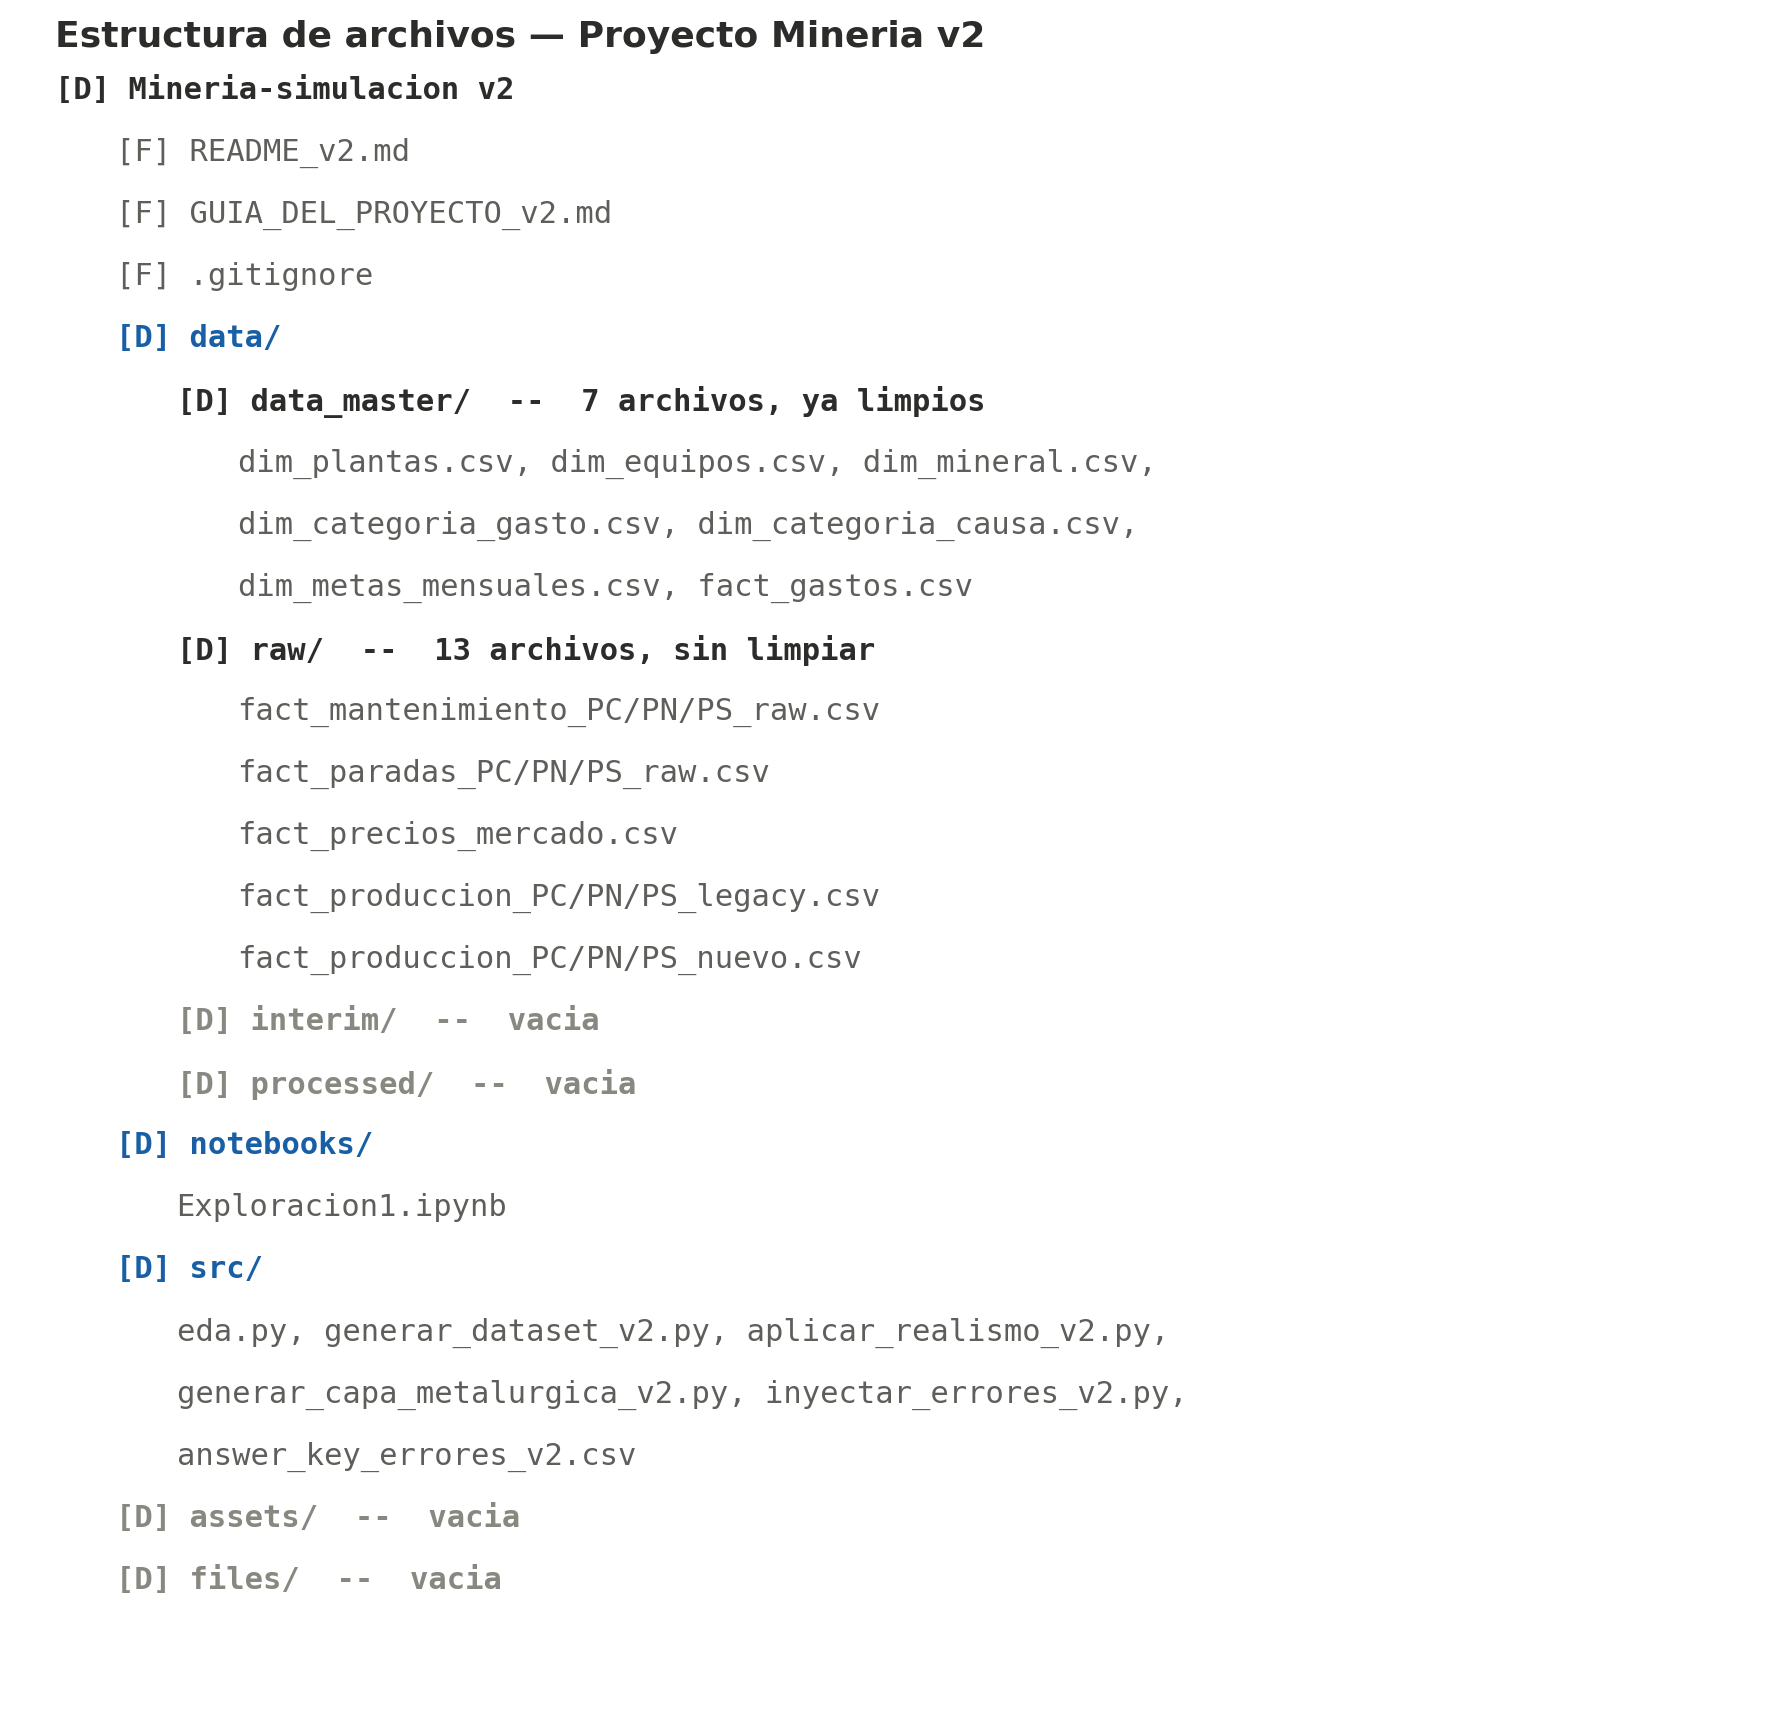

### 9.2 Concepto del negocio y KPIs principales

La v1 respondía "¿cómo está esta planta y qué equipo conviene atender primero?". La v2 agrega dos preguntas que solo existen con varias plantas: **¿qué planta rinde mejor y por qué?** y **¿cuánto de ese rendimiento llega al resultado financiero del grupo?** Para eso se conecta la disponibilidad de los equipos (confiabilidad) con el ingreso por venta de metales (producción mineral x precio de mercado) y con los gastos operativos de cada planta.

Los KPIs de la v1 (OEE, Disponibilidad, Rendimiento, Calidad, MTBF, MTTR, Costo de No Confiabilidad, Costo Evitable, Índice de Riesgo de Falla, Pareto ABC) se mantienen, ahora filtrables por planta. KPIs nuevos de la v2:

| KPI | Definición de negocio | ¿Por qué importa? |
| --- | --- | --- |
| Utilidad | Ingreso total (PEN) − gastos operativos − costo total de no confiabilidad | Une la confiabilidad de los equipos con el resultado económico de la planta |
| Margen de utilidad % | Utilidad / ingreso total (PEN) | Permite comparar plantas de distinto tamaño (capacidad 0.8x, 1.0x y 1.2x) |
| Ingreso por mineral | Fino recuperado de Cu, Zn y Ag x precio de mercado del día (USD) | Muestra qué metal sostiene el ingreso de cada planta |
| OEE Grupo y OEE vs Grupo (pp) | OEE de las plantas seleccionadas y diferencia en puntos porcentuales de cada planta contra ese valor | Ubica a cada planta frente al promedio del grupo |
| Ranking de plantas | Posición de cada planta por OEE, MTBF, MTTR y Utilidad (`RANKX` con empates densos) | Comparación de un vistazo en la matriz benchmark |
| % de contribución al grupo | Toneladas y Utilidad de la planta / total del grupo | Qué peso tiene cada planta en el total |
| Ley ponderada y Recuperación Cu % | Ley de cabeza ponderada por toneladas; fino recuperado / fino contenido | Indicadores metalúrgicos que explican por qué una planta vende más con las mismas toneladas |
| % Avance vs Meta | Toneladas reales / meta mensual de la planta (`dim_metas_mensuales`) | Cumplimiento del plan por planta |
| Precios de mercado | Cu, Zn y Ag (promedio del periodo) y tipo de cambio | Contexto compartido por las 3 plantas |

> Ley ponderada, Recuperación Cu %, % Avance vs Meta e ingreso por tonelada ya están definidos como medidas, pero todavía no tienen un visual propio en el dashboard (ver 9.5).

### 9.3 Medidas DAX utilizadas principales

Total inicial: **114 medidas** registradas (80 base y 34 adicionales). Tras la auditoría exhaustiva y depuración final de la **Versión 2.1**, se identificaron y eliminaron **34 medidas DAX huérfanas** que no intervenían en ningún visual ni cálculo dependiente, dejando el modelo con exactamente **80 medidas DAX activas y optimizadas** (100% en uso). Las 34 medidas removidas quedaron debidamente respaldadas en `medidas_dax_eliminadas_backup.tmdl`.

A continuación se resumen las medidas nuevas de la v2 por categoría y las medidas clave que rigen el dashboard:

| Categoría | N° medidas activas |
| --- | --- |
| Finanzas (ingresos por mineral, gastos, utilidad, margen, por tonelada) | 10 |
| Producción mineral y planta (toneladas planta, meta, fino recuperado) | 6 |
| Precios de mercado y tipo de cambio | 3 |
| Confiabilidad, MTBF, MTTR, Disponibilidad, Calidad, Rendimiento, OEE | 45 |
| Mantenimiento, Paradas, Costo No Confiabilidad, Horas Hombre y Pareto | 16 |

A continuación, las medidas clave más importantes y las adaptaciones que se realizaron para operar con 3 plantas simultáneas:

#### Finanzas: Utilidad y Margen
```text
Ingreso Total PEN = SUM(fact_ventas[ingreso_total_pen])

Gastos Operativos PEN = SUM(fact_gastos[monto_soles])

Utilidad = [Ingreso Total PEN] - [Gastos Operativos PEN] - [Costo Total No Confiabilidad]

Margen Utilidad % = DIVIDE([Utilidad], [Ingreso Total PEN], 0)
```
`Utilidad` descuenta el costo de no confiabilidad (paradas + repuestos) como una línea aparte de los gastos operativos: es la medida que traduce las fallas de los equipos a resultado económico. Como el ingreso y los gastos existen a grano planta-día, **`Utilidad` solo tiene sentido por planta y fecha**, no por equipo.

#### Rendimiento multi-planta
```text
Rendimiento =
VAR CapacidadReal = SUM(fact_produccion[toneladas_procesadas])
VAR CapacidadTeorica =
    SUMX(
        fact_produccion,
        fact_produccion[horas_operativas] * RELATED(dim_equipos[capacidad_nominal_tmh])
    )
RETURN DIVIDE(CapacidadReal, CapacidadTeorica, 0)
```
En la v1 la capacidad teórica era `horas_operativas x AVERAGE(capacidad_nominal_tmh)`. Con 3 plantas cada equipo tiene una capacidad distinta (factor 1.0, 0.8 y 1.2), y al filtrar por varios equipos o plantas el promedio de capacidades no pondera las horas de cada fila. `SUMX` con `RELATED` multiplica las horas de cada fila por la capacidad de su propio equipo. Como OEE = Disponibilidad x Rendimiento x Calidad, esta corrección se propaga al OEE de todas las páginas.

#### Costo promedio de área por planta
```text
Costo Promedio Area =
CALCULATE(
    AVERAGEX(VALUES(dim_equipos[equipo_id]), [Costo Total No Confiabilidad]),
    ALLEXCEPT(dim_equipos, dim_equipos[area], dim_equipos[planta_id])
)
```
El promedio del área ahora se calcula **dentro de cada planta** (`area` + `planta_id`). Sin ese cambio, un equipo de PN se compararía contra el promedio de las áreas de las tres plantas.

#### Índice de Riesgo de Falla
```text
@Indice Riesgo Falla =
VAR UltimaFecha = MAX(DimCalendario[Fecha])
VAR AnioRef = YEAR(UltimaFecha)
VAR HH = CALCULATE(
    SUM(fact_mantenimiento[horas_hombre]),
    DATESINPERIOD(DimCalendario[Fecha], UltimaFecha, -3, MONTH),
    REMOVEFILTERS(fact_paradas[causa])
)
VAR Fallas = CALCULATE(
    COUNTROWS(fact_paradas),
    fact_paradas[tipo_parada] = "CORRECTIVA",
    DATESINPERIOD(DimCalendario[Fecha], UltimaFecha, -3, MONTH),
    REMOVEFILTERS(fact_paradas[causa])
)
VAR Rep = CALCULATE(
    SUM(fact_mantenimiento[costo_repuestos_soles]),
    DATESINPERIOD(DimCalendario[Fecha], UltimaFecha, -3, MONTH),
    REMOVEFILTERS(fact_paradas[causa])
)
VAR Antiguedad = MAX(0, AnioRef - MAX(dim_equipos[anio_instalacion]))
RETURN (HH * 0.3) + (Fallas * 50) + (Rep * 0.002) + (Antiguedad * 8)
```
La antigüedad ya no usa `TODAY()`: se mide contra la última fecha del periodo seleccionado (dataset 2024-2027), asegurando comparabilidad temporal consistente.


## 9.4) Recorrido del dashboard

El dashboard tiene 6 páginas y 1 tooltip. Las páginas 2, 4, 5 y 6 vienen de la v1 (ahora con slicer de planta y equipos identificados como `nombre (planta)`); las páginas 1 y 3 son nuevas.

### PAGINA 1 **Pestaña: Executive Overview (Multi-Planta)** — nueva en v2

3 gráficos de barras (OEE, toneladas y utilidad por planta) + 5 tarjetas (OEE del grupo, toneladas, utilidad, margen y costo de no confiabilidad) + 1 matriz benchmark + 3 slicers (año, mes y planta).

La matriz tiene una fila por planta con Disponibilidad, Rendimiento, Calidad, OEE, MTBF, MTTR, toneladas, ingreso, gastos, utilidad y el ranking por OEE.
>Pregunta que responde: ¿qué planta rinde mejor, cuánto aporta cada una al resultado del grupo y en qué indicador se separan?

![Executive Overview](C:\Users\jbard\Desktop\Library\@CURSOS ACTUALES\@Data Analitycs\Python projects\Mineria-simulacion v2\assets/assets/Pagina_01.png)

### PAGINA 2 **Pestaña: Eficiencia Operacional & OEE** — evolución de "KPIs Principales" de la v1

6 gauges (Disponibilidad, Rendimiento, Calidad, OEE y 2 de participación de toneladas) + 9 tarjetas + 3 treemaps (OEE, toneladas y % de toneladas por equipo) + gráfico de línea de toneladas por año/mes + 2 gráficos de barras de costo por equipo + 5 slicers (año/mes, equipo, área y planta).
>Pregunta que responde: ¿cómo está la planta seleccionada en disponibilidad, rendimiento, calidad y OEE, y qué equipos concentran las toneladas y el costo de las paradas?

![Executive Overview](../assets/Pagina_01.png)

### PAGINA 3 **Pestaña: Finanzas & Precios de Mercado** — nueva en v2

5 tarjetas (ingreso total en USD, gastos operativos y precios de Cu, Zn y Ag) + gráfico de columnas de ingreso por mineral y por planta + 2 líneas con la evolución del precio del cobre y del zinc + tabla de fino recuperado e ingresos por planta + treemap de gastos por categoría + 3 slicers (año, mes y planta).
>Pregunta que responde: ¿cuánto vende cada planta, con qué mezcla de metales y cuánto cuesta operarla, frente a un precio de mercado que es el mismo para las tres?

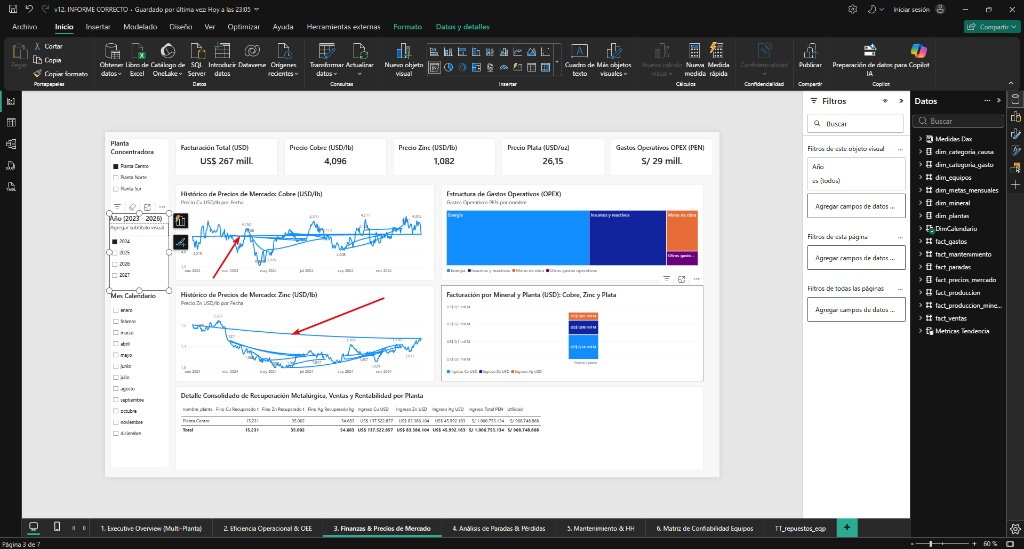

### PAGINA 4 **Pestaña: Análisis de Paradas & Pérdidas**

Gráfico circular (% de paradas correctivas, operativas y preventivas) + 3 gráficos de barras/columnas por causa y tipo de parada + gráfico combinado de repuestos por equipo + 3 grupos de tarjetas (horas promedio, horas hombre y conteo por tipo de parada) + 4 slicers (año/mes, tipo de parada y planta).
>Pregunta que responde: ¿qué tipos y causas de parada consumen más horas y costo, y cómo cambia ese patrón según la planta?

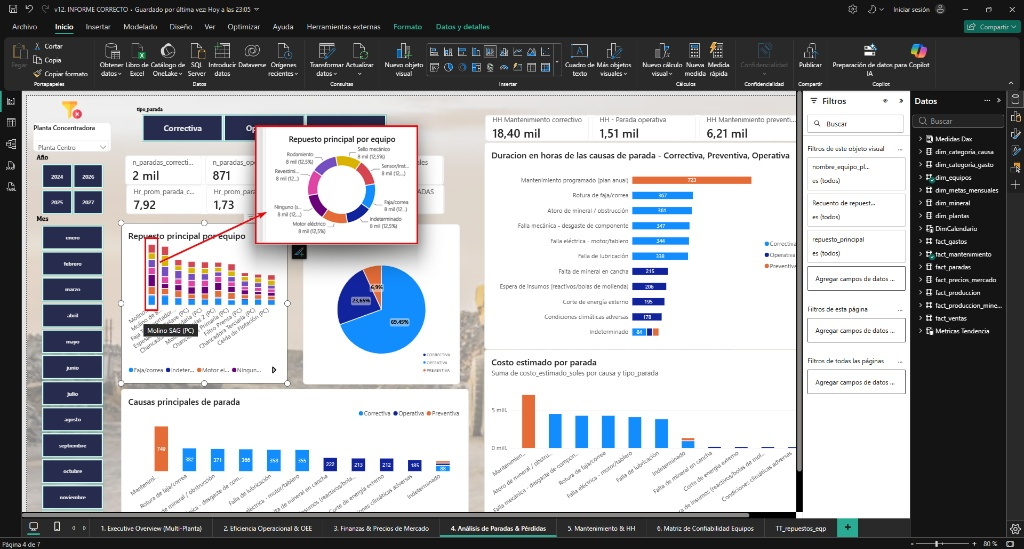

### PAGINA 4 **Pestaña: Paradas - TOOLTIP**

**Pestaña: TT_repuestos_eqp**
Donut chart de costo de repuestos por tipo de repuesto, que aparece al pasar el cursor sobre un equipo. Pregunta que responde: ¿qué repuesto concentra el gasto de ese equipo?

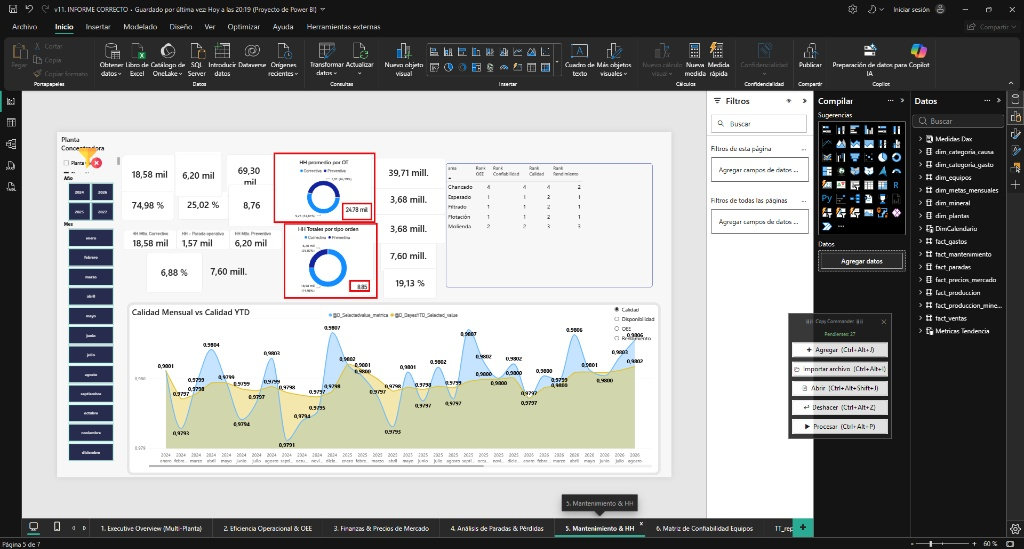

### PAGINA 5 **Pestaña: Mantenimiento & HH**

16 tarjetas (horas hombre preventivas y correctivas, % de cada una, horas promedio por orden, costo promedio, costo evitable y ahorro potencial) + 2 donut charts por tipo de orden + gráfico de área con métrica seleccionable y acumulado del año (YTD) + tabla de rankings por área + 3 slicers y un selector de métrica.
>Pregunta que responde: ¿cómo se reparte la carga de horas hombre entre mantenimiento preventivo y correctivo, cuál es el costo asociado y cuánto se podría ahorrar llevando cada equipo al promedio de su área y planta?

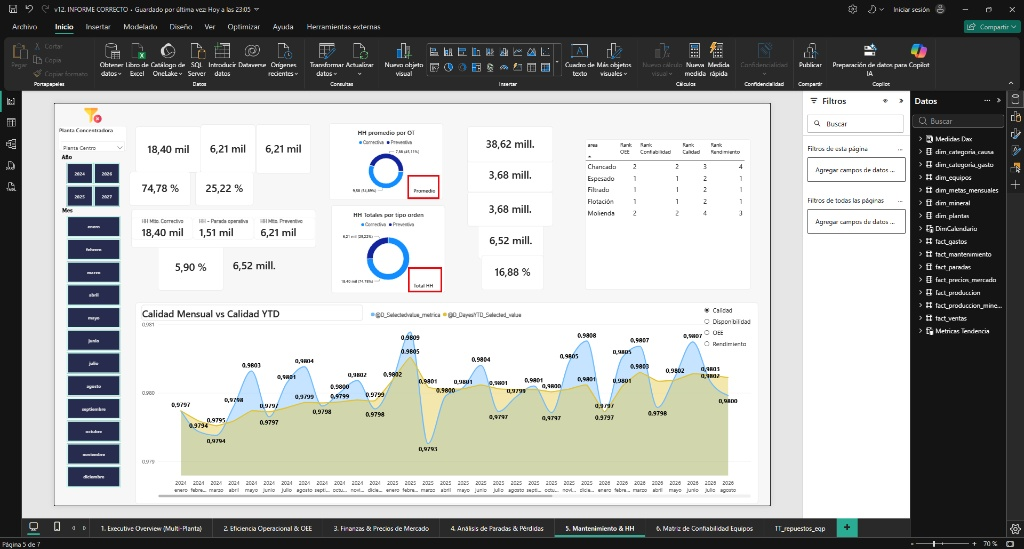

### PAGINA 6 **Pestaña: Matriz de Confiabilidad Equipos**

Gráfico de dispersión (índice de riesgo vs MTBF, con el costo evitable como tamaño) + 2 gauges + tabla por equipo (índice de riesgo, MTBF, costo evitable y ahorro %) + gráfico Pareto de causas + gráfico de área + 6 tarjetas + 5 slicers (año/mes, categoría de riesgo y planta).
>Pregunta que responde: ¿qué equipo, de cualquiera de las tres plantas, tiene mayor riesgo de falla y cuánto costo se podría evitar si se le atiende primero?

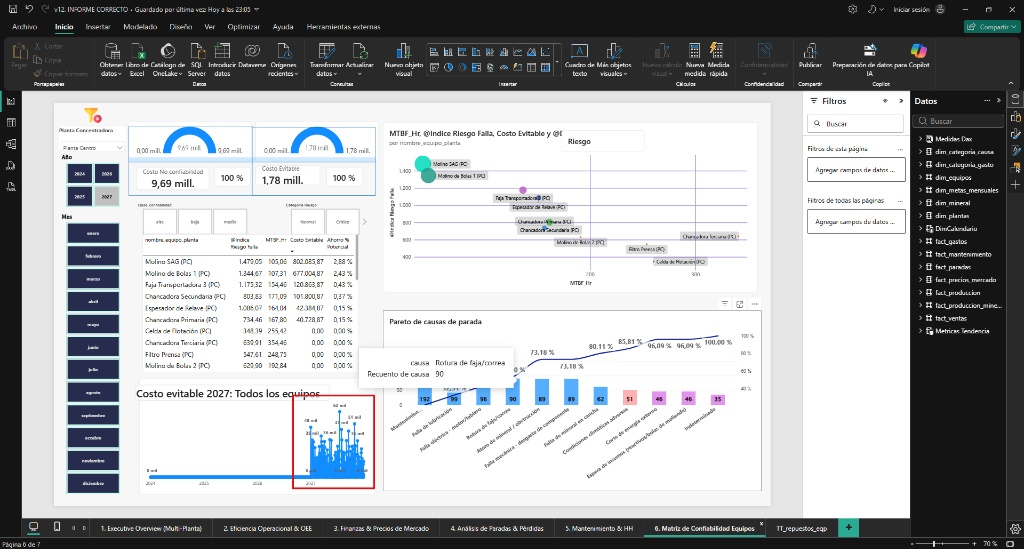

### 9.5 Decisiones y limitaciones documentadas

- **Dos medidas de toneladas con alcance distinto:** `Total toneladas procesadas` suma las toneladas de los 10 equipos de `fact_produccion` y sirve para comparar equipos entre sí. `Toneladas Planta` toma las toneladas de la celda de flotación (EQ-07) de `fact_produccion_mineral` y representa lo que realmente pasa por la planta; es la base del ingreso y las metas globales. No son intercambiables a nivel planta, porque la suma de los 10 equipos cuenta la misma tonelada en varias etapas del proceso.
- **`Utilidad` no se interpreta por equipo:** Ingresos y gastos existen a grano planta-día; el costo de no confiabilidad sí baja a equipo, pero la utilidad consolidada solo es válida por planta y periodo.
- **Costo de no confiabilidad:** `costo_estimado_soles` conserva 411 nulos en `fact_paradas` (sección 6); `SUM` los ignora de forma estándar, por lo que el costo de paradas y con él `Utilidad` reflejan las órdenes y eventos con registro monetario explícito.
- **Horas sin registro:** Los 11 huecos operativos de `fact_produccion` (3 en PC, 3 en PS y 5 en PN, sección 3) no se imputaron: no aportan horas a la Disponibilidad ni toneladas al Rendimiento, manteniendo la rigurosidad de auditoría.
- **Depuración de medidas huérfanas en versión 2.1:** Las 34 medidas DAX que no se utilizaban en ningún visual ni tenían dependencias (metalurgia no graficada, rankings secundarios, comparaciones temporales y medidas de prueba) fueron completamente depuradas del modelo activo para garantizar un archivo ágil y limpio de 80 medidas, quedando respaldadas en `medidas_dax_eliminadas_backup.tmdl`.
- **Integridad y validación de visuales:** Las 291 referencias a columnas y medidas en los visuales de las 7 páginas del informe resuelven al 100% sin campos rotos.


## 10) AUDITORÍA FINAL, DEPURACIÓN Y OPTIMIZACIÓN DEL PROYECTO (VERSIÓN 2.1)

### 10.1 Diagnóstico y Proyecto Activo Consolidado
Se auditó y consolidó el proyecto sobre la versión activa oficial: **`v12. INFORME CORRECTO`**. Tras revisar exhaustivamente dependencias, visuales, filtros y tablas, se procedió a una limpieza integral para dejar una versión de producción definitiva.

- **Tamaño de entrega:** Reducción drástica de **84 MB** originales a **16 MB** en el paquete limpio (.zip), eliminando redundancias y archivos residuales.
- **Estado de Medidas DAX:** De 114 medidas registradas, se eliminaron **34 medidas huérfanas**, dejando **80 medidas DAX activas** en el modelo tabular.
- **Integridad Visual:** Se verificaron las **291 referencias** de los componentes visuales hacia el modelo de datos; el 100% de los visuales resuelve correctamente (0 roturas o advertencias).
- **Consistencia de Reporte:** Las **7 páginas** están registradas en `pageOrder` (6 páginas de analítica ejecutiva/operativa + 1 página de Tooltip interactivo). Se eliminó cualquier placeholder temporal.

---

### 10.2 Resumen de Componentes Eliminados en la Limpieza
Para garantizar la pulcritud y peso óptimo del repositorio se suprimieron:

1. **Iteraciones anteriores y backups:** Carpeta `_archivo_iteraciones/` completa (versiones V9, V10, V11, backups intermedios y scripts de parcheo `.ps1` y `.py`).
2. **Histórico de auditorías:** Carpeta `AUDITORIAS/` completa (más de 20 zips y entregas intermedias).
3. **Scripts de parcheo sueltos:** `fix_cardvisual_details.py`, `set_pareto_line_color.py`, `LEEME_PARCHE_PAGINA5.txt` y `recargar_fact_gastos_sql.py`. El archivo maestro `fact_gastos.csv` regenerado permanece en `data_master`.
4. **Notebooks desactualizados:** Carpeta `dashboard resumen/` vieja, recuperando su arquitectura y capturas para consolidarlas en esta versión `2.1`.
5. **Archivos temporales locales:** Cachés `__pycache__`, accesos directos de Windows `.lnk` y el archivo `cache.abf` del Semantic Model (que se regenera automáticamente al refrescar contra SQL Server).

---

### 10.3 Clasificación de las 34 Medidas DAX Huérfanas Eliminadas
Las medidas depuradas no intervenían en ningún gráfico, tarjeta, gauge, matriz, tooltip ni en otras medidas conservadas:

* **Bloque Metalurgia (11 medidas sin visual asignado):**
  - `Ley Cu Cabeza %`, `Ley Cu Concentrado %`, `Ley Ag Cabeza oz/t`, `Ley Zn Cabeza %`, `Recuperacion Cu %`, `Concentrado Cu t`, `Fino Cu Contenido t`, `Fino Cu Recuperado t`, `Meta Toneladas Planta % Avance`, etc.
* **Bloque Rankings y Comparativos de Planta (8 medidas):**
  - `Rank Planta OEE`, `Rank Planta MTBF`, `Rank Planta MTTR`, `Rank Planta Utilidad`, `% del grupo`, `OEE vs Grupo (pp)`, `Toneladas Planta % Grupo`, etc.
* **Bloque Pruebas, Tendencias y Restos (15 medidas):**
  - `Chequeo_Fechas_Huerfanas`, `OEE_LY_*`, `Tendencia_DatesYTD_OEE`, `pareto4_% del_total`, `pareto5_Clasificacion_ABC`, medidas vacías temporales (`Medida`, `Medida 2`), etc.

> **Respaldo:** Todas las fórmulas DAX completas de estas 34 medidas se conservan en el archivo `medidas_dax_eliminadas_backup.tmdl` dentro de la carpeta `2.1` por si se requiere reactivar alguna en futuras expansiones.

---

### 10.4 Verificaciones Técnicas Realizadas
| Componente | Estado Pre-Limpieza | Estado Post-Limpieza (v2.1) | Resultado |
| :--- | :---: | :---: | :---: |
| **Medidas DAX Huérfanas** | 34 huérfanas | 0 huérfanas | Depuración limpia (80 activas) |
| **Referencias en Visuales** | 291 referencias | 291 referencias | 100% funcionales (0 rotas) |
| **Estructura TMDL** | Estándar | Intacta (saltos, lineageTags y particiones) | Válido y consistente |
| **Páginas del Reporte** | 7 páginas | 7 páginas en pageOrder | Sin páginas vacías ni placeholders |
| **Tamaño de Entrega** | 84 MB | 16 MB | Optimización de espacio (-81%) |

---

### 10.5 Instrucciones de Despliegue para el Usuario
1. **Refrescar Datos:** Al abrir el proyecto `v12. INFORME CORRECTO.pbip` en Power BI Desktop, hacer clic en **Refrescar** en la cinta de opciones superior. Como se retiró el `cache.abf` desactualizado, Power BI consultará las 13 tablas en SQL Server (`mineria_v2`) y recreará el caché local de forma óptima.
2. **Página de Apertura:** El archivo `pages.json` mantiene activa `TT_repuestos_eqp` (el tooltip de 320x240 px). Se recomienda seleccionar la **Página 1 (Executive Overview)** antes de guardar o publicar en el Power BI Service.
3. **Repositorio Git:** El subdirectorio de simulación `Mineria-simulacion v2` conserva su repositorio `.git` sin modificaciones estructurales.
